<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_12_/Copy_of_CAMM_Hackaton_12_Kalinin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAMM Hackathon 12: Real-Time Drift Correction

In this challenge, the image is acquired line-by-line while the sample drifts. Your goal is to estimate that drift online and correct the image as the scan arrives.

## Task

Build a method that, for each newly acquired scan line:

- estimates the current drift
- updates the reconstructed image in real time
- produces a corrected final image

Keep the solution simple and fast enough to run during acquisition.

## What is provided

This notebook gives you:

- one STEM image to use as source data
- several synthetic drift models
- a simulator that corrupts the image line-by-line
- a streaming generator that mimics real-time acquisition

You only need to focus on the correction strategy.

## 1. Setup

In [1]:
# Install dependencies (Colab / fresh environment)
!pip -q install SciFiReaders gdown


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.0/128.0 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.9/69.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.0/150.0 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 k

In [2]:
from pathlib import Path

file_id = "16Oavm1j0gcGR2mPXWCAqLfVm1MSngy1Z"
filename = "1547 STEM 1.45 Mx HAADF 0001.emd"

if not Path(filename).exists():
    !gdown {file_id} -O "{filename}"
else:
    print(f"Using existing file: {filename}")


Downloading...
From: https://drive.google.com/uc?id=16Oavm1j0gcGR2mPXWCAqLfVm1MSngy1Z
To: /content/1547 STEM 1.45 Mx HAADF 0001.emd
100% 8.85M/8.85M [00:00<00:00, 68.4MB/s]


## 2. Imports

In [3]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output
from SciFiReaders import EMDReader


## 3. Drift Models

These helper functions generate different drift trajectories. They are provided for testing and benchmarking.

In [4]:
#@title drift models




def drift_constant_velocity(
    n_lines: int,
    vx: float = 0.02,
    vy: float = 0.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Constant-velocity drift.

    Model:
        ux(t) = u0x + vx * t
        uy(t) = u0y + vy * t

    Parameters
    ----------
    n_lines : int
        Number of scan lines.
    vx, vy : float
        Drift velocity in pixels per unit time.
    dt : float
        Time step per line.
    u0x, u0y : float
        Initial drift offsets in pixels.

    Returns
    -------
    t : ndarray, shape (n_lines,)
        Time axis.
    ux, uy : ndarray, shape (n_lines,)
        Drift trajectory in pixels.
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + vx * t
    uy = u0y + vy * t
    return t, ux, uy


def drift_constant_velocity_random_walk(
    n_lines: int,
    vx0: float = 0.02,
    vy0: float = 0.0,
    sigma_ax: float = 0.002,
    sigma_ay: float = 0.002,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
    seed: int | None = None,
):
    """
    Constant-velocity model with random-walk velocity.

    State evolution:
        vx[t+1] = vx[t] + eps_x
        vy[t+1] = vy[t] + eps_y
        ux[t+1] = ux[t] + vx[t] * dt
        uy[t+1] = uy[t] + vy[t] * dt

    This is a very good default Kalman-style drift model.

    Parameters
    ----------
    n_lines : int
        Number of scan lines.
    vx0, vy0 : float
        Initial velocities in pixels per unit time.
    sigma_ax, sigma_ay : float
        Std of velocity perturbation per step.
    dt : float
        Time step per line.
    u0x, u0y : float
        Initial offsets.
    seed : int or None
        Random seed.

    Returns
    -------
    t, ux, uy : ndarray
        Time axis and drift trajectories.
    """
    rng = np.random.default_rng(seed)

    t = np.arange(n_lines, dtype=float) * dt
    ux = np.zeros(n_lines, dtype=float)
    uy = np.zeros(n_lines, dtype=float)
    vx = np.zeros(n_lines, dtype=float)
    vy = np.zeros(n_lines, dtype=float)

    ux[0], uy[0] = u0x, u0y
    vx[0], vy[0] = vx0, vy0

    for i in range(1, n_lines):
        vx[i] = vx[i - 1] + rng.normal(0.0, sigma_ax)
        vy[i] = vy[i - 1] + rng.normal(0.0, sigma_ay)

        ux[i] = ux[i - 1] + vx[i - 1] * dt
        uy[i] = uy[i - 1] + vy[i - 1] * dt

    return t, ux, uy


def drift_creep_log(
    n_lines: int,
    ax: float = 2.0,
    ay: float = 0.5,
    tau_x: float = 20.0,
    tau_y: float = 20.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Logarithmic creep-like drift.

    Model:
        ux(t) = u0x + ax * log(1 + t / tau_x)
        uy(t) = u0y + ay * log(1 + t / tau_y)

    Useful as a simple AFM-like creep surrogate.

    Parameters
    ----------
    ax, ay : float
        Drift amplitudes in pixels.
    tau_x, tau_y : float
        Characteristic time scales.

    Returns
    -------
    t, ux, uy : ndarray
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + ax * np.log1p(t / tau_x)
    uy = u0y + ay * np.log1p(t / tau_y)
    return t, ux, uy


def drift_creep_exponential(
    n_lines: int,
    ax: float = 2.0,
    ay: float = 0.5,
    tau_x: float = 30.0,
    tau_y: float = 30.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Exponential relaxation / creep model.

    Model:
        ux(t) = u0x + ax * (1 - exp(-t / tau_x))
        uy(t) = u0y + ay * (1 - exp(-t / tau_y))

    Good when drift is strongest at the beginning and saturates.

    Returns
    -------
    t, ux, uy : ndarray
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + ax * (1.0 - np.exp(-t / tau_x))
    uy = u0y + ay * (1.0 - np.exp(-t / tau_y))
    return t, ux, uy


def drift_oscillatory(
    n_lines: int,
    ax: float = 5*0.5,
    ay: float = 5*0.2,
    freq_x: float = 0.02,
    freq_y: float = 0.03,
    phase_x: float = 0.0,
    phase_y: float = 0.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Oscillatory drift model.

    Model:
        ux(t) = u0x + ax * sin(2*pi*freq_x*t + phase_x)
        uy(t) = u0y + ay * sin(2*pi*freq_y*t + phase_y)

    Useful as a toy vibration / periodic instability component.

    Parameters
    ----------
    ax, ay : float
        Oscillation amplitudes in pixels.
    freq_x, freq_y : float
        Frequencies in cycles per unit time.

    Returns
    -------
    t, ux, uy : ndarray
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + ax * np.sin(2 * np.pi * freq_x * t + phase_x)
    uy = u0y + ay * np.sin(2 * np.pi * freq_y * t + phase_y)
    return t, ux, uy


def drift_composite(
    n_lines: int,
    dt: float = 1.0,
    linear_vx: float = 0.01,
    linear_vy: float = 0.0,
    creep_ax: float = 1.0,
    creep_ay: float = 0.3,
    creep_tau_x: float = 25.0,
    creep_tau_y: float = 25.0,
    osc_ax: float = 0.1,
    osc_ay: float = 0.05,
    osc_freq_x: float = 0.02,
    osc_freq_y: float = 0.015,
    phase_x: float = 0.0,
    phase_y: float = 0.0,
    noise_sigma_x: float = 0.02,
    noise_sigma_y: float = 0.02,
    u0x: float = 0.0,
    u0y: float = 0.0,
    seed: int | None = None,
):
    """
    Composite drift model:
    linear trend + creep + oscillation + small random noise.

    This is often the most realistic general-purpose simulator.

    Returns
    -------
    t, ux, uy : ndarray
    """
    rng = np.random.default_rng(seed)
    t = np.arange(n_lines, dtype=float) * dt

    linear_x = linear_vx * t
    linear_y = linear_vy * t

    creep_x = creep_ax * (1.0 - np.exp(-t / creep_tau_x))
    creep_y = creep_ay * (1.0 - np.exp(-t / creep_tau_y))

    osc_x = osc_ax * np.sin(2 * np.pi * osc_freq_x * t + phase_x)
    osc_y = osc_ay * np.sin(2 * np.pi * osc_freq_y * t + phase_y)

    noise_x = rng.normal(0.0, noise_sigma_x, size=n_lines)
    noise_y = rng.normal(0.0, noise_sigma_y, size=n_lines)

    ux = u0x + linear_x + creep_x + osc_x + noise_x
    uy = u0y + linear_y + creep_y + osc_y + noise_y

    return t, ux, uy

### Visualize example drift trajectories

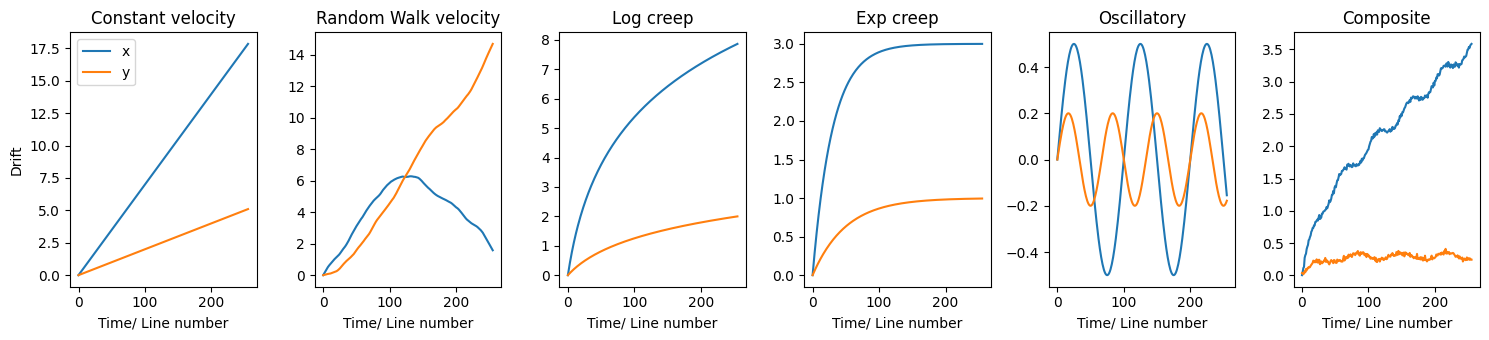

In [5]:
import matplotlib.pyplot as plt

n_lines = 256

fig, axes = plt.subplots(1, 6, figsize=(15, 3.5))

# --- 1. Constant velocity ---
t, ux1, uy1 = drift_constant_velocity(n_lines, vx=0.07, vy=0.02)
axes[0].plot(t, ux1, label='x')
axes[0].plot(t, uy1, label='y')
axes[0].legend()
axes[0].set_title("Constant velocity")

# --- 2. Random walk velocity ---
t, ux2, uy2 = drift_constant_velocity_random_walk(
    n_lines,
    vx0=0.07,
    vy0=0.01,
    sigma_ax=0.005,
    sigma_ay=0.005,
    seed=0
)
axes[1].plot(t, ux2, label='x')
axes[1].plot(t, uy2, label='y')
axes[1].set_title("Random Walk velocity")

# --- 3. Log creep ---
t, ux3, uy3 = drift_creep_log(n_lines, ax=3.0, ay=1.0, tau_x=20, tau_y=40)
axes[2].plot(t, ux3)
axes[2].plot(t, uy3)
axes[2].set_title("Log creep")

# --- 4. Exp creep ---
t, ux4, uy4 = drift_creep_exponential(n_lines, ax=3.0, ay=1.0, tau_x=30, tau_y=50)
axes[3].plot(t, ux4)
axes[3].plot(t, uy4)
axes[3].set_title("Exp creep")

# --- 5. Oscillatory ---
t, ux5, uy5 = drift_oscillatory(
    n_lines, ax=0.5, ay=0.2, freq_x=0.01, freq_y=0.015
)
axes[4].plot(t, ux5)
axes[4].plot(t, uy5)
axes[4].set_title("Oscillatory")

# --- 6. Composite ---
t, ux6, uy6 = drift_composite(n_lines, seed=2)
axes[5].plot(t, ux6)
axes[5].plot(t, uy6)
axes[5].set_title("Composite")

# --- formatting ---
for ax in axes:
    #ax.set_xticks([])   # cleaner
    #ax.set_yticks([])
    ax.set_xlabel("Time/ Line number")


#axes[0].set_xlabel("Time")
axes[0].set_ylabel("Drift")


fig.tight_layout()
plt.show()

## 4. Load the Source Image

In [6]:
emd_path = Path("1547 STEM 1.45 Mx HAADF 0001.emd")
reader = EMDReader(str(emd_path))
data = reader.read()

haadf_data = data["Channel_000"][:]
print("Loaded image shape:", haadf_data.shape)


Loaded image shape: (2048, 2048)


## 5. Drift Simulator

This helper creates a corrupted scan from a clean image and returns the ground-truth drift used to generate it.

In [7]:
import numpy as np
from dataclasses import dataclass
from typing import Callable, Any
from scipy.ndimage import map_coordinates


@dataclass
class DriftSimulationResult:
    cropped_reference: np.ndarray
    cropped_corrupted: np.ndarray
    t: np.ndarray
    ux: np.ndarray
    uy: np.ndarray
    model_name: str
    model_kwargs: dict[str, Any]
    crop_bbox: tuple[int, int, int, int]  # y0, y1, x0, x1


def simulate_scan_drift_cropped_output(
    image: np.ndarray,
    model: str | Callable[..., tuple[np.ndarray, np.ndarray, np.ndarray]],
    model_kwargs: dict | None = None,
    out_shape: tuple[int, int] | None = None,
    dt: float = 1.0,
    interpolation_order: int = 1,
    extra_margin: int = 2,
    drift_models: dict[str, Callable] | None = None,
):
    """
    Simulate line-by-line drift, but return only a central cropped output.
    Important: drifted sampling is performed from the FULL image, not from a pre-cropped image.

    Parameters
    ----------
    image : np.ndarray
        Input 2D image.
    model : str or callable
        Drift model name or callable returning (t, ux, uy).
    model_kwargs : dict or None
        Parameters for drift model.
    out_shape : tuple[int, int] or None
        Output cropped shape (H, W). If None, use the maximal safe central crop.
    dt : float
        Time step per line.
    interpolation_order : int
        Interpolation order for map_coordinates.
    extra_margin : int
        Extra safety pixels beyond max drift.
    drift_models : dict or None
        Optional registry of named drift models.

    Returns
    -------
    DriftSimulationResult
    """
    if image.ndim != 2:
        raise ValueError("image must be a 2D array")

    H, W = image.shape
    model_kwargs = {} if model_kwargs is None else dict(model_kwargs)

    if drift_models is None:
        drift_models = {
            "constant_velocity": drift_constant_velocity,
            "random_walk_velocity": drift_constant_velocity_random_walk,
            "creep_log": drift_creep_log,
            "creep_exponential": drift_creep_exponential,
            "oscillatory": drift_oscillatory,
            "composite": drift_composite,
        }

    # resolve model
    if isinstance(model, str):
        if model not in drift_models:
            raise ValueError(f"Unknown model '{model}'. Available: {list(drift_models)}")
        model_fn = drift_models[model]
        model_name = model
    else:
        model_fn = model
        model_name = getattr(model, "__name__", "custom_model")

    # determine number of lines
    if out_shape is not None:
        out_h, out_w = out_shape
        model_kwargs["n_lines"] = out_h
    else:
        model_kwargs.setdefault("n_lines", H)

    model_kwargs.setdefault("dt", dt)

    # generate drift
    t, ux, uy = model_fn(**model_kwargs)
    ux = np.asarray(ux, dtype=float)
    uy = np.asarray(uy, dtype=float)

    if ux.shape != uy.shape:
        raise ValueError("ux and uy must have the same shape")

    n_lines = len(ux)

    # safe crop margins
    margin_x = int(np.ceil(np.max(np.abs(ux)))) + extra_margin
    margin_y = int(np.ceil(np.max(np.abs(uy)))) + extra_margin

    safe_h = H - 2 * margin_y
    safe_w = W - 2 * margin_x

    if safe_h <= 0 or safe_w <= 0:
        raise ValueError("Image too small for requested drift magnitude")

    if out_shape is None:
        out_h = min(n_lines, safe_h)
        out_w = safe_w
    else:
        out_h, out_w = out_shape
        if n_lines != out_h:
            raise ValueError(
                f"len(ux)={n_lines} must match out_shape[0]={out_h}"
            )
        if out_h > safe_h or out_w > safe_w:
            raise ValueError(
                f"Requested out_shape={out_shape} exceeds safe crop {(safe_h, safe_w)}"
            )

    # define central crop in the reference image
    y0 = (H - out_h) // 2
    x0 = (W - out_w) // 2
    y1 = y0 + out_h
    x1 = x0 + out_w

    cropped_reference = image[y0:y1, x0:x1]

    # simulate corrupted cropped output using FULL image coordinates
    cropped_corrupted = np.zeros((out_h, out_w), dtype=float)
    x_local = np.arange(out_w, dtype=float)

    for i in range(out_h):
        y_full = np.full(out_w, y0 + i + uy[i], dtype=float)
        x_full = x0 + x_local + ux[i]

        cropped_corrupted[i] = map_coordinates(
            image,
            [y_full, x_full],
            order=interpolation_order,
            mode="nearest",
        )

    return DriftSimulationResult(
        cropped_reference=cropped_reference,
        cropped_corrupted=cropped_corrupted,
        t=t[:out_h],
        ux=ux[:out_h],
        uy=uy[:out_h],
        model_name=model_name,
        model_kwargs=model_kwargs,
        crop_bbox=(y0, y1, x0, x1),
    )

## 6. Create a Sample Drifted Image

Use this synthetic example to develop and debug your method.

In [8]:
result = simulate_scan_drift_cropped_output(
    image=haadf_data,
    model="oscillatory",

    model_kwargs = {"ax":1.5, "ay":0.4, "freq_x":0.01, "freq_y":0.015,},


    #model_kwargs={
        #"vx0": 0.13,
        #"vy0": 0.17,
        #"sigma_ax": 0.03,
        #"sigma_ay": 0.03,
        #"seed": 1,

    #},

    out_shape=(256, 256),
    interpolation_order=1,
    extra_margin=3,
)

img_ref = result.cropped_reference
img_cor = result.cropped_corrupted
ux = result.ux
uy = result.uy


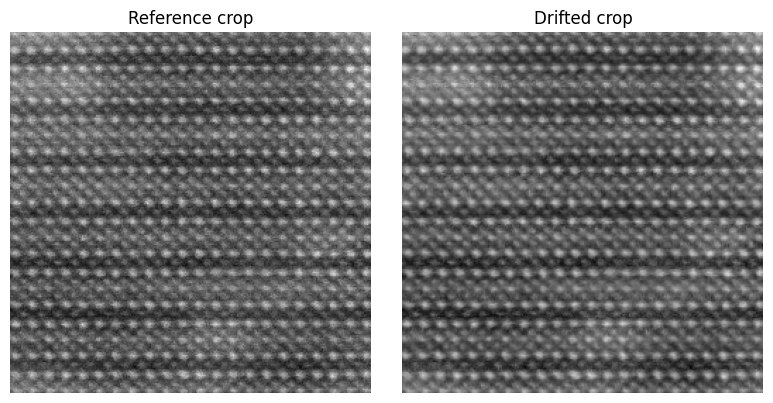

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_ref, cmap="gray")
axes[0].set_title("Reference crop")
axes[0].axis("off")

axes[1].imshow(img_cor, cmap="gray")
axes[1].set_title("Drifted crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## 7. Streaming Interface

The function below yields the scan one line at a time, like a live acquisition stream.

In [10]:
from typing import Callable, Any, Iterator

def corrupted_image_scan_stream(
    corrupted_image: np.ndarray,
    true_ux: np.ndarray | None = None,
    true_uy: np.ndarray | None = None,
) -> Iterator[dict]:
    """
    Yield scan progress line-by-line.

    Returns a dict containing:
    - current line index
    - current line
    - partial image acquired so far
    - optional true drift
    """
    if corrupted_image.ndim != 2:
        raise ValueError("corrupted_image must be a 2D array")

    H, W = corrupted_image.shape
    partial = np.full((H, W), np.nan, dtype=float)

    for i in range(H):
        partial[i] = corrupted_image[i]

        item = {
            "line_index": i,
            "line": corrupted_image[i].copy(),
            "partial_image": partial.copy(),
        }

        if true_ux is not None:
            item["ux_true"] = float(true_ux[i])
        if true_uy is not None:
            item["uy_true"] = float(true_uy[i])

        yield item

## 8. Your Code

Suggested outputs:

- corrected image
- estimated drift versus line index
- short note on your approach and assumptions

### FFT correction X

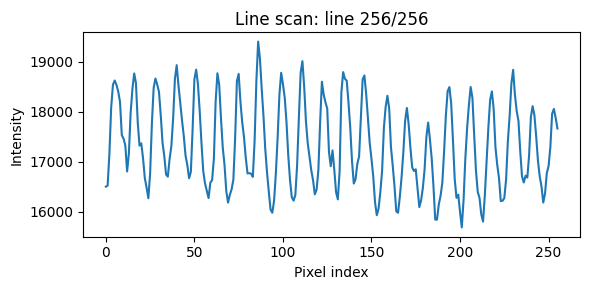

In [11]:
from IPython.display import clear_output
import matplotlib.pyplot as plt
import time

stream = corrupted_image_scan_stream(img_cor)

for _ in range(len(img_cor)):
    frame = next(stream)
    clear_output(wait=True)

    plt.figure(figsize=(6, 3))
    plt.plot(frame["line"])
    plt.title(f"Line scan: line {frame['line_index'] + 1}/{len(img_cor)}")
    plt.xlabel("Pixel index")
    plt.ylabel("Intensity")
    plt.tight_layout()
    plt.show()

    time.sleep(0.05)

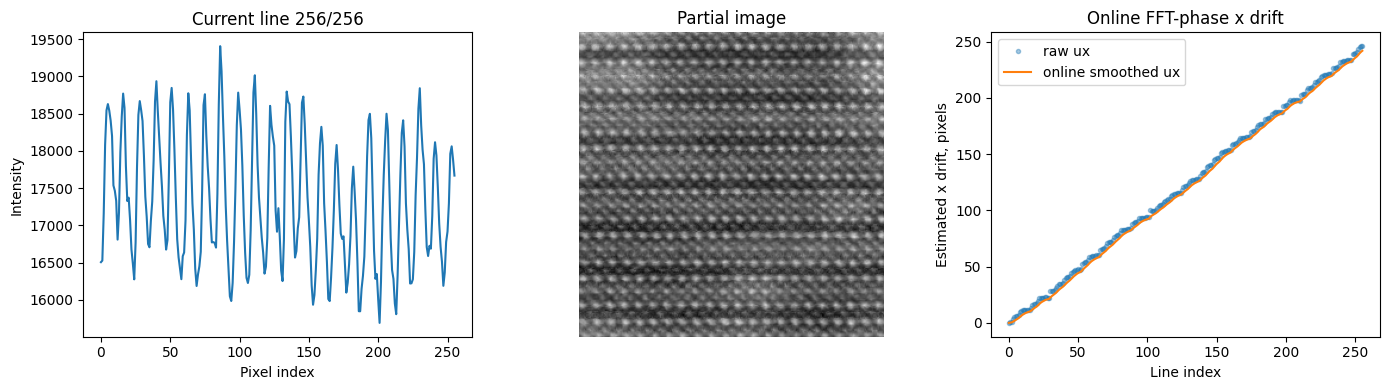

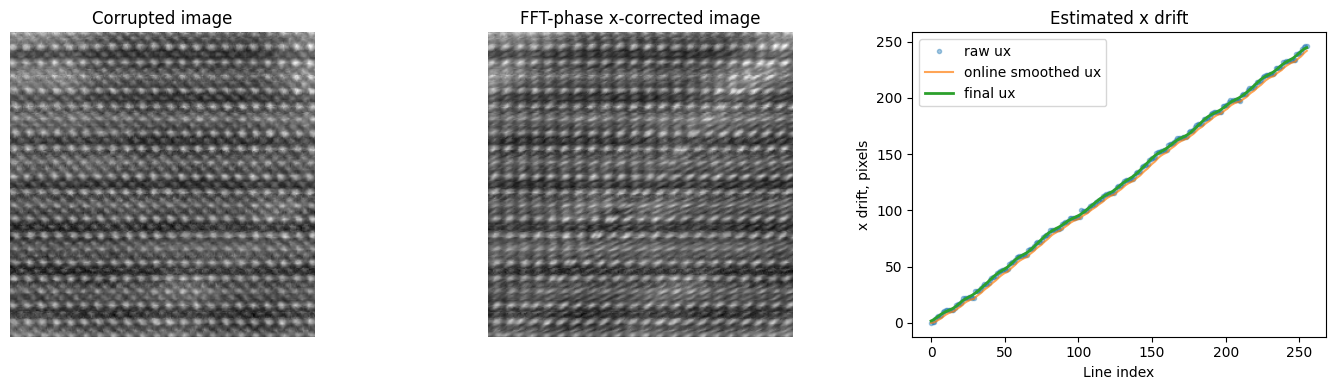

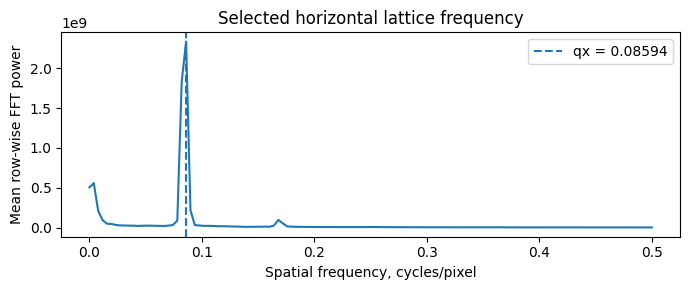

In [12]:
# ============================================================
# FFT-phase x-drift estimation from existing scan stream
# Assumes corrupted_image_scan_stream(img_cor) is already defined
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter1d, map_coordinates
from IPython.display import clear_output


# ------------------------------------------------------------
# Estimate dominant horizontal lattice frequency qx
# ------------------------------------------------------------

def estimate_dominant_qx(img, qmin=0.02, qmax=0.45, use_window=True):
    """
    Estimate dominant horizontal spatial frequency from row-wise FFT.
    Returns qx in cycles/pixel.
    """

    img = np.asarray(img, dtype=float)
    H, W = img.shape

    data = np.nan_to_num(img, nan=np.nanmedian(img))
    data = data - np.mean(data, axis=1, keepdims=True)

    if use_window:
        data = data * np.hanning(W)[None, :]

    F = np.fft.rfft(data, axis=1)
    power = np.mean(np.abs(F) ** 2, axis=0)

    freqs = np.fft.rfftfreq(W, d=1.0)

    valid = (freqs >= qmin) & (freqs <= qmax)
    valid[0] = False

    k0 = np.argmax(power * valid)
    qx = freqs[k0]

    return qx, k0, freqs, power


# ------------------------------------------------------------
# Online FFT phase tracker
# ------------------------------------------------------------

class OnlineFFTPhaseXDriftTracker:
    """
    Track x drift line-by-line using phase of one Fourier component.

    If line signal is approximately:

        I(x, y) ~ cos(2*pi*qx*(x - ux(y)))

    then:

        ux(y) = -Delta phase(y) / (2*pi*qx)
    """

    def __init__(self, width, qx, alpha=0.2, use_window=True):
        self.width = width
        self.qx = qx
        self.alpha = alpha

        x = np.arange(width)

        self.window = np.hanning(width) if use_window else np.ones(width)
        self.reference_wave = np.exp(-2j * np.pi * qx * x)

        self.prev_phase_wrapped = None
        self.prev_phase_unwrapped = None
        self.phase0 = None
        self.ux_smoothed = None

        self.history = {
            "phase": [],
            "amplitude": [],
            "ux_raw": [],
            "ux_smooth": [],
        }

    def update(self, line):
        line = np.asarray(line, dtype=float)
        line = np.nan_to_num(line, nan=np.nanmedian(line))
        line = line - np.mean(line)

        coeff = np.sum(line * self.window * self.reference_wave)

        phase_wrapped = np.angle(coeff)
        amplitude = np.abs(coeff)

        if self.prev_phase_wrapped is None:
            phase_unwrapped = phase_wrapped
            self.phase0 = phase_unwrapped
        else:
            delta = phase_wrapped - self.prev_phase_wrapped
            delta = (delta + np.pi) % (2 * np.pi) - np.pi
            phase_unwrapped = self.prev_phase_unwrapped + delta

        ux_raw = -(phase_unwrapped - self.phase0) / (2 * np.pi * self.qx)

        if self.ux_smoothed is None:
            self.ux_smoothed = ux_raw
        else:
            self.ux_smoothed = (
                self.alpha * ux_raw
                + (1 - self.alpha) * self.ux_smoothed
            )

        self.prev_phase_wrapped = phase_wrapped
        self.prev_phase_unwrapped = phase_unwrapped

        self.history["phase"].append(phase_unwrapped)
        self.history["amplitude"].append(amplitude)
        self.history["ux_raw"].append(ux_raw)
        self.history["ux_smooth"].append(self.ux_smoothed)

        return {
            "phase": phase_unwrapped,
            "amplitude": amplitude,
            "ux_raw": ux_raw,
            "ux_smooth": self.ux_smoothed,
        }


# ------------------------------------------------------------
# Weighted smoothing of estimated drift
# ------------------------------------------------------------

def smooth_drift_1d(ux_raw, amplitude=None, sigma=5, amplitude_percentile=10):
    ux_raw = np.asarray(ux_raw, dtype=float)

    if amplitude is None:
        weights = np.ones_like(ux_raw)
    else:
        amplitude = np.asarray(amplitude, dtype=float)
        threshold = np.percentile(amplitude, amplitude_percentile)
        weights = (amplitude > threshold).astype(float)
        weights *= amplitude / (np.nanmax(amplitude) + 1e-12)

    valid = np.isfinite(ux_raw) & np.isfinite(weights) & (weights > 0)

    numerator = gaussian_filter1d(
        np.where(valid, ux_raw * weights, 0.0),
        sigma=sigma,
        mode="nearest",
    )

    denominator = gaussian_filter1d(
        np.where(valid, weights, 0.0),
        sigma=sigma,
        mode="nearest",
    )

    return numerator / (denominator + 1e-12)


# ------------------------------------------------------------
# Correct image using line-by-line x drift
# ------------------------------------------------------------

def correct_x_drift_line_by_line(img, ux, order=1, mode="reflect"):
    img = np.asarray(img, dtype=float)
    H, W = img.shape

    ux = np.asarray(ux, dtype=float)

    if len(ux) != H:
        raise ValueError("ux must have length equal to image height")

    yy, xx = np.indices((H, W), dtype=float)

    source_y = yy
    source_x = xx + ux[:, None]

    corrected = map_coordinates(
        img,
        [source_y, source_x],
        order=order,
        mode=mode,
    )

    return corrected


# ------------------------------------------------------------
# Main pipeline using your existing stream
# ------------------------------------------------------------

def run_fft_phase_x_drift_existing_stream(
    img_cor,
    qx=None,
    qmin=0.02,
    qmax=0.45,
    alpha=0.2,
    final_smooth_sigma=5,
    animate=True,
    animation_delay=0.03,
):
    img_cor = np.asarray(img_cor, dtype=float)
    H, W = img_cor.shape

    if qx is None:
        qx, k0, freqs, power = estimate_dominant_qx(
            img_cor,
            qmin=qmin,
            qmax=qmax,
        )
    else:
        k0, freqs, power = None, None, None

    print(f"Using qx = {qx:.6f} cycles/pixel")
    print(f"Period = {1/qx:.3f} pixels")

    tracker = OnlineFFTPhaseXDriftTracker(
        width=W,
        qx=qx,
        alpha=alpha,
        use_window=True,
    )

    stream = corrupted_image_scan_stream(img_cor)

    for _ in range(H):
        frame = next(stream)
        tracker.update(frame["line"])

        if animate:
            clear_output(wait=True)

            fig, axes = plt.subplots(1, 3, figsize=(14, 4))

            axes[0].plot(frame["line"])
            axes[0].set_title(f"Current line {frame['line_index'] + 1}/{H}")
            axes[0].set_xlabel("Pixel index")
            axes[0].set_ylabel("Intensity")

            axes[1].imshow(frame["partial_image"], cmap="gray")
            axes[1].set_title("Partial image")
            axes[1].axis("off")

            axes[2].plot(tracker.history["ux_raw"], ".", alpha=0.4, label="raw ux")
            axes[2].plot(tracker.history["ux_smooth"], "-", label="online smoothed ux")
            axes[2].set_title("Online FFT-phase x drift")
            axes[2].set_xlabel("Line index")
            axes[2].set_ylabel("Estimated x drift, pixels")
            axes[2].legend()

            plt.tight_layout()
            plt.show()

            time.sleep(animation_delay)

    ux_raw = np.asarray(tracker.history["ux_raw"])
    ux_online = np.asarray(tracker.history["ux_smooth"])
    amplitude = np.asarray(tracker.history["amplitude"])

    ux_est = smooth_drift_1d(
        ux_raw,
        amplitude=amplitude,
        sigma=final_smooth_sigma,
        amplitude_percentile=10,
    )

    img_corrected = correct_x_drift_line_by_line(
        img_cor,
        ux_est,
        order=1,
        mode="reflect",
    )

    return {
        "qx": qx,
        "k0": k0,
        "freqs": freqs,
        "power": power,
        "ux_raw": ux_raw,
        "ux_online": ux_online,
        "ux_est": ux_est,
        "amplitude": amplitude,
        "img_corrected": img_corrected,
        "tracker": tracker,
    }


# ------------------------------------------------------------
# Run
# ------------------------------------------------------------

result = run_fft_phase_x_drift_existing_stream(
    img_cor,
    qx=None,
    qmin=0.02,
    qmax=0.45,
    alpha=0.2,
    final_smooth_sigma=5,
    animate=True,
    animation_delay=0.03,
)

img_corrected = result["img_corrected"]
ux_est = result["ux_est"]


# ------------------------------------------------------------
# Final diagnostics
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(img_cor, cmap="gray")
axes[0].set_title("Corrupted image")
axes[0].axis("off")

axes[1].imshow(img_corrected, cmap="gray")
axes[1].set_title("FFT-phase x-corrected image")
axes[1].axis("off")

axes[2].plot(result["ux_raw"], ".", alpha=0.4, label="raw ux")
axes[2].plot(result["ux_online"], "-", alpha=0.7, label="online smoothed ux")
axes[2].plot(result["ux_est"], "-", linewidth=2, label="final ux")
axes[2].set_title("Estimated x drift")
axes[2].set_xlabel("Line index")
axes[2].set_ylabel("x drift, pixels")
axes[2].legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Optional: plot selected FFT frequency
# ------------------------------------------------------------

if result["freqs"] is not None:
    plt.figure(figsize=(7, 3))
    plt.plot(result["freqs"], result["power"])
    plt.axvline(result["qx"], linestyle="--", label=f"qx = {result['qx']:.5f}")
    plt.xlabel("Spatial frequency, cycles/pixel")
    plt.ylabel("Mean row-wise FFT power")
    plt.title("Selected horizontal lattice frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

There is bias due to coupling with y. Let's correct

## FFT-Based X-Drift Correction with 2D Lattice Demodulation

The goal of this code is to estimate and correct line-by-line horizontal drift,

$$
u_x(y),
$$

in a raster-scanned atomically resolved image. The basic idea is to use the phase of a lattice Fourier component as an internal ruler. If the lattice shifts horizontally from one scan line to the next, the Fourier phase changes. That phase change can be converted into an estimated drift.

However, there is an important subtlety: an atomically resolved image is a **2D lattice**, not a set of independent 1D line scans. Therefore, the phase of a lattice component usually depends on both \(x\) and \(y\).

A single lattice Fourier component has the form

$$
I(x,y) \sim \cos\left[2\pi(g_x x + g_y y)\right],
$$

where

$$
\mathbf{g} = (g_x, g_y)
$$

is a reciprocal-lattice vector in units of cycles per pixel.

---

## Why \(g_y\) Matters

If we incorrectly treat each line as a purely 1D signal, we might model the line intensity as

$$
I(x,y) \sim \cos(2\pi g_x x).
$$

Then any line-to-line phase change would be interpreted as horizontal drift. But for a real 2D lattice,

$$
I(x,y) \sim \cos\left[2\pi(g_x x + g_y y)\right].
$$

Even when there is **no drift at all**, the phase of a horizontal line changes with \(y\):

$$
\phi(y) = 2\pi g_y y.
$$

If we ignore this term, the algorithm falsely interprets the natural lattice phase ramp as drift. The apparent false drift becomes

$$
u_x^{\mathrm{false}}(y)
=
-\frac{\phi(y)-\phi(0)}{2\pi g_x}
=
-\frac{g_y}{g_x}y.
$$

This is why the simpler 1D FFT phase method can produce an artificial linear drift even for an undistorted image.

---

## Correct Phase Demodulation

To avoid this artifact, the code uses the full 2D phase of the selected reciprocal-lattice vector:

$$
2\pi(g_x x + g_y y).
$$

For each scan line \(y\), the code computes a complex Fourier coefficient using

$$
C(y)
=
\sum_x I(x,y)
\exp\left[-2\pi i(g_x x + g_y y)\right].
$$

The factor

$$
\exp\left[-2\pi i g_y y\right]
$$

removes the expected line-to-line phase ramp of the undistorted lattice. After this demodulation, an ideal undistorted lattice should have approximately constant phase from line to line.

The measured demodulated phase is

$$
\phi_{\mathrm{demod}}(y) = \arg C(y).
$$

Any remaining phase variation is interpreted as residual displacement.

---

## From Phase Residual to X-Drift

If the image has horizontal drift \(u_x(y)\), the lattice component becomes approximately

$$
I_{\mathrm{drifted}}(x,y)
\sim
\cos\left[2\pi(g_x(x-u_x(y)) + g_y y)\right].
$$

Expanding the phase,

$$
2\pi(g_x x + g_y y) - 2\pi g_x u_x(y).
$$

After removing the known lattice phase \(2\pi(g_x x + g_y y)\), the residual phase is

$$
\Delta \phi(y)
=
-2\pi g_x u_x(y).
$$

Therefore, the horizontal drift is

$$
u_x(y)
=
-\frac{\Delta \phi(y)}{2\pi g_x}.
$$

This is the key equation used by the code.

---

## How the Code Implements This

The code first estimates a suitable Bragg peak from the 2D FFT of the image. This gives a reciprocal vector

$$
\mathbf{g} = (g_x, g_y).
$$

The selected vector must have a sufficiently large \(g_x\), because the conversion from phase to horizontal drift divides by \(g_x\):

$$
u_x(y)
=
-\frac{\Delta \phi(y)}{2\pi g_x}.
$$

If \(g_x\) is too small, the x-drift estimate becomes ill-conditioned.

The relevant demodulation step is implemented as

```python
carrier = np.exp(-2j * np.pi * (gx * x + gy * y))
coeff[y] = np.sum(data[y, :] * wx * carrier)

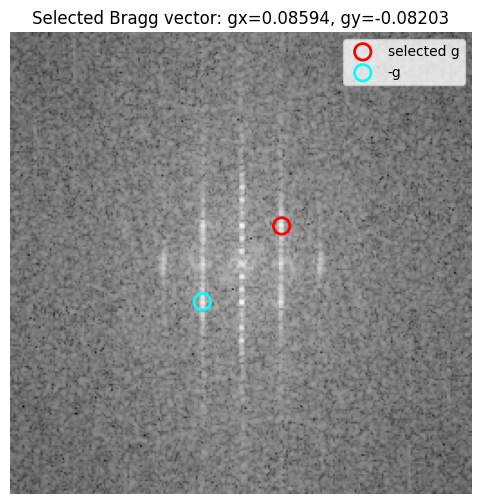

Selected g = (0.085938, -0.082031) cycles/pixel
x-period from gx = 11.636 pixels


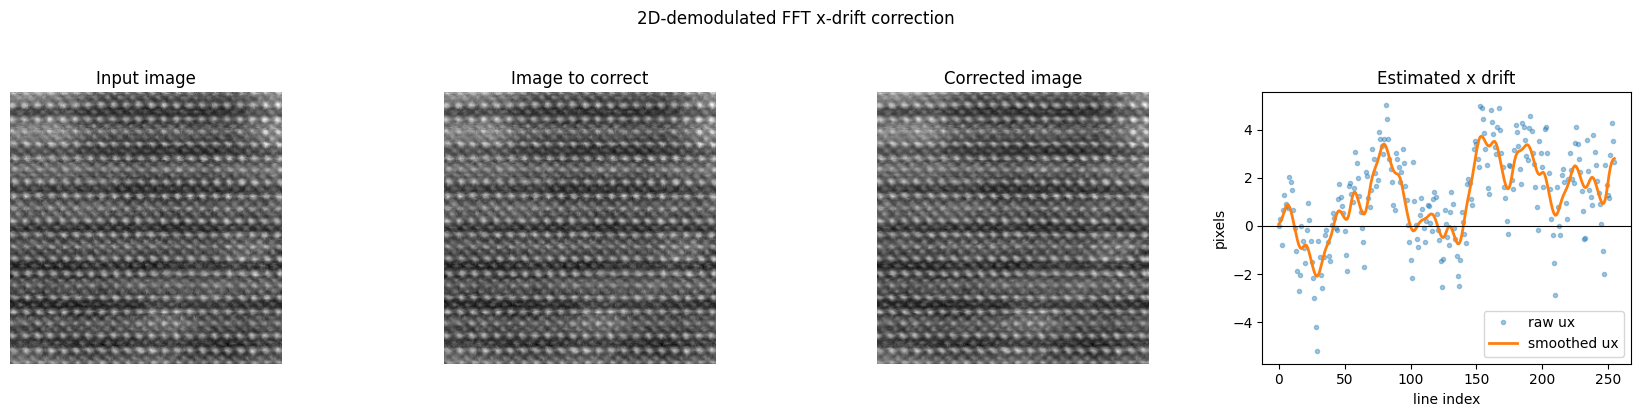

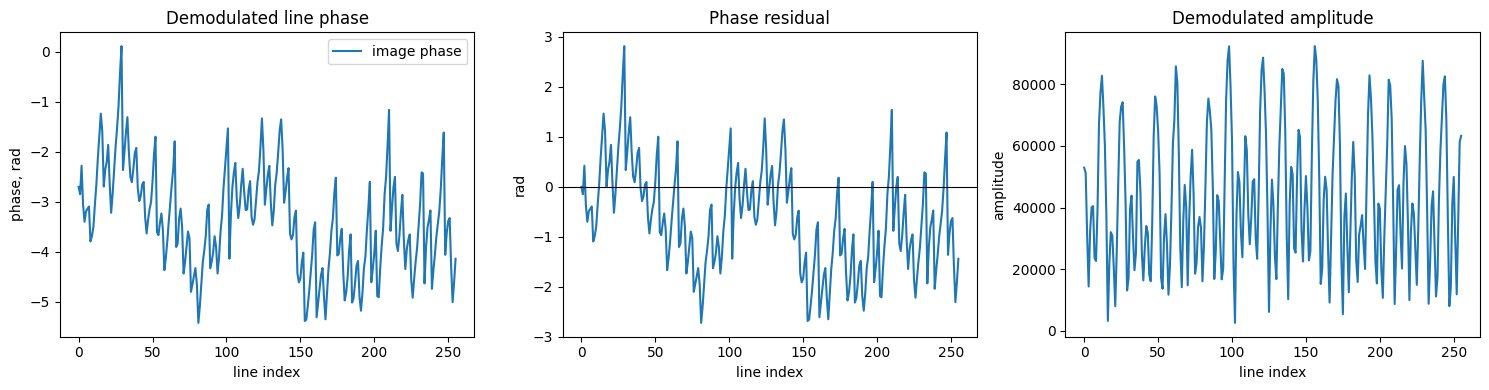

In [13]:
# ============================================================
# Corrected FFT x-drift compensation using full 2D demodulation
#
# Fixes the false linear drift artifact caused by treating an
# oblique 2D lattice as a 1D row signal.
#
# Required input:
#   img_cor : 2D numpy array
#
# Optional:
#   img_ref : undistorted/reference image, same shape as img_cor
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import (
    gaussian_filter,
    gaussian_filter1d,
    maximum_filter,
    map_coordinates,
)


# ============================================================
# 1. Utilities
# ============================================================

def _as_float_image(img):
    img = np.asarray(img, dtype=float)
    img = np.nan_to_num(img, nan=np.nanmedian(img))
    return img


def _hann2d(shape):
    H, W = shape
    return np.outer(np.hanning(H), np.hanning(W))


def _wrapped_phase_difference(phi_now, phi_ref):
    """
    Return wrapped phase difference in [-pi, pi].
    """
    dphi = phi_now - phi_ref
    dphi = (dphi + np.pi) % (2 * np.pi) - np.pi
    return dphi


def _weighted_gaussian_smooth_1d(values, weights=None, sigma=3):
    values = np.asarray(values, dtype=float)

    if weights is None:
        weights = np.ones_like(values, dtype=float)
    else:
        weights = np.asarray(weights, dtype=float)

    valid = np.isfinite(values) & np.isfinite(weights) & (weights > 0)

    numerator = gaussian_filter1d(
        np.where(valid, values * weights, 0.0),
        sigma=sigma,
        mode="nearest",
    )

    denominator = gaussian_filter1d(
        np.where(valid, weights, 0.0),
        sigma=sigma,
        mode="nearest",
    )

    return numerator / (denominator + 1e-12)


# ============================================================
# 2. Estimate one 2D Bragg vector g = (gx, gy)
# ============================================================

def estimate_2d_bragg_vector_for_x_drift(
    img,
    qmin=0.02,
    qmax=0.45,
    min_abs_gx=0.02,
    min_distance=6,
    smooth_sigma=1.0,
    prefer_positive_gx=True,
    plot=True,
):
    """
    Estimate a strong 2D reciprocal lattice vector g = (gx, gy).

    Important:
    For x-drift estimation, gx must not be too small because

        phase_residual = -2*pi*gx*ux

    so

        ux = -phase_residual / (2*pi*gx).

    Parameters
    ----------
    img : 2D ndarray
        Image.

    qmin, qmax : float
        Min/max radial spatial frequency in cycles/pixel.

    min_abs_gx : float
        Minimum |gx| allowed.

    Returns
    -------
    g : tuple
        (gx, gy) in cycles/pixel.
    """

    img = _as_float_image(img)
    H, W = img.shape

    data = img - np.mean(img)
    data = data * _hann2d(img.shape)

    F = np.fft.fftshift(np.fft.fft2(data))
    amp = np.log1p(np.abs(F))

    if smooth_sigma is not None and smooth_sigma > 0:
        amp_s = gaussian_filter(amp, sigma=smooth_sigma)
    else:
        amp_s = amp

    cy = H / 2
    cx = W / 2

    yy, xx = np.indices((H, W))

    gx_grid = (xx - cx) / W
    gy_grid = (yy - cy) / H
    q_grid = np.sqrt(gx_grid**2 + gy_grid**2)

    valid = (
        (q_grid >= qmin)
        & (q_grid <= qmax)
        & (np.abs(gx_grid) >= min_abs_gx)
    )

    local_max = amp_s == maximum_filter(
        amp_s,
        size=2 * min_distance + 1,
    )

    peak_mask = valid & local_max

    py_all, px_all = np.where(peak_mask)

    if len(px_all) == 0:
        raise RuntimeError(
            "No suitable Bragg peak found. Try lowering qmin or min_abs_gx."
        )

    scores = amp_s[py_all, px_all]
    order = np.argsort(scores)[::-1]

    px = px_all[order[0]]
    py = py_all[order[0]]

    gx = (px - cx) / W
    gy = (py - cy) / H

    # Set consistent sign convention.
    if prefer_positive_gx and gx < 0:
        gx = -gx
        gy = -gy

    g = (float(gx), float(gy))

    if plot:
        px_g = cx + gx * W
        py_g = cy + gy * H

        px_neg = cx - gx * W
        py_neg = cy - gy * H

        plt.figure(figsize=(6, 6))
        plt.imshow(amp, cmap="gray")
        plt.scatter(
            [px_g],
            [py_g],
            s=140,
            facecolors="none",
            edgecolors="red",
            linewidths=2,
            label="selected g",
        )
        plt.scatter(
            [px_neg],
            [py_neg],
            s=140,
            facecolors="none",
            edgecolors="cyan",
            linewidths=2,
            label="-g",
        )
        plt.title(f"Selected Bragg vector: gx={gx:.5f}, gy={gy:.5f}")
        plt.legend()
        plt.axis("off")
        plt.show()

    print(f"Selected g = ({gx:.6f}, {gy:.6f}) cycles/pixel")
    print(f"x-period from gx = {1 / abs(gx):.3f} pixels")

    return g


# ============================================================
# 3. Extract line phase using full 2D carrier
# ============================================================

def extract_line_phase_with_2d_demodulation(
    img,
    g,
    use_window=True,
    subtract_line_mean=True,
):
    """
    Extract line-by-line phase using the full 2D carrier:

        exp[-2*pi*i*(gx*x + gy*y)]

    This removes the natural row-to-row phase ramp of an oblique lattice.

    Parameters
    ----------
    img : 2D ndarray
        Image.

    g : tuple
        Reciprocal vector (gx, gy), cycles/pixel.

    Returns
    -------
    phase_unwrapped : 1D ndarray
        Unwrapped demodulated phase versus line index.

    amplitude : 1D ndarray
        Fourier amplitude per line.

    coeff : 1D complex ndarray
        Complex demodulated Fourier coefficient per line.
    """

    img = _as_float_image(img)
    H, W = img.shape

    gx, gy = g

    data = img.copy()

    if subtract_line_mean:
        data = data - np.mean(data, axis=1, keepdims=True)
    else:
        data = data - np.mean(data)

    x = np.arange(W, dtype=float)

    if use_window:
        wx = np.hanning(W)
    else:
        wx = np.ones(W)

    coeff = np.zeros(H, dtype=complex)

    for y in range(H):
        carrier = np.exp(
            -2j * np.pi * (gx * x + gy * y)
        )

        coeff[y] = np.sum(data[y, :] * wx * carrier)

    phase_wrapped = np.angle(coeff)
    phase_unwrapped = np.unwrap(phase_wrapped)
    amplitude = np.abs(coeff)

    return phase_unwrapped, amplitude, coeff


# ============================================================
# 4. Convert phase residual to x-drift
# ============================================================

def phase_to_x_drift(
    phase,
    g,
    amplitude=None,
    reference_phase=None,
    reference_mode="first",
    smooth_sigma=3,
    amplitude_percentile=10,
):
    """
    Convert demodulated phase into x drift.

    After full 2D demodulation,

        phase_residual(y) = -2*pi*gx*ux(y)

    so

        ux(y) = -phase_residual(y) / (2*pi*gx).

    reference_mode:
        "first"     : subtract the first phase value.
        "linear"    : remove residual linear trend.
                      Useful for diagnosing imperfect g, but it also removes
                      real constant-velocity drift.
        "reference" : subtract supplied reference_phase.
        "none"      : subtract nothing.
    """

    phase = np.asarray(phase, dtype=float)
    H = len(phase)
    y = np.arange(H)

    gx, gy = g

    if abs(gx) < 1e-12:
        raise ValueError("gx is too small for x-drift estimation.")

    if reference_mode == "first":
        phase_ref = np.full_like(phase, phase[0])

    elif reference_mode == "linear":
        if amplitude is None:
            weights = np.ones_like(phase)
        else:
            weights = np.asarray(amplitude, dtype=float)
            weights = weights / (np.nanmax(weights) + 1e-12)

        coeff = np.polyfit(y, phase, deg=1, w=weights)
        phase_ref = np.polyval(coeff, y)

    elif reference_mode == "reference":
        if reference_phase is None:
            raise ValueError(
                "reference_phase must be supplied when reference_mode='reference'."
            )

        reference_phase = np.asarray(reference_phase, dtype=float)

        if len(reference_phase) != H:
            raise ValueError("reference_phase must have the same length as phase.")

        # Use wrapped difference to avoid arbitrary 2*pi offsets.
        phase_residual = _wrapped_phase_difference(phase, reference_phase)

        ux_raw = -phase_residual / (2 * np.pi * gx)

        weights = _phase_weights(amplitude, amplitude_percentile)
        ux_smooth = _weighted_gaussian_smooth_1d(
            ux_raw,
            weights=weights,
            sigma=smooth_sigma,
        )

        return ux_raw, ux_smooth, reference_phase, phase_residual

    elif reference_mode == "none":
        phase_ref = np.zeros_like(phase)

    else:
        raise ValueError(
            "reference_mode must be 'first', 'linear', 'reference', or 'none'."
        )

    phase_residual = phase - phase_ref

    ux_raw = -phase_residual / (2 * np.pi * gx)

    weights = _phase_weights(amplitude, amplitude_percentile)

    ux_smooth = _weighted_gaussian_smooth_1d(
        ux_raw,
        weights=weights,
        sigma=smooth_sigma,
    )

    return ux_raw, ux_smooth, phase_ref, phase_residual


def _phase_weights(amplitude, amplitude_percentile=10):
    """
    Build confidence weights from Fourier amplitude.
    """
    if amplitude is None:
        return None

    amplitude = np.asarray(amplitude, dtype=float)

    threshold = np.nanpercentile(amplitude, amplitude_percentile)

    weights = (amplitude > threshold).astype(float)
    weights *= amplitude / (np.nanmax(amplitude) + 1e-12)

    return weights


# ============================================================
# 5. Apply x-drift correction
# ============================================================

def correct_x_drift_line_by_line(
    img,
    ux,
    order=1,
    mode="reflect",
):
    """
    Correct line-by-line x drift.

    If

        I_cor(x,y) = I_true(x - ux(y), y),

    then

        I_corr(x,y) = I_cor(x + ux(y), y).

    Parameters
    ----------
    img : 2D ndarray
        Corrupted image.

    ux : 1D ndarray
        Estimated apparent x drift per line.

    Returns
    -------
    corrected : 2D ndarray
    """

    img = _as_float_image(img)
    H, W = img.shape

    ux = np.asarray(ux, dtype=float)

    if len(ux) != H:
        raise ValueError("ux must have length equal to image height.")

    yy, xx = np.indices((H, W), dtype=float)

    source_y = yy
    source_x = xx + ux[:, None]

    corrected = map_coordinates(
        img,
        [source_y, source_x],
        order=order,
        mode=mode,
    )

    return corrected


# ============================================================
# 6. Full pipeline
# ============================================================

def run_fft_x_drift_correction_2d_demod(
    img_cor,
    img_ref=None,
    g=None,
    reference_mode=None,
    smooth_sigma=3,
    qmin=0.02,
    qmax=0.45,
    min_abs_gx=0.02,
    amplitude_percentile=10,
    plot_bragg=True,
):
    """
    Full corrected x-drift compensation pipeline.

    Parameters
    ----------
    img_cor : 2D ndarray
        Image to correct.

    img_ref : 2D ndarray or None
        Optional reference image. If supplied, the phase baseline is extracted
        from this image.

    g : tuple or None
        Optional known Bragg vector (gx, gy). If None, it is estimated.

    reference_mode : str or None
        If None:
            uses "reference" when img_ref is supplied,
            otherwise uses "first".

        Options:
            "first"     : subtract first phase value.
            "linear"    : subtract best-fit linear phase trend.
            "reference" : subtract phase from img_ref.
            "none"      : subtract nothing.

    Returns
    -------
    result : dict
    """

    img_cor = _as_float_image(img_cor)

    if img_ref is not None:
        img_ref = _as_float_image(img_ref)
        if img_ref.shape != img_cor.shape:
            raise ValueError("img_ref and img_cor must have the same shape.")

    if reference_mode is None:
        if img_ref is not None:
            reference_mode = "reference"
        else:
            reference_mode = "first"

    # Estimate g from reference if available, otherwise from corrupted image.
    if g is None:
        g_source = img_ref if img_ref is not None else img_cor

        g = estimate_2d_bragg_vector_for_x_drift(
            g_source,
            qmin=qmin,
            qmax=qmax,
            min_abs_gx=min_abs_gx,
            plot=plot_bragg,
        )
    else:
        print(f"Using supplied g = ({g[0]:.6f}, {g[1]:.6f}) cycles/pixel")

    # Phase from image to correct.
    phase_cor, amp_cor, coeff_cor = extract_line_phase_with_2d_demodulation(
        img_cor,
        g=g,
        use_window=True,
        subtract_line_mean=True,
    )

    # Optional reference phase.
    if img_ref is not None:
        phase_ref_img, amp_ref, coeff_ref = extract_line_phase_with_2d_demodulation(
            img_ref,
            g=g,
            use_window=True,
            subtract_line_mean=True,
        )
    else:
        phase_ref_img = None
        amp_ref = None
        coeff_ref = None

    ux_raw, ux_est, phase_ref_used, phase_residual = phase_to_x_drift(
        phase=phase_cor,
        g=g,
        amplitude=amp_cor,
        reference_phase=phase_ref_img,
        reference_mode=reference_mode,
        smooth_sigma=smooth_sigma,
        amplitude_percentile=amplitude_percentile,
    )

    img_corrected = correct_x_drift_line_by_line(
        img_cor,
        ux_est,
        order=1,
        mode="reflect",
    )

    result = {
        "g": g,
        "reference_mode": reference_mode,

        "phase_cor": phase_cor,
        "amp_cor": amp_cor,
        "coeff_cor": coeff_cor,

        "phase_ref_img": phase_ref_img,
        "amp_ref": amp_ref,
        "coeff_ref": coeff_ref,

        "phase_ref_used": phase_ref_used,
        "phase_residual": phase_residual,

        "ux_raw": ux_raw,
        "ux_est": ux_est,

        "img_corrected": img_corrected,
    }

    return result


# ============================================================
# 7. Diagnostic visualization
# ============================================================

def plot_fft_x_drift_result(
    img_cor,
    result,
    img_ref=None,
    true_ux=None,
    title_prefix="",
):
    """
    Plot input, corrected image, phase, and estimated drift.
    """

    img_cor = _as_float_image(img_cor)
    img_corrected = result["img_corrected"]

    fig, axes = plt.subplots(1, 4, figsize=(17, 4))

    if img_ref is not None:
        axes[0].imshow(img_ref, cmap="gray")
        axes[0].set_title("Reference")
    else:
        axes[0].imshow(img_cor, cmap="gray")
        axes[0].set_title("Input image")

    axes[0].axis("off")

    axes[1].imshow(img_cor, cmap="gray")
    axes[1].set_title("Image to correct")
    axes[1].axis("off")

    axes[2].imshow(img_corrected, cmap="gray")
    axes[2].set_title("Corrected image")
    axes[2].axis("off")

    axes[3].plot(result["ux_raw"], ".", alpha=0.4, label="raw ux")
    axes[3].plot(result["ux_est"], "-", linewidth=2, label="smoothed ux")

    if true_ux is not None:
        true_ux = np.asarray(true_ux, dtype=float)
        true_rel = true_ux - true_ux[0]
        axes[3].plot(true_rel, "--", label="true ux relative")

    axes[3].axhline(0, color="k", linewidth=0.8)
    axes[3].set_title("Estimated x drift")
    axes[3].set_xlabel("line index")
    axes[3].set_ylabel("pixels")
    axes[3].legend()

    if title_prefix:
        fig.suptitle(title_prefix, y=1.03)

    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(result["phase_cor"], label="image phase")
    if result["phase_ref_img"] is not None:
        axes[0].plot(result["phase_ref_img"], "--", label="reference phase")
    axes[0].set_title("Demodulated line phase")
    axes[0].set_xlabel("line index")
    axes[0].set_ylabel("phase, rad")
    axes[0].legend()

    axes[1].plot(result["phase_residual"])
    axes[1].axhline(0, color="k", linewidth=0.8)
    axes[1].set_title("Phase residual")
    axes[1].set_xlabel("line index")
    axes[1].set_ylabel("rad")

    axes[2].plot(result["amp_cor"])
    axes[2].set_title("Demodulated amplitude")
    axes[2].set_xlabel("line index")
    axes[2].set_ylabel("amplitude")

    plt.tight_layout()
    plt.show()


# ============================================================
# 8. Example usage
# ============================================================

# ------------------------------------------------------------
# Case A: No reference image available
# ------------------------------------------------------------
# This uses full 2D demodulation and subtracts the first phase value.
# It should remove the false linear drift caused by ignoring gy,
# assuming the selected g is accurate.

result_xcorr = run_fft_x_drift_correction_2d_demod(
    img_cor=img_cor,
    img_ref=None,
    g=None,
    reference_mode="first",
    smooth_sigma=3,
    qmin=0.02,
    qmax=0.45,
    min_abs_gx=0.02,
    amplitude_percentile=10,
    plot_bragg=True,
)

plot_fft_x_drift_result(
    img_cor=img_cor,
    result=result_xcorr,
    img_ref=None,
    true_ux=globals().get("ux_true", None),
    title_prefix="2D-demodulated FFT x-drift correction",
)

img_corrected_x = result_xcorr["img_corrected"]
ux_est_x = result_xcorr["ux_est"]


# ------------------------------------------------------------
# Case B: Reference image available
# ------------------------------------------------------------
# Uncomment if you have an undistorted or previous reference image:
#
# result_xcorr_ref = run_fft_x_drift_correction_2d_demod(
#     img_cor=img_cor,
#     img_ref=img,              # or img_ref
#     g=None,
#     reference_mode="reference",
#     smooth_sigma=3,
#     qmin=0.02,
#     qmax=0.45,
#     min_abs_gx=0.02,
#     amplitude_percentile=10,
#     plot_bragg=True,
# )
#
# plot_fft_x_drift_result(
#     img_cor=img_cor,
#     result=result_xcorr_ref,
#     img_ref=img,
#     true_ux=globals().get("ux_true", None),
#     title_prefix="Reference-based FFT x-drift correction",
# )
#
# img_corrected_x_ref = result_xcorr_ref["img_corrected"]
# ux_est_x_ref = result_xcorr_ref["ux_est"]


# ------------------------------------------------------------
# Case C: Diagnostic only for undistorted image
# ------------------------------------------------------------
# If you test on an undistorted image and still see a residual
# linear trend, the Bragg vector g is slightly misestimated.
# You can use reference_mode="linear" as a diagnostic.
#
# WARNING:
# reference_mode="linear" also removes real constant-velocity drift.
#
# result_undistorted_test = run_fft_x_drift_correction_2d_demod(
#     img_cor=img,
#     img_ref=None,
#     g=None,
#     reference_mode="linear",
#     smooth_sigma=3,
#     plot_bragg=True,
# )
#
# plot_fft_x_drift_result(
#     img_cor=img,
#     result=result_undistorted_test,
#     title_prefix="Undistorted image diagnostic",
# )

### Correction in XY sliding FFT

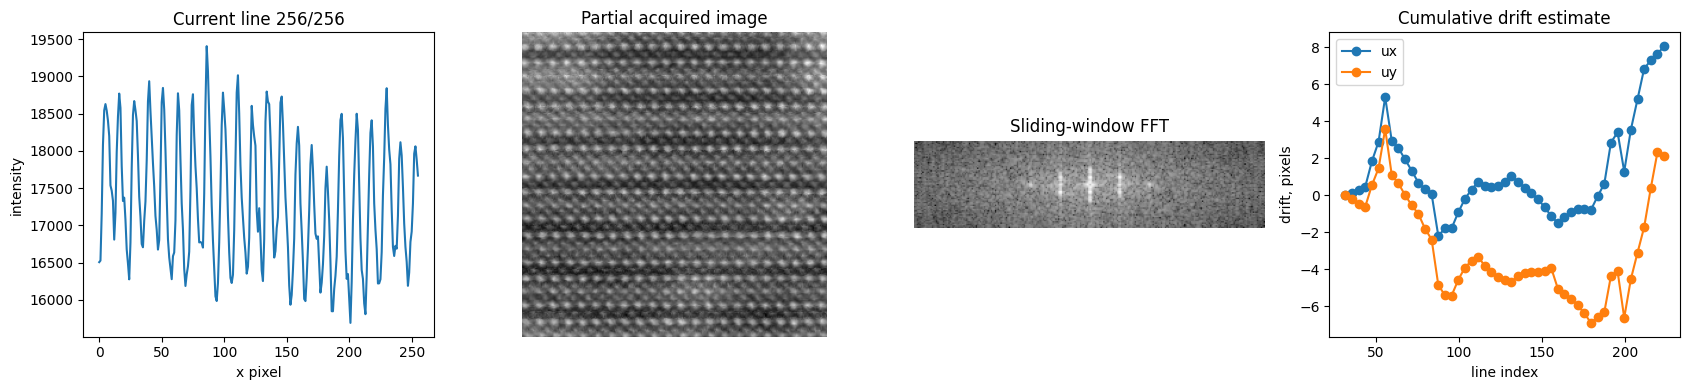

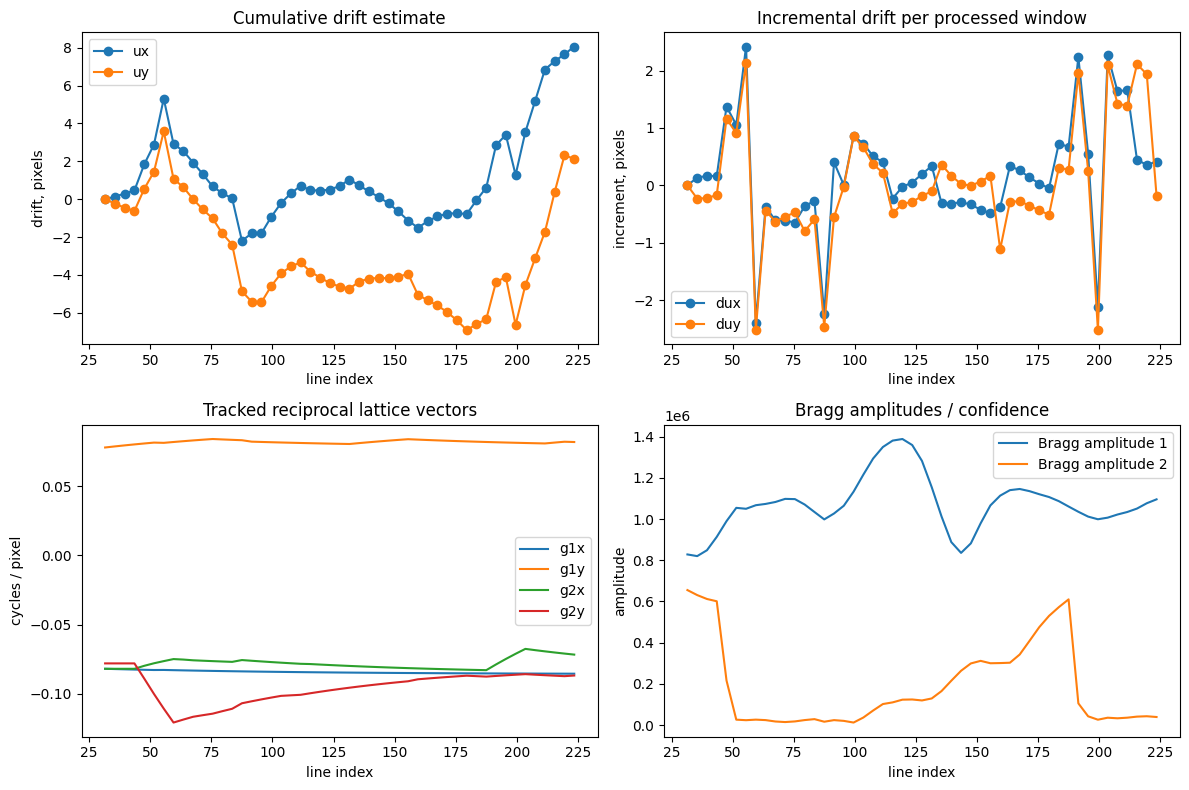

In [14]:
# ============================================================
# Online sliding-window 2D FFT lattice learning and drift tracking
#
# Assumes:
#   - img_cor exists
#   - corrupted_image_scan_stream(img_cor) is already defined
#
# Goal:
#   1. Accumulate lines
#   2. Estimate lattice vectors from local 2D FFT
#   3. Track phase changes in sliding windows
#   4. Convert phase changes to incremental x/y drift
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter, maximum_filter
from IPython.display import clear_output


# ------------------------------------------------------------
# Utility: preprocess sliding window
# ------------------------------------------------------------

def preprocess_window_for_fft(window):
    """
    Basic preprocessing before FFT:
    - replace NaNs
    - subtract mean
    - apply 2D Hann window
    """
    window = np.asarray(window, dtype=float)

    data = np.nan_to_num(window, nan=np.nanmedian(window))
    data = data - np.mean(data)

    H, W = data.shape
    wy = np.hanning(H)
    wx = np.hanning(W)
    win = np.outer(wy, wx)

    return data * win


# ------------------------------------------------------------
# Estimate Bragg peak candidates from a 2D window
# ------------------------------------------------------------

def estimate_bragg_candidates_from_window(
    window,
    num_peaks=12,
    min_radius_fraction=0.05,
    max_radius_fraction=0.45,
    min_distance=5,
    smooth_sigma=1.0,
):
    """
    Estimate candidate Bragg peaks from the 2D FFT of a window.

    Returns candidates with:
        gx, gy in cycles/pixel
        px, py in FFT pixel coordinates
        amplitude score
    """

    data = preprocess_window_for_fft(window)

    H, W = data.shape

    F = np.fft.fftshift(np.fft.fft2(data))
    amp = np.log1p(np.abs(F))

    if smooth_sigma is not None and smooth_sigma > 0:
        amp_s = gaussian_filter(amp, smooth_sigma)
    else:
        amp_s = amp

    cy = H / 2
    cx = W / 2

    yy, xx = np.indices((H, W))
    rr = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)

    min_radius = min_radius_fraction * min(H, W)
    max_radius = max_radius_fraction * min(H, W)

    valid = (rr >= min_radius) & (rr <= max_radius)

    local_max = amp_s == maximum_filter(
        amp_s,
        size=2 * min_distance + 1,
    )

    peak_mask = local_max & valid

    py_all, px_all = np.where(peak_mask)
    scores = amp_s[py_all, px_all]

    order = np.argsort(scores)[::-1]

    candidates = []

    for idx in order:
        px = float(px_all[idx])
        py = float(py_all[idx])

        gx = (px - cx) / W
        gy = (py - cy) / H

        candidates.append(
            {
                "px": px,
                "py": py,
                "gx": gx,
                "gy": gy,
                "amplitude": float(scores[idx]),
            }
        )

        if len(candidates) >= num_peaks:
            break

    return candidates, F, amp


# ------------------------------------------------------------
# Choose two non-collinear Bragg vectors
# ------------------------------------------------------------

def choose_two_noncollinear_vectors(
    candidates,
    min_angle_degrees=20,
):
    """
    Pick two strong non-collinear reciprocal lattice vectors.
    Avoid choosing g and -g as the basis pair.
    """

    if len(candidates) < 2:
        raise RuntimeError("Not enough Bragg candidates found.")

    min_sin = np.sin(np.deg2rad(min_angle_degrees))

    best_score = -np.inf
    best_pair = None

    for i in range(len(candidates)):
        g1 = np.array([candidates[i]["gx"], candidates[i]["gy"]], dtype=float)
        a1 = candidates[i]["amplitude"]
        n1 = np.linalg.norm(g1)

        if n1 == 0:
            continue

        for j in range(i + 1, len(candidates)):
            g2 = np.array([candidates[j]["gx"], candidates[j]["gy"]], dtype=float)
            a2 = candidates[j]["amplitude"]
            n2 = np.linalg.norm(g2)

            if n2 == 0:
                continue

            cross = abs(g1[0] * g2[1] - g1[1] * g2[0])
            sin_angle = cross / (n1 * n2 + 1e-12)

            if sin_angle < min_sin:
                continue

            score = a1 + a2 + 5.0 * sin_angle

            if score > best_score:
                best_score = score
                best_pair = (g1, g2, i, j, sin_angle)

    if best_pair is None:
        raise RuntimeError("Could not find two non-collinear Bragg vectors.")

    g1, g2, i, j, sin_angle = best_pair

    return tuple(g1), tuple(g2), (i, j)


# ------------------------------------------------------------
# Align current lattice-vector estimate to previous estimate
# Handles sign flips and vector swaps
# ------------------------------------------------------------

def align_g_pair_to_previous(g1_new, g2_new, g1_prev, g2_prev):
    """
    FFT peak finding may return:
    - g instead of -g
    - g1/g2 swapped

    This function chooses the equivalent representation closest to previous.
    """

    g_new = [
        np.array(g1_new, dtype=float),
        np.array(g2_new, dtype=float),
    ]

    g_prev = [
        np.array(g1_prev, dtype=float),
        np.array(g2_prev, dtype=float),
    ]

    possibilities = []

    for swap in [False, True]:
        if swap:
            trial = [g_new[1], g_new[0]]
        else:
            trial = [g_new[0], g_new[1]]

        for s1 in [-1, 1]:
            for s2 in [-1, 1]:
                t1 = s1 * trial[0]
                t2 = s2 * trial[1]

                score = np.linalg.norm(t1 - g_prev[0]) + np.linalg.norm(t2 - g_prev[1])
                possibilities.append((score, t1, t2))

    possibilities.sort(key=lambda x: x[0])

    _, g1_aligned, g2_aligned = possibilities[0]

    return tuple(g1_aligned), tuple(g2_aligned)


# ------------------------------------------------------------
# Extract global demodulated phase from a sliding window
# ------------------------------------------------------------

def bragg_phase_from_window(window, y_start_global, g):
    """
    Extract one average demodulated phase from a window at reciprocal vector g.

    Important:
    The carrier uses GLOBAL y coordinates:
        phase carrier = exp[-2*pi*i*(gx*x + gy*y_global)]

    This avoids confusing the phase change from moving down the image
    with actual drift.
    """

    window = np.asarray(window, dtype=float)

    H, W = window.shape

    data = np.nan_to_num(window, nan=np.nanmedian(window))

    # Remove local DC
    data = data - np.mean(data)

    wy = np.hanning(H)
    wx = np.hanning(W)
    win = np.outer(wy, wx)

    y_local, x = np.indices((H, W))
    y_global = y_start_global + y_local

    gx, gy = g

    carrier = np.exp(
        -2j * np.pi * (gx * x + gy * y_global)
    )

    coeff = np.sum(data * win * carrier)

    phase = np.angle(coeff)
    amplitude = np.abs(coeff)

    return phase, amplitude, coeff


# ------------------------------------------------------------
# Robust phase difference between two wrapped phases
# ------------------------------------------------------------

def wrapped_phase_difference(phi_now, phi_prev):
    """
    Return phi_now - phi_prev wrapped to [-pi, pi].
    """
    dphi = phi_now - phi_prev
    dphi = (dphi + np.pi) % (2 * np.pi) - np.pi
    return dphi


# ------------------------------------------------------------
# Convert phase differences to displacement increment
# ------------------------------------------------------------

def displacement_increment_from_phase_differences(dphi1, dphi2, g1, g2):
    """
    Solve:
        dphi_i = -2*pi * g_i dot du

    Returns:
        dux, duy
    """

    G = np.array(
        [
            [g1[0], g1[1]],
            [g2[0], g2[1]],
        ],
        dtype=float,
    )

    det = np.linalg.det(G)

    if abs(det) < 1e-12:
        raise RuntimeError("g1 and g2 are nearly collinear.")

    dphi = np.array([dphi1, dphi2], dtype=float)

    du = -(1.0 / (2 * np.pi)) * np.linalg.solve(G, dphi)

    dux, duy = du

    return float(dux), float(duy)


# ------------------------------------------------------------
# Main online sliding estimator
# ------------------------------------------------------------

class SlidingFFT2DDriftEstimator:
    """
    Online drift estimator:
    - buffers incoming scan lines
    - estimates lattice vectors using sliding 2D FFT
    - extracts two Bragg phases per window
    - compares current phases to previous phases
    - accumulates x/y drift
    """

    def __init__(
        self,
        image_width,
        window_height=64,
        step=4,
        num_peaks=12,
        min_angle_degrees=20,
        g_update_alpha=0.05,
        min_radius_fraction=0.05,
        max_radius_fraction=0.45,
        min_distance=5,
    ):
        self.image_width = image_width
        self.window_height = window_height
        self.step = step

        self.num_peaks = num_peaks
        self.min_angle_degrees = min_angle_degrees
        self.g_update_alpha = g_update_alpha

        self.min_radius_fraction = min_radius_fraction
        self.max_radius_fraction = max_radius_fraction
        self.min_distance = min_distance

        self.lines = []
        self.line_indices = []

        self.g1 = None
        self.g2 = None

        self.prev_phase1 = None
        self.prev_phase2 = None

        self.ux_cumulative = 0.0
        self.uy_cumulative = 0.0

        self.last_processed_line = None

        self.history = {
            "line_index": [],
            "window_start": [],
            "window_center": [],

            "g1x": [],
            "g1y": [],
            "g2x": [],
            "g2y": [],

            "phase1": [],
            "phase2": [],
            "amp1": [],
            "amp2": [],

            "dux": [],
            "duy": [],
            "ux": [],
            "uy": [],

            "initialized": [],
        }

    def update(self, line, line_index):
        """
        Add one new line. If enough new lines have arrived,
        process the current sliding window.

        Returns None if no window is processed at this line.
        Otherwise returns a dict with the current drift estimate.
        """

        line = np.asarray(line, dtype=float)

        self.lines.append(line.copy())
        self.line_indices.append(line_index)

        # Need enough lines for first FFT
        if len(self.lines) < self.window_height:
            return None

        # Only process every self.step lines
        if self.last_processed_line is not None:
            if (line_index - self.last_processed_line) < self.step:
                return None

        self.last_processed_line = line_index

        # Current sliding window
        window_lines = self.lines[-self.window_height:]
        window_indices = self.line_indices[-self.window_height:]

        window = np.vstack(window_lines)

        y_start = window_indices[0]
        y_center = 0.5 * (window_indices[0] + window_indices[-1])

        # Estimate lattice vectors from current window
        candidates, F, amp = estimate_bragg_candidates_from_window(
            window,
            num_peaks=self.num_peaks,
            min_radius_fraction=self.min_radius_fraction,
            max_radius_fraction=self.max_radius_fraction,
            min_distance=self.min_distance,
            smooth_sigma=1.0,
        )

        g1_new, g2_new, selected = choose_two_noncollinear_vectors(
            candidates,
            min_angle_degrees=self.min_angle_degrees,
        )

        initialized_now = False

        if self.g1 is None:
            # First valid lattice estimate
            self.g1 = np.array(g1_new, dtype=float)
            self.g2 = np.array(g2_new, dtype=float)
            initialized_now = True

        else:
            # Align signs/swap to previous g basis
            g1_aligned, g2_aligned = align_g_pair_to_previous(
                g1_new,
                g2_new,
                self.g1,
                self.g2,
            )

            g1_aligned = np.array(g1_aligned, dtype=float)
            g2_aligned = np.array(g2_aligned, dtype=float)

            # Slowly update reciprocal lattice estimate
            self.g1 = (
                (1 - self.g_update_alpha) * self.g1
                + self.g_update_alpha * g1_aligned
            )

            self.g2 = (
                (1 - self.g_update_alpha) * self.g2
                + self.g_update_alpha * g2_aligned
            )

        g1 = tuple(self.g1)
        g2 = tuple(self.g2)

        # Extract phases from this window using global row coordinates
        phase1, amp1, coeff1 = bragg_phase_from_window(
            window,
            y_start_global=y_start,
            g=g1,
        )

        phase2, amp2, coeff2 = bragg_phase_from_window(
            window,
            y_start_global=y_start,
            g=g2,
        )

        # First phase observation initializes reference
        if self.prev_phase1 is None:
            dux = 0.0
            duy = 0.0

            self.prev_phase1 = phase1
            self.prev_phase2 = phase2

        else:
            dphi1 = wrapped_phase_difference(phase1, self.prev_phase1)
            dphi2 = wrapped_phase_difference(phase2, self.prev_phase2)

            dux, duy = displacement_increment_from_phase_differences(
                dphi1,
                dphi2,
                g1,
                g2,
            )

            self.ux_cumulative += dux
            self.uy_cumulative += duy

            self.prev_phase1 = phase1
            self.prev_phase2 = phase2

        out = {
            "line_index": line_index,
            "window_start": y_start,
            "window_center": y_center,
            "g1": g1,
            "g2": g2,
            "phase1": phase1,
            "phase2": phase2,
            "amp1": amp1,
            "amp2": amp2,
            "dux": dux,
            "duy": duy,
            "ux": self.ux_cumulative,
            "uy": self.uy_cumulative,
            "initialized": initialized_now,
            "window": window,
            "fft_amp": amp,
        }

        self._store(out)

        return out

    def _store(self, out):
        self.history["line_index"].append(out["line_index"])
        self.history["window_start"].append(out["window_start"])
        self.history["window_center"].append(out["window_center"])

        self.history["g1x"].append(out["g1"][0])
        self.history["g1y"].append(out["g1"][1])
        self.history["g2x"].append(out["g2"][0])
        self.history["g2y"].append(out["g2"][1])

        self.history["phase1"].append(out["phase1"])
        self.history["phase2"].append(out["phase2"])
        self.history["amp1"].append(out["amp1"])
        self.history["amp2"].append(out["amp2"])

        self.history["dux"].append(out["dux"])
        self.history["duy"].append(out["duy"])
        self.history["ux"].append(out["ux"])
        self.history["uy"].append(out["uy"])

        self.history["initialized"].append(out["initialized"])


# ------------------------------------------------------------
# Run on existing stream
# ------------------------------------------------------------

def run_sliding_fft_2d_drift_tracking(
    img_cor,
    window_height=64,
    step=4,
    animate=True,
    animation_delay=0.03,
):
    """
    Run the sliding-window FFT lattice/drift tracker on img_cor.

    Uses:
        stream = corrupted_image_scan_stream(img_cor)
    """

    img_cor = np.asarray(img_cor, dtype=float)
    H, W = img_cor.shape

    estimator = SlidingFFT2DDriftEstimator(
        image_width=W,
        window_height=window_height,
        step=step,
        num_peaks=12,
        min_angle_degrees=20,
        g_update_alpha=0.05,
        min_radius_fraction=0.05,
        max_radius_fraction=0.45,
        min_distance=5,
    )

    stream = corrupted_image_scan_stream(img_cor)

    last_out = None

    for _ in range(H):
        frame = next(stream)

        line_index = frame["line_index"]
        line = frame["line"]

        out = estimator.update(line, line_index)

        if out is not None:
            last_out = out

        if animate:
            clear_output(wait=True)

            fig, axes = plt.subplots(1, 4, figsize=(17, 4))

            # Current line
            axes[0].plot(line)
            axes[0].set_title(f"Current line {line_index + 1}/{H}")
            axes[0].set_xlabel("x pixel")
            axes[0].set_ylabel("intensity")

            # Partial image
            axes[1].imshow(frame["partial_image"], cmap="gray")
            axes[1].set_title("Partial acquired image")
            axes[1].axis("off")

            # FFT of last processed window
            if last_out is not None:
                axes[2].imshow(last_out["fft_amp"], cmap="gray")
                axes[2].set_title("Sliding-window FFT")
                axes[2].axis("off")
            else:
                axes[2].text(
                    0.5,
                    0.5,
                    "Waiting for\ninitial window",
                    ha="center",
                    va="center",
                    transform=axes[2].transAxes,
                )
                axes[2].axis("off")

            # Drift trajectory
            hist = estimator.history

            if len(hist["ux"]) > 0:
                axes[3].plot(hist["window_center"], hist["ux"], "-o", label="ux")
                axes[3].plot(hist["window_center"], hist["uy"], "-o", label="uy")

            axes[3].set_title("Cumulative drift estimate")
            axes[3].set_xlabel("line index")
            axes[3].set_ylabel("drift, pixels")
            axes[3].legend()

            plt.tight_layout()
            plt.show()

            time.sleep(animation_delay)

    return estimator


# ------------------------------------------------------------
# Execute
# ------------------------------------------------------------

estimator = run_sliding_fft_2d_drift_tracking(
    img_cor,
    window_height=64,
    step=4,
    animate=True,
    animation_delay=0.03,
)


# ------------------------------------------------------------
# Final diagnostic plots
# ------------------------------------------------------------

hist = estimator.history

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(hist["window_center"], hist["ux"], "-o", label="ux")
axes[0, 0].plot(hist["window_center"], hist["uy"], "-o", label="uy")
axes[0, 0].set_title("Cumulative drift estimate")
axes[0, 0].set_xlabel("line index")
axes[0, 0].set_ylabel("drift, pixels")
axes[0, 0].legend()

axes[0, 1].plot(hist["window_center"], hist["dux"], "-o", label="dux")
axes[0, 1].plot(hist["window_center"], hist["duy"], "-o", label="duy")
axes[0, 1].set_title("Incremental drift per processed window")
axes[0, 1].set_xlabel("line index")
axes[0, 1].set_ylabel("increment, pixels")
axes[0, 1].legend()

axes[1, 0].plot(hist["window_center"], hist["g1x"], label="g1x")
axes[1, 0].plot(hist["window_center"], hist["g1y"], label="g1y")
axes[1, 0].plot(hist["window_center"], hist["g2x"], label="g2x")
axes[1, 0].plot(hist["window_center"], hist["g2y"], label="g2y")
axes[1, 0].set_title("Tracked reciprocal lattice vectors")
axes[1, 0].set_xlabel("line index")
axes[1, 0].set_ylabel("cycles / pixel")
axes[1, 0].legend()

axes[1, 1].plot(hist["window_center"], hist["amp1"], label="Bragg amplitude 1")
axes[1, 1].plot(hist["window_center"], hist["amp2"], label="Bragg amplitude 2")
axes[1, 1].set_title("Bragg amplitudes / confidence")
axes[1, 1].set_xlabel("line index")
axes[1, 1].set_ylabel("amplitude")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

Need to figure out how to plot the corrected images.

## Probabilistic Reconstruction for Line-by-Line Drift Compensation

The goal is to treat the partially acquired image not simply as a set of measured pixels, but as evidence for an underlying latent image. After several scan lines have been measured, we build a probabilistic model of the image and use it to predict the next line before it is acquired.

Let the measured image intensity be

$$
I(x,y) = f(x,y) + \epsilon,
$$

where \(f(x,y)\) is the latent, noise-free image and \(\epsilon\) is measurement noise. After measuring lines \(0,1,\ldots,y\), we want to predict the next line:

$$
p\left(I(x,y+1) \mid I(x,0), I(x,1), \ldots, I(x,y)\right).
$$

This prediction is not a single deterministic line. It is a probability distribution. In practice, we represent it by a predictive mean and uncertainty:

$$
I(x,y+1) \sim \mathcal{N}\left(\mu(x,y+1), \sigma^2(x,y+1)\right).
$$

Here, \(\mu(x,y+1)\) is the expected next line, and \(\sigma(x,y+1)\) tells us how uncertain the model is at each pixel.

---

## Fourier-Feature Model of the Local Lattice

For an atomically resolved image, the intensity is often approximately periodic. Therefore, a useful local model is a Fourier expansion:

$$
f(x,y) =
\theta_0
+
\sum_{k=1}^{K}
\left[
a_k \cos\left(2\pi(g_{kx}x + g_{ky}y)\right)
+
b_k \sin\left(2\pi(g_{kx}x + g_{ky}y)\right)
\right].
$$

The vectors

$$
\mathbf{g}_k = (g_{kx}, g_{ky})
$$

represent spatial frequencies extracted from the Fourier transform of the already measured lines. These frequencies do not need to describe the entire perfect lattice. They only need to capture enough periodic structure to predict nearby scan lines.

The model can be written compactly as

$$
f(x,y) = \boldsymbol{\phi}(x,y)^T \boldsymbol{\theta},
$$

where \(\boldsymbol{\phi}(x,y)\) is the vector of Fourier features and \(\boldsymbol{\theta}\) contains the unknown coefficients.

---

## Bayesian Regression Formulation

Instead of fitting a single best set of Fourier coefficients, we place a prior distribution on them:

$$
\boldsymbol{\theta} \sim \mathcal{N}(0, \alpha^2 I).
$$

The measured intensities are modeled as

$$
\mathbf{I}_{\mathrm{meas}} = \Phi \boldsymbol{\theta} + \boldsymbol{\epsilon},
$$

with

$$
\boldsymbol{\epsilon} \sim \mathcal{N}(0, \sigma_n^2 I).
$$

Here, \(\Phi\) is the design matrix built from the Fourier features evaluated at the measured pixel coordinates.

After observing several lines, Bayes' rule gives a posterior distribution over the coefficients:

$$
p(\boldsymbol{\theta} \mid \mathbf{I}_{\mathrm{meas}})
=
\mathcal{N}
\left(
\boldsymbol{\mu}_{\theta},
\Sigma_{\theta}
\right).
$$

The posterior covariance \(\Sigma_{\theta}\) is important because it tells us how much uncertainty remains in the reconstructed image model.

---

## Predicting the Next Line

For the next line \(y+1\), we evaluate the Fourier features at all pixel positions \(x\). This gives a new design matrix \(\Phi_\ast\). The predictive distribution is

$$
p(\mathbf{I}_\ast \mid \mathbf{I}_{\mathrm{meas}})
=
\mathcal{N}
\left(
\Phi_\ast \boldsymbol{\mu}_{\theta},
\Phi_\ast \Sigma_{\theta} \Phi_\ast^T + \sigma_n^2 I
\right).
$$

Therefore, the predicted mean line is

$$
\boldsymbol{\mu}_\ast =
\Phi_\ast \boldsymbol{\mu}_{\theta},
$$

and the predictive variance is

$$
\boldsymbol{\sigma}_\ast^2 =
\mathrm{diag}
\left(
\Phi_\ast \Sigma_{\theta} \Phi_\ast^T
\right)
+
\sigma_n^2.
$$

This gives a full probabilistic prediction of the next line:

$$
I_\ast(x) =
\mu_\ast(x) \pm \sigma_\ast(x).
$$

---

## Comparing Prediction and Measurement

Once the next line is actually measured, we compare it with the predicted line. The residual is

$$
r(x) =
I_{\mathrm{measured}}(x,y+1)
-
\mu_\ast(x).
$$

The normalized residual, or z-score, is

$$
z(x) =
\frac{
I_{\mathrm{measured}}(x,y+1) - \mu_\ast(x)
}{
\sigma_\ast(x)
}.
$$

Large values of \(|z(x)|\) indicate that the measured line is surprising relative to the model. This can happen because of noise, defects, a new structural feature, or drift.

---

## Using the Prediction to Infer Drift

If the measured line differs from the predicted line by a spatial shift, we can treat the drift as a latent variable. For example, for horizontal drift only, we assume that the measured line is a shifted version of the predicted line:

$$
I_{\mathrm{measured}}(x,y+1)
\approx
\mu_\ast(x+\delta_x).
$$

The most likely drift is obtained by minimizing the uncertainty-weighted mismatch:

$$
\delta_x^\ast
=
\arg\min_{\delta_x}
\sum_x
\frac{
\left[
I_{\mathrm{measured}}(x,y+1)
-
\mu_\ast(x+\delta_x)
\right]^2
}{
\sigma_\ast^2(x+\delta_x)
}.
$$

For two-dimensional drift, the same idea can be extended to

$$
\boldsymbol{\delta}^\ast =
(\delta_x^\ast, \delta_y^\ast),
$$

where the measured data are compared to a shifted or warped prediction.

---

## Conceptual Summary

The probabilistic reconstruction approach changes the problem from direct image registration to predictive modeling.

Instead of asking:

$$
\text{How do I register this line to the previous line?}
$$

we ask:

$$
\text{Given all lines measured so far, what should the next line look like?}
$$

Then, when the next line is acquired, the difference between prediction and measurement provides evidence for drift, defects, or model mismatch.

The workflow is:

1. Measure several scan lines.
2. Fit a probabilistic reconstruction model.
3. Predict the next line as mean plus uncertainty.
4. Acquire the next line.
5. Compare measured and predicted line.
6. Use the residual to infer drift or detect unexpected structure.
7. Update the model and repeat.

This is a natural framework for dynamic drift compensation because it combines image reconstruction, uncertainty quantification, and microscope-state estimation in a single loop.

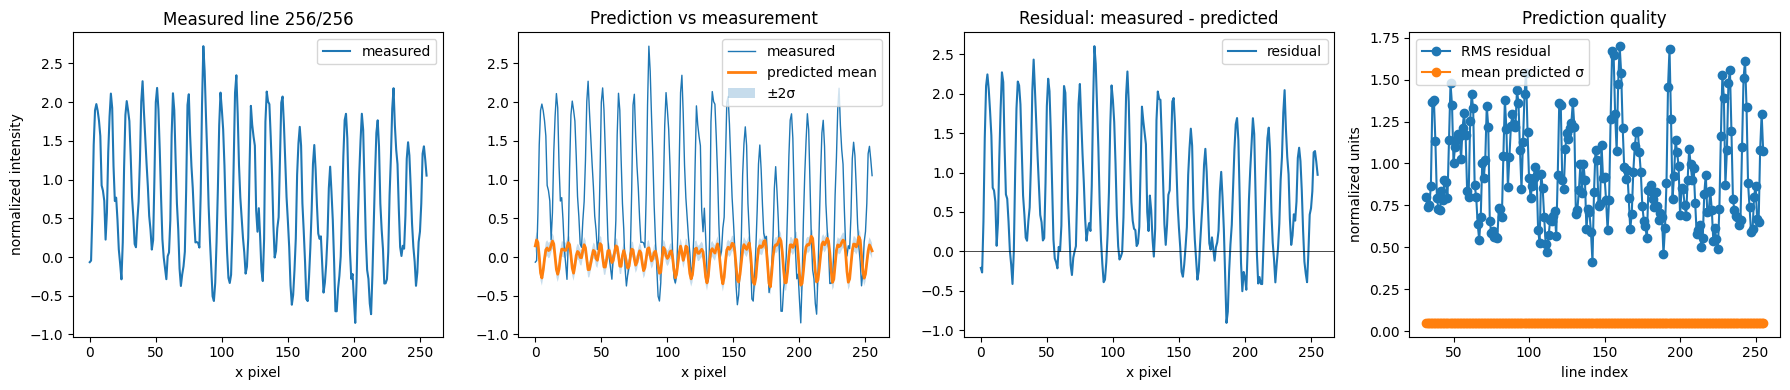

In [15]:
# ============================================================
# Probabilistic next-line prediction from previously measured lines
#
# Assumes:
#   - img_cor exists
#   - corrupted_image_scan_stream(img_cor) already exists
#
# Idea:
#   Use a Bayesian Fourier-feature model on a sliding block of measured lines.
#   Predict the next line as mean ± uncertainty.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter, maximum_filter
from IPython.display import clear_output


# ------------------------------------------------------------
# Normalize image for stable probabilistic modeling
# ------------------------------------------------------------

def normalize_for_model(img):
    img = np.asarray(img, dtype=float)
    med = np.nanmedian(img)
    std = np.nanstd(img)

    if std <= 0:
        std = 1.0

    img_n = (img - med) / std

    return img_n, med, std


# ------------------------------------------------------------
# Select 2D Fourier features from a block of measured lines
# ------------------------------------------------------------

def select_fourier_features_from_block(
    block,
    n_features=24,
    qmin=0.02,
    qmax=0.48,
    min_distance=4,
    smooth_sigma=1.0,
    duplicate_tol=0.01,
):
    """
    Select dominant 2D Fourier components from a block.

    Parameters
    ----------
    block : 2D array
        Recently measured image block, shape (n_lines, width).

    n_features : int
        Number of Fourier wavevectors to keep.

    qmin, qmax : float
        Min/max radial frequency in cycles/pixel.

    Returns
    -------
    g_list : list of tuples
        List of reciprocal vectors (gx, gy), cycles/pixel.
    """

    block = np.asarray(block, dtype=float)
    H, W = block.shape

    data = np.nan_to_num(block, nan=np.nanmedian(block))
    data = data - np.mean(data)

    wy = np.hanning(H)
    wx = np.hanning(W)
    window = np.outer(wy, wx)

    data_w = data * window

    F = np.fft.fftshift(np.fft.fft2(data_w))
    amp = np.log1p(np.abs(F))

    if smooth_sigma is not None and smooth_sigma > 0:
        amp_s = gaussian_filter(amp, sigma=smooth_sigma)
    else:
        amp_s = amp

    cy = H / 2
    cx = W / 2

    yy, xx = np.indices((H, W))

    gx_grid = (xx - cx) / W
    gy_grid = (yy - cy) / H

    qr = np.sqrt(gx_grid**2 + gy_grid**2)

    valid = (qr >= qmin) & (qr <= qmax)

    # Local maxima in FFT amplitude
    local_max = amp_s == maximum_filter(
        amp_s,
        size=2 * min_distance + 1,
    )

    peak_mask = local_max & valid

    py_all, px_all = np.where(peak_mask)
    scores = amp_s[py_all, px_all]

    order = np.argsort(scores)[::-1]

    g_list = []

    for idx in order:
        px = px_all[idx]
        py = py_all[idx]

        gx = (px - cx) / W
        gy = (py - cy) / H

        g = np.array([gx, gy], dtype=float)

        # Avoid duplicate +/- wavevectors.
        duplicate = False
        for g_old in g_list:
            g_old_arr = np.array(g_old)
            if np.linalg.norm(g - g_old_arr) < duplicate_tol:
                duplicate = True
            if np.linalg.norm(g + g_old_arr) < duplicate_tol:
                duplicate = True

        if duplicate:
            continue

        g_list.append((float(gx), float(gy)))

        if len(g_list) >= n_features:
            break

    return g_list, amp


# ------------------------------------------------------------
# Build Fourier design matrix
# ------------------------------------------------------------

def fourier_design_matrix(x, y, g_list, y_origin=0.0):
    """
    Build Fourier-feature design matrix.

    Features:
        1
        cos(2*pi*(gx*x + gy*(y-y_origin)))
        sin(2*pi*(gx*x + gy*(y-y_origin)))

    Parameters
    ----------
    x, y : arrays
        Pixel coordinates.

    g_list : list
        List of (gx, gy) Fourier wavevectors.

    y_origin : float
        Local origin for numerical stability.

    Returns
    -------
    Phi : ndarray
        Shape (n_points, 1 + 2*len(g_list)).
    """

    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    cols = [np.ones_like(x)]

    y_local = y - y_origin

    for gx, gy in g_list:
        phase = 2 * np.pi * (gx * x + gy * y_local)
        cols.append(np.cos(phase))
        cols.append(np.sin(phase))

    Phi = np.column_stack(cols)

    return Phi


# ------------------------------------------------------------
# Bayesian linear regression with Fourier features
# ------------------------------------------------------------

def fit_bayesian_fourier_model(
    block,
    y_start_global,
    g_list,
    noise_var=0.05**2,
    prior_var=10.0,
):
    """
    Fit Bayesian Fourier-feature model to a block of acquired lines.

    Model:
        intensity = Phi @ theta + noise
        theta ~ N(0, prior_var I)
        noise ~ N(0, noise_var)

    Returns posterior mean and covariance of theta.
    """

    block = np.asarray(block, dtype=float)
    H, W = block.shape

    yy_local, xx = np.indices((H, W))
    yy_global = y_start_global + yy_local

    x_flat = xx.ravel()
    y_flat = yy_global.ravel()
    values = block.ravel()

    Phi = fourier_design_matrix(
        x_flat,
        y_flat,
        g_list,
        y_origin=y_start_global,
    )

    D = Phi.shape[1]

    prior_precision = np.eye(D) / prior_var

    A = prior_precision + (Phi.T @ Phi) / noise_var
    b = (Phi.T @ values) / noise_var

    # Posterior covariance and mean
    post_cov = np.linalg.pinv(A)
    post_mean = post_cov @ b

    # Estimate residual noise for diagnostics
    fitted = Phi @ post_mean
    residual = values - fitted
    residual_std = np.std(residual)

    model = {
        "g_list": g_list,
        "theta_mean": post_mean,
        "theta_cov": post_cov,
        "noise_var": noise_var,
        "prior_var": prior_var,
        "y_origin": y_start_global,
        "residual_std": residual_std,
    }

    return model


# ------------------------------------------------------------
# Predict one future line probabilistically
# ------------------------------------------------------------

def predict_line_from_bayesian_fourier_model(
    model,
    width,
    y_global,
):
    """
    Predict line y_global.

    Returns:
        mean : predicted line mean
        std  : predictive standard deviation
        var  : predictive variance
    """

    x = np.arange(width)
    y = np.full(width, y_global)

    Phi_star = fourier_design_matrix(
        x,
        y,
        model["g_list"],
        y_origin=model["y_origin"],
    )

    theta_mean = model["theta_mean"]
    theta_cov = model["theta_cov"]
    noise_var = model["noise_var"]

    mean = Phi_star @ theta_mean

    model_var = np.einsum(
        "ij,jk,ik->i",
        Phi_star,
        theta_cov,
        Phi_star,
    )

    var = model_var + noise_var
    std = np.sqrt(np.maximum(var, 1e-12))

    return mean, std, var


# ------------------------------------------------------------
# Main streaming next-line predictor
# ------------------------------------------------------------

def run_probabilistic_next_line_prediction(
    img_cor,
    min_lines=32,
    window_height=64,
    n_features=24,
    noise_var=0.05**2,
    prior_var=10.0,
    animate=True,
    animation_delay=0.05,
):
    """
    Stream image line-by-line.
    After enough lines are measured, predict the next line probabilistically.

    Returns
    -------
    result : dict
        Contains predicted mean image, std image, residual image,
        and prediction records.
    """

    img_cor = np.asarray(img_cor, dtype=float)
    H, W = img_cor.shape

    # Work in normalized intensity units.
    img_n, img_med, img_std = normalize_for_model(img_cor)

    stream = corrupted_image_scan_stream(img_n)

    buffer_lines = []
    buffer_indices = []

    predicted_mean = np.full((H, W), np.nan, dtype=float)
    predicted_std = np.full((H, W), np.nan, dtype=float)
    residual_img = np.full((H, W), np.nan, dtype=float)
    zscore_img = np.full((H, W), np.nan, dtype=float)

    pending_prediction = None
    records = []

    latest_fft_amp = None
    latest_g_list = None

    for _ in range(H):
        frame = next(stream)
        i = frame["line_index"]
        line = frame["line"]

        # ----------------------------------------------------
        # If we predicted this line previously, compare now.
        # ----------------------------------------------------
        if pending_prediction is not None:
            if pending_prediction["line_index"] == i:
                mu = pending_prediction["mean"]
                std = pending_prediction["std"]

                resid = line - mu
                z = resid / (std + 1e-12)

                predicted_mean[i, :] = mu
                predicted_std[i, :] = std
                residual_img[i, :] = resid
                zscore_img[i, :] = z

                records.append(
                    {
                        "line_index": i,
                        "mean_abs_residual": float(np.mean(np.abs(resid))),
                        "rms_residual": float(np.sqrt(np.mean(resid**2))),
                        "mean_std": float(np.mean(std)),
                        "max_abs_z": float(np.max(np.abs(z))),
                    }
                )

        # ----------------------------------------------------
        # Add the newly measured line to buffer.
        # ----------------------------------------------------
        buffer_lines.append(line.copy())
        buffer_indices.append(i)

        if len(buffer_lines) > window_height:
            buffer_lines = buffer_lines[-window_height:]
            buffer_indices = buffer_indices[-window_height:]

        # ----------------------------------------------------
        # Predict the next line from current acquired block.
        # ----------------------------------------------------
        if len(buffer_lines) >= min_lines and i + 1 < H:
            block = np.vstack(buffer_lines)
            y_start = buffer_indices[0]

            g_list, fft_amp = select_fourier_features_from_block(
                block,
                n_features=n_features,
                qmin=0.02,
                qmax=0.48,
                min_distance=4,
                smooth_sigma=1.0,
            )

            latest_fft_amp = fft_amp
            latest_g_list = g_list

            model = fit_bayesian_fourier_model(
                block,
                y_start_global=y_start,
                g_list=g_list,
                noise_var=noise_var,
                prior_var=prior_var,
            )

            mu_next, std_next, var_next = predict_line_from_bayesian_fourier_model(
                model,
                width=W,
                y_global=i + 1,
            )

            pending_prediction = {
                "line_index": i + 1,
                "mean": mu_next,
                "std": std_next,
                "var": var_next,
                "model": model,
                "g_list": g_list,
            }

        # ----------------------------------------------------
        # Visualization
        # ----------------------------------------------------
        if animate:
            clear_output(wait=True)

            fig, axes = plt.subplots(1, 4, figsize=(18, 4))

            # Current measured line
            axes[0].plot(line, label="measured")
            axes[0].set_title(f"Measured line {i + 1}/{H}")
            axes[0].set_xlabel("x pixel")
            axes[0].set_ylabel("normalized intensity")
            axes[0].legend()

            # Prediction for current line, if available
            if np.isfinite(predicted_mean[i]).any():
                mu = predicted_mean[i]
                std = predicted_std[i]

                axes[1].plot(line, label="measured", linewidth=1)
                axes[1].plot(mu, label="predicted mean", linewidth=2)
                axes[1].fill_between(
                    np.arange(W),
                    mu - 2 * std,
                    mu + 2 * std,
                    alpha=0.25,
                    label="±2σ",
                )
                axes[1].set_title("Prediction vs measurement")
                axes[1].set_xlabel("x pixel")
                axes[1].legend()
            else:
                axes[1].text(
                    0.5,
                    0.5,
                    "Waiting for\nenough lines",
                    ha="center",
                    va="center",
                    transform=axes[1].transAxes,
                )
                axes[1].set_axis_off()

            # Residual
            if np.isfinite(residual_img[i]).any():
                axes[2].plot(residual_img[i], label="residual")
                axes[2].axhline(0, color="k", linewidth=0.5)
                axes[2].set_title("Residual: measured - predicted")
                axes[2].set_xlabel("x pixel")
                axes[2].legend()
            else:
                axes[2].text(
                    0.5,
                    0.5,
                    "No residual yet",
                    ha="center",
                    va="center",
                    transform=axes[2].transAxes,
                )
                axes[2].set_axis_off()

            # Running residual statistics
            if len(records) > 0:
                ys = [r["line_index"] for r in records]
                rms = [r["rms_residual"] for r in records]
                mean_std = [r["mean_std"] for r in records]

                axes[3].plot(ys, rms, "-o", label="RMS residual")
                axes[3].plot(ys, mean_std, "-o", label="mean predicted σ")
                axes[3].set_title("Prediction quality")
                axes[3].set_xlabel("line index")
                axes[3].set_ylabel("normalized units")
                axes[3].legend()
            else:
                axes[3].text(
                    0.5,
                    0.5,
                    "No predictions yet",
                    ha="center",
                    va="center",
                    transform=axes[3].transAxes,
                )
                axes[3].set_axis_off()

            plt.tight_layout()
            plt.show()

            time.sleep(animation_delay)

    result = {
        "img_normalized": img_n,
        "img_median": img_med,
        "img_std": img_std,

        "predicted_mean_normalized": predicted_mean,
        "predicted_std_normalized": predicted_std,
        "residual_normalized": residual_img,
        "zscore": zscore_img,

        # Convert prediction back to original intensity units.
        "predicted_mean": predicted_mean * img_std + img_med,
        "predicted_std": predicted_std * img_std,
        "residual": residual_img * img_std,

        "records": records,
        "latest_fft_amp": latest_fft_amp,
        "latest_g_list": latest_g_list,
    }

    return result


# ------------------------------------------------------------
# Run
# ------------------------------------------------------------

pred_result = run_probabilistic_next_line_prediction(
    img_cor,
    min_lines=32,
    window_height=64,
    n_features=24,
    noise_var=0.05**2,
    prior_var=10.0,
    animate=True,
    animation_delay=0.05,
)

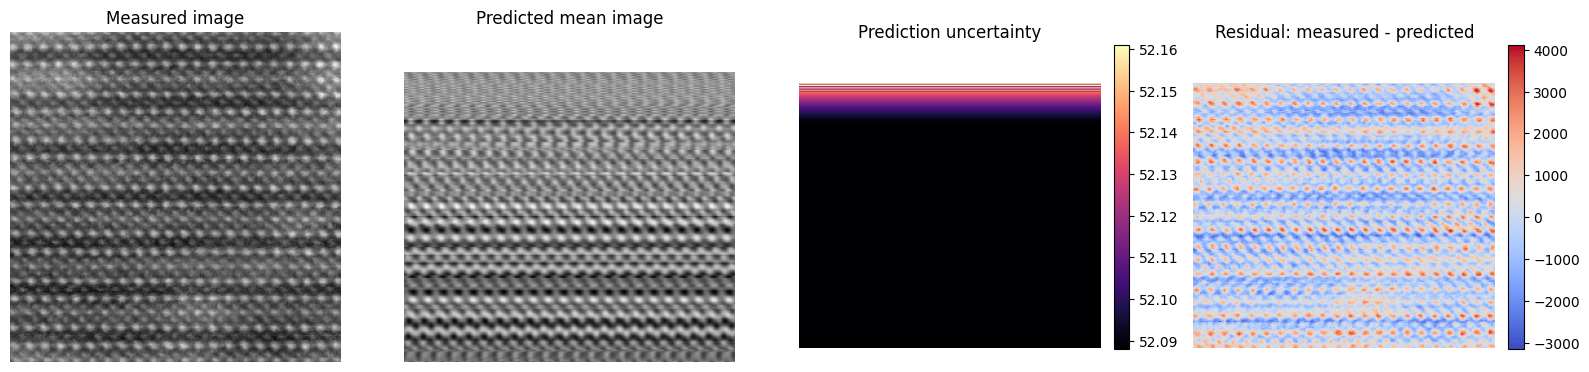

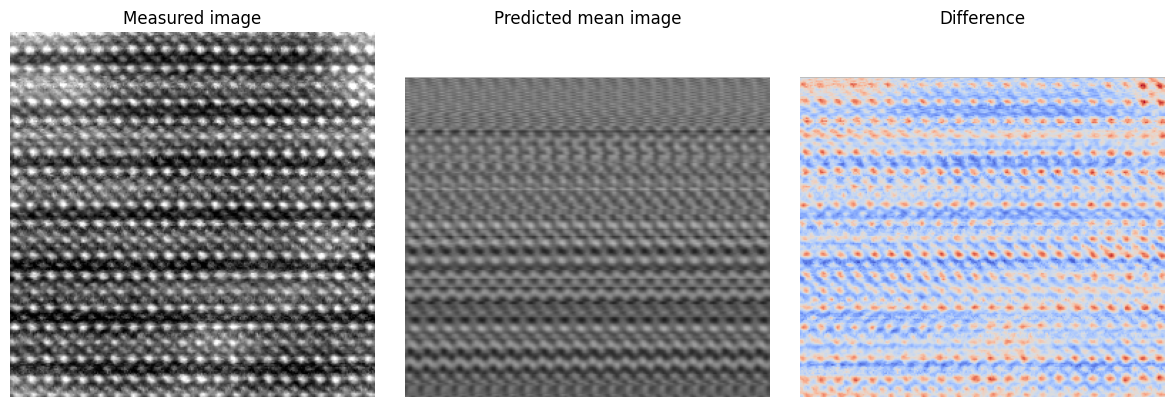

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Assumes:
# img_cor = measured/corrupted image
# pred_result = output from run_probabilistic_next_line_prediction(...)

pred_mean = pred_result["predicted_mean"]
pred_std  = pred_result["predicted_std"]
resid     = pred_result["residual"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_cor, cmap="gray")
axes[0].set_title("Measured image")
axes[0].axis("off")

axes[1].imshow(pred_mean, cmap="gray")
axes[1].set_title("Predicted mean image")
axes[1].axis("off")

im2 = axes[2].imshow(pred_std, cmap="magma")
axes[2].set_title("Prediction uncertainty")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(resid, cmap="coolwarm")
axes[3].set_title("Residual: measured - predicted")
axes[3].axis("off")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()
vmin = np.nanpercentile(img_cor, 1)
vmax = np.nanpercentile(img_cor, 99)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_cor, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Measured image")
axes[0].axis("off")

axes[1].imshow(pred_mean, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Predicted mean image")
axes[1].axis("off")

axes[2].imshow(img_cor - pred_mean, cmap="coolwarm")
axes[2].set_title("Difference")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Probabilistic Next-Line Prediction with X-Drift Compensation

This code implements a simple probabilistic reconstruction loop for a line-by-line scanned image. The central idea is to use the lines that have already been measured to predict what the next line should look like. When the next line is actually acquired, we compare it with the prediction and infer whether it has shifted in the \(x\)-direction.

The workflow is:

1. Stream the corrupted image line by line.
2. Accumulate a block of already measured lines.
3. Learn a Fourier-feature model of the local image structure.
4. Predict the next scan line probabilistically.
5. Compare the measured line with the predicted line.
6. Estimate the best horizontal shift between them.
7. Correct the measured line.
8. Use the corrected line to update the reconstruction model.
9. Repeat for the next line.

This turns drift compensation into a sequential state-estimation problem.

---

## Image Model

We assume that the measured image intensity can be represented as

$$
I(x,y) = f(x,y) + \epsilon,
$$

where \(f(x,y)\) is the latent image and \(\epsilon\) is measurement noise.

Because atomically resolved images often contain strong periodic structure, the latent image is approximated locally using Fourier features:

$$
f(x,y) =
\theta_0
+
\sum_{k=1}^{K}
\left[
a_k \cos\left(2\pi(g_{kx}x + g_{ky}y)\right)
+
b_k \sin\left(2\pi(g_{kx}x + g_{ky}y)\right)
\right].
$$

Here,

$$
\mathbf{g}_k = (g_{kx}, g_{ky})
$$

are spatial-frequency vectors selected from the Fourier transform of the already measured image block.

The code first identifies these dominant Fourier components from a block of acquired lines. These components serve as a compact basis for predicting nearby lines.

---

## Bayesian Fourier Regression

The Fourier model can be written compactly as

$$
f(x,y) = \boldsymbol{\phi}(x,y)^T \boldsymbol{\theta},
$$

where \(\boldsymbol{\phi}(x,y)\) is the vector of Fourier features and \(\boldsymbol{\theta}\) contains the unknown coefficients.

The measured pixel intensities in the current block are modeled as

$$
\mathbf{I}_{\mathrm{meas}} = \Phi \boldsymbol{\theta} + \boldsymbol{\epsilon},
$$

where \(\Phi\) is the design matrix evaluated at all measured pixel coordinates.

The code uses Bayesian linear regression by placing a Gaussian prior on the Fourier coefficients:

$$
\boldsymbol{\theta} \sim \mathcal{N}(0,\alpha^2 I),
$$

and assuming Gaussian measurement noise:

$$
\boldsymbol{\epsilon} \sim \mathcal{N}(0,\sigma_n^2 I).
$$

After observing the measured lines, the posterior distribution over coefficients is

$$
p(\boldsymbol{\theta} \mid \mathbf{I}_{\mathrm{meas}})
=
\mathcal{N}
\left(
\boldsymbol{\mu}_{\theta},
\Sigma_{\theta}
\right).
$$

The posterior mean \(\boldsymbol{\mu}_{\theta}\) gives the best-fit Fourier reconstruction, while the posterior covariance \(\Sigma_{\theta}\) gives uncertainty in the model coefficients.

---

## Predicting the Next Line

Once the model is fit to the current block, the code predicts the next line. For the next line at coordinate \(y+1\), the Fourier features are evaluated at all pixel positions \(x\). This gives a predictive distribution:

$$
p(\mathbf{I}_{\ast} \mid \mathbf{I}_{\mathrm{meas}})
=
\mathcal{N}
\left(
\boldsymbol{\mu}_{\ast},
\Sigma_{\ast}
\right).
$$

The predicted mean is

$$
\boldsymbol{\mu}_{\ast}
=
\Phi_{\ast}\boldsymbol{\mu}_{\theta},
$$

and the predictive variance is

$$
\boldsymbol{\sigma}_{\ast}^{2}
=
\mathrm{diag}
\left(
\Phi_{\ast}\Sigma_{\theta}\Phi_{\ast}^{T}
\right)
+
\sigma_n^2.
$$

Therefore, the next line is represented as

$$
I_{\ast}(x)
=
\mu_{\ast}(x)
\pm
\sigma_{\ast}(x).
$$

In the visualization, the predicted mean line is plotted together with a \(\pm 2\sigma\) uncertainty band.

---

## Inferring X-Drift from the Prediction

If the measured line does not match the predicted line, we assume that part of the mismatch may be due to horizontal drift. The model is

$$
I_{\mathrm{measured}}(x,y+1)
\approx
\mu_{\ast}(x-u_x),
$$

where \(u_x\) is the horizontal drift of the newly measured line.

The code searches over a small range of candidate shifts and chooses the one that minimizes an uncertainty-weighted mismatch:

$$
u_x^{\ast}
=
\arg\min_{u_x}
\sum_x
\frac{
\left[
I_{\mathrm{measured}}(x)
-
\mu_{\ast}(x-u_x)
\right]^2
}{
\sigma_{\ast}^2(x-u_x) + \sigma_0^2
}.
$$

Here, \(\sigma_0\) is an uncertainty floor that prevents the algorithm from over-trusting unrealistically small predicted uncertainties.

The code also allows a local affine intensity correction,

$$
I_{\mathrm{measured}}(x)
\approx
a \mu_{\ast}(x-u_x) + b,
$$

where \(a\) accounts for contrast changes and \(b\) accounts for intensity offset. This is useful because microscope images may have slowly varying brightness or contrast even when the spatial structure is correctly predicted.

---

## Correcting the Line

After estimating the best shift \(u_x^\ast\), the measured line is shifted back into the model coordinate system:

$$
I_{\mathrm{corrected}}(x)
=
I_{\mathrm{measured}}(x+u_x^\ast).
$$

The corrected line is then stored in the buffer and used to fit the next model. This is important: the model is trained on the corrected history, not simply on the raw corrupted scan.

This creates a feedback loop:

$$
\text{predict} \rightarrow \text{measure} \rightarrow \text{infer drift} \rightarrow \text{correct} \rightarrow \text{update}.
$$

---

## Why the Fourier Basis Can Be Frozen

The code includes the option

```python
freeze_fourier_basis=True

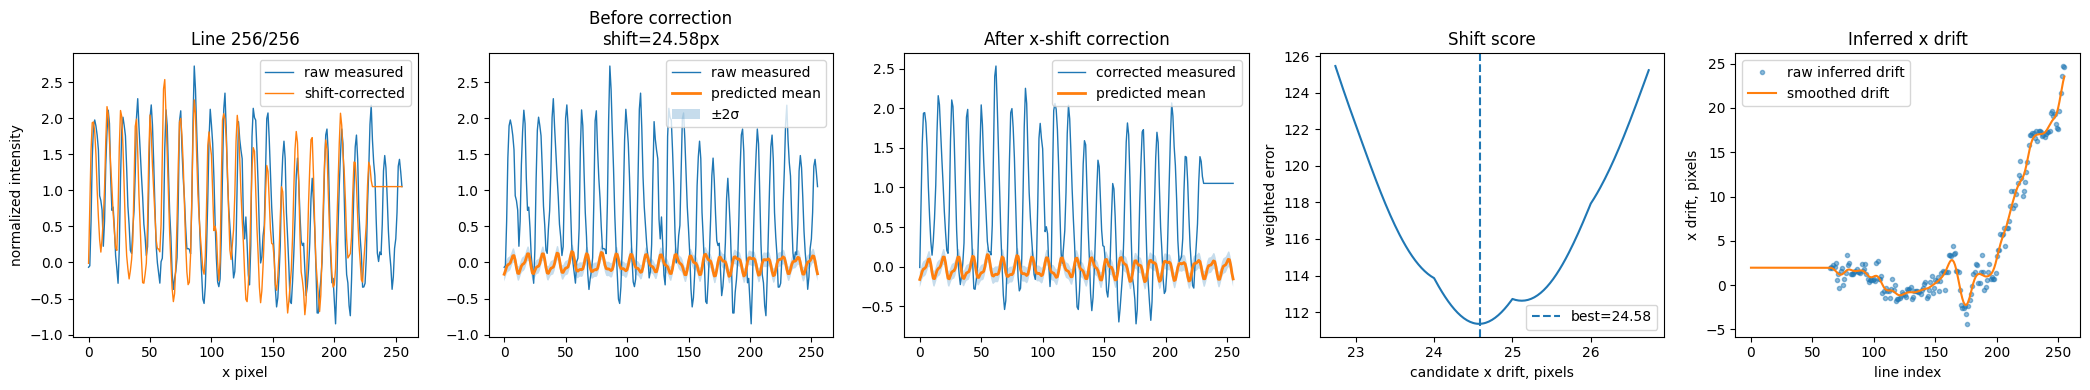

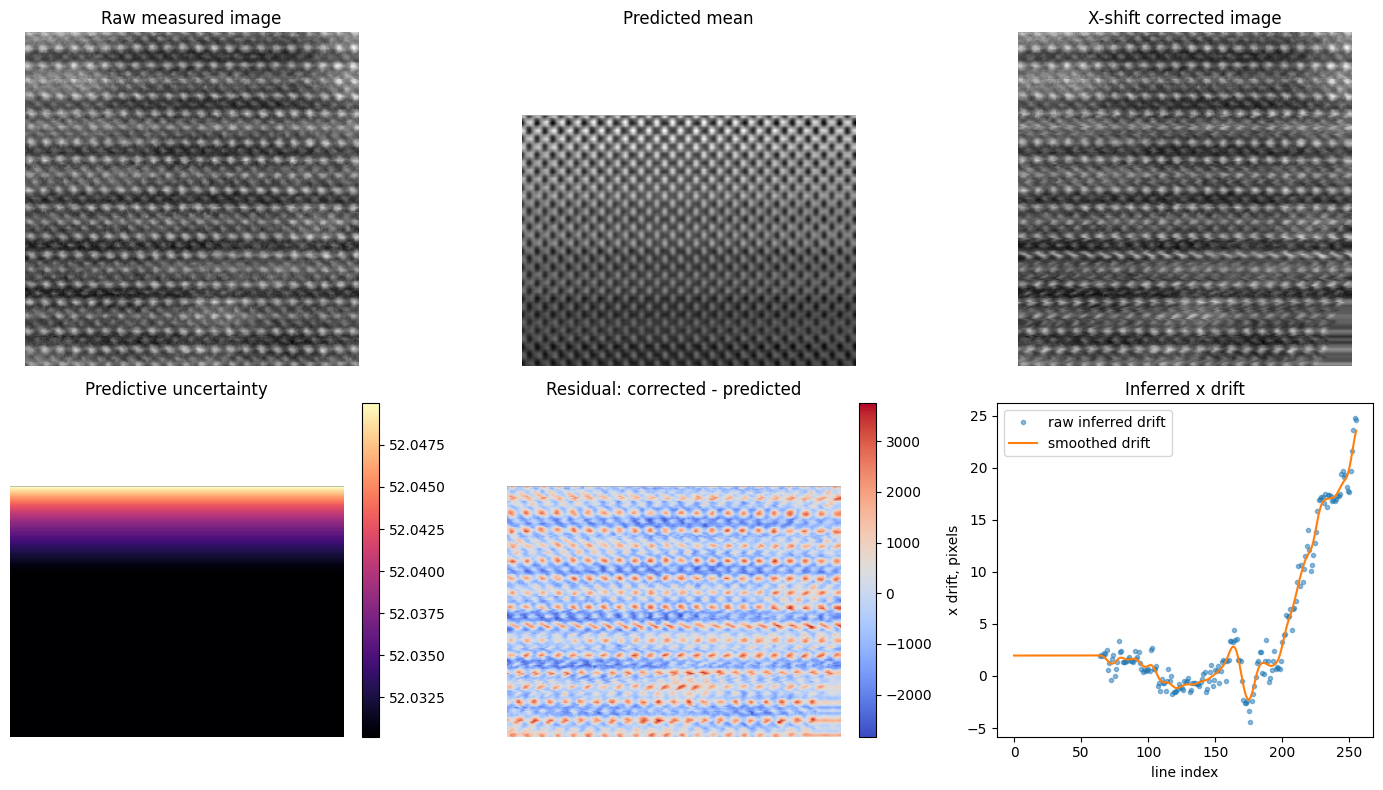

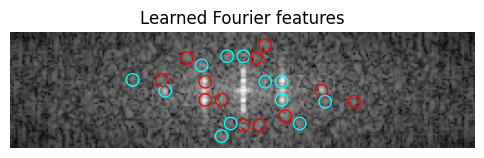

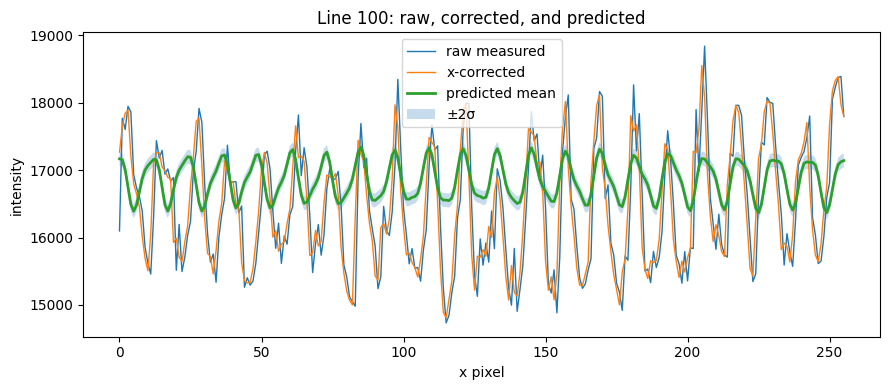

In [17]:
# ============================================================
# Probabilistic next-line prediction + x-drift compensation
#
# Assumes:
#   1. img_cor exists as a 2D numpy array
#   2. corrupted_image_scan_stream(img_cor) is already defined
#
# This code:
#   - streams img_cor line by line
#   - learns Fourier features from the first measured block
#   - predicts the next line probabilistically
#   - estimates the x-shift of the measured line relative to prediction
#   - corrects the measured line
#   - updates the model using corrected lines
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter, maximum_filter, gaussian_filter1d
from IPython.display import clear_output


# ============================================================
# 1. Basic utilities
# ============================================================

def normalize_for_model(img):
    """
    Normalize image intensity for numerical stability.
    """
    img = np.asarray(img, dtype=float)

    med = np.nanmedian(img)
    std = np.nanstd(img)

    if not np.isfinite(std) or std <= 0:
        std = 1.0

    img_n = (img - med) / std

    return img_n, med, std


def sample_line_at(line, coords):
    """
    Sample a 1D line at floating-point coordinates using linear interpolation.
    """
    line = np.asarray(line, dtype=float)
    W = len(line)

    x = np.arange(W, dtype=float)
    coords = np.asarray(coords, dtype=float)
    coords_clipped = np.clip(coords, 0, W - 1)

    return np.interp(coords_clipped, x, line)


def shift_line(line, shift):
    """
    Shift a 1D line by a subpixel amount.

    Positive shift moves image features to the right.

    Output:
        shifted[x] = line[x - shift]
    """
    W = len(line)
    x = np.arange(W, dtype=float)
    return sample_line_at(line, x - shift)


# ============================================================
# 2. Fourier feature selection
# ============================================================

def select_fourier_features_from_block(
    block,
    n_features=12,
    qmin=0.02,
    qmax=0.48,
    min_distance=4,
    smooth_sigma=1.0,
    duplicate_tol=0.01,
    plot=False,
):
    """
    Select dominant 2D Fourier components from a block of measured lines.

    Parameters
    ----------
    block : ndarray, shape (n_lines, width)
        Recently measured or corrected image block.

    n_features : int
        Number of reciprocal-space vectors to keep.

    Returns
    -------
    g_list : list of tuples
        Fourier vectors (gx, gy) in cycles/pixel.

    amp : ndarray
        Log FFT amplitude image for diagnostics.
    """

    block = np.asarray(block, dtype=float)
    H, W = block.shape

    data = np.nan_to_num(block, nan=np.nanmedian(block))
    data = data - np.mean(data)

    wy = np.hanning(H)
    wx = np.hanning(W)
    window = np.outer(wy, wx)

    data_w = data * window

    F = np.fft.fftshift(np.fft.fft2(data_w))
    amp = np.log1p(np.abs(F))

    if smooth_sigma is not None and smooth_sigma > 0:
        amp_s = gaussian_filter(amp, sigma=smooth_sigma)
    else:
        amp_s = amp

    cy = H / 2
    cx = W / 2

    yy, xx = np.indices((H, W))

    gx_grid = (xx - cx) / W
    gy_grid = (yy - cy) / H
    qr = np.sqrt(gx_grid**2 + gy_grid**2)

    valid = (qr >= qmin) & (qr <= qmax)

    local_max = amp_s == maximum_filter(
        amp_s,
        size=2 * min_distance + 1,
    )

    peak_mask = local_max & valid

    py_all, px_all = np.where(peak_mask)
    scores = amp_s[py_all, px_all]

    order = np.argsort(scores)[::-1]

    g_list = []

    for idx in order:
        px = px_all[idx]
        py = py_all[idx]

        gx = (px - cx) / W
        gy = (py - cy) / H

        g = np.array([gx, gy], dtype=float)

        duplicate = False

        for g_old in g_list:
            g_old = np.array(g_old, dtype=float)

            if np.linalg.norm(g - g_old) < duplicate_tol:
                duplicate = True

            if np.linalg.norm(g + g_old) < duplicate_tol:
                duplicate = True

        if duplicate:
            continue

        g_list.append((float(gx), float(gy)))

        if len(g_list) >= n_features:
            break

    # Fallback: if 2D peak picking failed, use dominant horizontal 1D FFT peaks.
    if len(g_list) == 0:
        row_data = data - np.mean(data, axis=1, keepdims=True)
        row_data = row_data * np.hanning(W)[None, :]

        Fr = np.fft.rfft(row_data, axis=1)
        power = np.mean(np.abs(Fr) ** 2, axis=0)
        freqs = np.fft.rfftfreq(W)

        valid_1d = (freqs >= qmin) & (freqs <= qmax)
        valid_1d[0] = False

        order_1d = np.argsort(power * valid_1d)[::-1]

        for k in order_1d:
            if not valid_1d[k]:
                continue
            g_list.append((float(freqs[k]), 0.0))
            if len(g_list) >= max(1, n_features // 3):
                break

    if plot:
        plt.figure(figsize=(5, 5))
        plt.imshow(amp, cmap="gray")
        plt.title("Selected Fourier features")

        for gx, gy in g_list:
            px = cx + gx * W
            py = cy + gy * H
            plt.scatter(px, py, s=80, facecolors="none", edgecolors="red")
            plt.scatter(cx - gx * W, cy - gy * H, s=80, facecolors="none", edgecolors="cyan")

        plt.axis("off")
        plt.show()

    return g_list, amp


# ============================================================
# 3. Bayesian Fourier reconstruction model
# ============================================================

def fourier_design_matrix(x, y, g_list, y_origin=0.0):
    """
    Build Fourier-feature design matrix.

    Features:
        1
        cos(2*pi*(gx*x + gy*(y-y_origin)))
        sin(2*pi*(gx*x + gy*(y-y_origin)))
    """

    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    y_local = y - y_origin

    cols = [np.ones_like(x)]

    for gx, gy in g_list:
        phase = 2 * np.pi * (gx * x + gy * y_local)
        cols.append(np.cos(phase))
        cols.append(np.sin(phase))

    Phi = np.column_stack(cols)

    return Phi


def fit_bayesian_fourier_model(
    block,
    y_start_global,
    g_list,
    noise_var=0.05**2,
    prior_var=5.0,
    ridge_jitter=1e-8,
):
    """
    Bayesian linear regression with Fourier features.

    Model:
        I = Phi theta + noise

    Prior:
        theta ~ N(0, prior_var I)

    Noise:
        noise ~ N(0, noise_var I)
    """

    block = np.asarray(block, dtype=float)
    H, W = block.shape

    yy_local, xx = np.indices((H, W))
    yy_global = y_start_global + yy_local

    x_flat = xx.ravel()
    y_flat = yy_global.ravel()
    values = block.ravel()

    Phi = fourier_design_matrix(
        x_flat,
        y_flat,
        g_list,
        y_origin=y_start_global,
    )

    D = Phi.shape[1]

    prior_precision = np.eye(D) / prior_var

    A = prior_precision + (Phi.T @ Phi) / noise_var
    A = A + ridge_jitter * np.eye(D)

    b = (Phi.T @ values) / noise_var

    try:
        post_cov = np.linalg.inv(A)
        post_mean = np.linalg.solve(A, b)
    except np.linalg.LinAlgError:
        post_cov = np.linalg.pinv(A)
        post_mean = post_cov @ b

    fitted = Phi @ post_mean
    residual = values - fitted
    residual_std = np.std(residual)

    model = {
        "g_list": g_list,
        "theta_mean": post_mean,
        "theta_cov": post_cov,
        "noise_var": noise_var,
        "prior_var": prior_var,
        "y_origin": y_start_global,
        "residual_std": residual_std,
    }

    return model


def predict_line_from_bayesian_fourier_model(
    model,
    width,
    y_global,
):
    """
    Predict one line probabilistically.

    Returns
    -------
    mean : ndarray
        Predictive mean line.

    std : ndarray
        Predictive standard deviation.

    var : ndarray
        Predictive variance.
    """

    x = np.arange(width, dtype=float)
    y = np.full(width, float(y_global))

    Phi_star = fourier_design_matrix(
        x,
        y,
        model["g_list"],
        y_origin=model["y_origin"],
    )

    theta_mean = model["theta_mean"]
    theta_cov = model["theta_cov"]
    noise_var = model["noise_var"]

    mean = Phi_star @ theta_mean

    model_var = np.einsum(
        "ij,jk,ik->i",
        Phi_star,
        theta_cov,
        Phi_star,
    )

    var = model_var + noise_var
    var = np.maximum(var, 1e-12)
    std = np.sqrt(var)

    return mean, std, var


# ============================================================
# 4. Drift inference from prediction
# ============================================================

def weighted_affine_fit_score(measured, predicted, variance):
    """
    Compute best weighted affine match:

        measured ≈ a * predicted + b

    Returns score, a, b.
    """

    measured = np.asarray(measured, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    variance = np.asarray(variance, dtype=float)

    w = 1.0 / (variance + 1e-12)

    valid = (
        np.isfinite(measured)
        & np.isfinite(predicted)
        & np.isfinite(w)
        & (w > 0)
    )

    if np.sum(valid) < 5:
        return np.inf, 1.0, 0.0

    y = measured[valid]
    p = predicted[valid]
    ww = w[valid]

    X0 = p
    X1 = np.ones_like(p)

    S00 = np.sum(ww * X0 * X0)
    S01 = np.sum(ww * X0 * X1)
    S11 = np.sum(ww * X1 * X1)

    t0 = np.sum(ww * X0 * y)
    t1 = np.sum(ww * X1 * y)

    M = np.array([[S00, S01], [S01, S11]])
    t = np.array([t0, t1])

    try:
        a, b = np.linalg.solve(M, t)
    except np.linalg.LinAlgError:
        a, b = 1.0, 0.0

    residual = y - (a * p + b)

    score = np.mean(ww * residual**2)

    return float(score), float(a), float(b)


def estimate_x_drift_from_prediction(
    measured_line,
    pred_mean,
    pred_std=None,
    shift_center=0.0,
    search_half_width=3.0,
    n_shifts=201,
    uncertainty_floor=0.05,
    prior_sigma=None,
):
    """
    Estimate x drift of measured line relative to predicted line.

    Convention:
        positive drift means the measured line is shifted to the right
        relative to the predicted line.

    We test:
        measured(x) ≈ pred_mean(x - drift)

    implemented as:
        pred_shifted = shift_line(pred_mean, drift)

    because shift_line(pred, positive) moves features right.
    """

    measured_line = np.asarray(measured_line, dtype=float)
    pred_mean = np.asarray(pred_mean, dtype=float)

    W = len(measured_line)

    if pred_std is None:
        pred_var = np.ones(W)
    else:
        pred_std = np.asarray(pred_std, dtype=float)
        pred_var = pred_std**2 + uncertainty_floor**2

    shifts = np.linspace(
        shift_center - search_half_width,
        shift_center + search_half_width,
        n_shifts,
    )

    scores = []
    gains = []
    offsets = []

    for u in shifts:
        pred_shifted = shift_line(pred_mean, u)
        var_shifted = shift_line(pred_var, u)

        score, gain, offset = weighted_affine_fit_score(
            measured=measured_line,
            predicted=pred_shifted,
            variance=var_shifted,
        )

        if prior_sigma is not None and prior_sigma > 0:
            score += ((u - shift_center) / prior_sigma) ** 2

        scores.append(score)
        gains.append(gain)
        offsets.append(offset)

    scores = np.asarray(scores)
    gains = np.asarray(gains)
    offsets = np.asarray(offsets)

    j = np.nanargmin(scores)

    best_shift = float(shifts[j])
    best_score = float(scores[j])
    best_gain = float(gains[j])
    best_offset = float(offsets[j])

    return {
        "best_shift": best_shift,
        "best_score": best_score,
        "best_gain": best_gain,
        "best_offset": best_offset,
        "shifts": shifts,
        "scores": scores,
        "gains": gains,
        "offsets": offsets,
    }


# ============================================================
# 5. Main streaming reconstruction + correction loop
# ============================================================

def run_probabilistic_prediction_with_x_shift_compensation(
    img_cor,
    min_lines=64,
    window_height=128,
    n_features=12,
    noise_var=0.05**2,
    prior_var=5.0,
    search_half_width=2.0,
    n_shifts=201,
    uncertainty_floor=0.05,
    smooth_drift_sigma=3,
    freeze_fourier_basis=True,
    animate=True,
    animation_delay=0.05,
    verbose=True,
):
    """
    Full probabilistic line prediction with x-drift compensation.

    Parameters
    ----------
    img_cor : ndarray
        Corrupted/measured image.

    min_lines : int
        Number of acquired/corrected lines needed before prediction begins.

    window_height : int
        Number of recent corrected lines used for model fitting.

    n_features : int
        Number of Fourier features.

    freeze_fourier_basis : bool
        If True, learn Fourier features once from the first sufficient block.
        This is usually more stable for atomically resolved data.

    Returns
    -------
    result : dict
    """

    img_cor = np.asarray(img_cor, dtype=float)
    H, W = img_cor.shape

    img_n, img_med, img_std = normalize_for_model(img_cor)

    stream = corrupted_image_scan_stream(img_n)

    buffer_lines = []
    buffer_indices = []

    corrected_image_n = np.full((H, W), np.nan, dtype=float)
    predicted_mean_n = np.full((H, W), np.nan, dtype=float)
    predicted_std_n = np.full((H, W), np.nan, dtype=float)
    residual_n = np.full((H, W), np.nan, dtype=float)
    zscore_n = np.full((H, W), np.nan, dtype=float)

    drift_raw = np.full(H, np.nan, dtype=float)
    drift_smooth = np.full(H, np.nan, dtype=float)

    pending_prediction = None

    g_list_fixed = None
    latest_fft_amp = None

    records = []

    last_shift_estimate = 0.0

    for _ in range(H):
        frame = next(stream)

        i = frame["line_index"]
        raw_line = frame["line"]

        line_for_update = raw_line.copy()

        shift_info = None

        # ----------------------------------------------------
        # Compare measured line with previous prediction.
        # ----------------------------------------------------
        if pending_prediction is not None and pending_prediction["line_index"] == i:

            mu = pending_prediction["mean"]
            std = pending_prediction["std"]

            shift_info = estimate_x_drift_from_prediction(
                measured_line=raw_line,
                pred_mean=mu,
                pred_std=std,
                shift_center=last_shift_estimate,
                search_half_width=search_half_width,
                n_shifts=n_shifts,
                uncertainty_floor=uncertainty_floor,
                prior_sigma=search_half_width,
            )

            best_shift = shift_info["best_shift"]
            best_score = shift_info["best_score"]
            best_gain = shift_info["best_gain"]
            best_offset = shift_info["best_offset"]

            last_shift_estimate = best_shift

            # Correct measured line back into prediction/model coordinates.
            # If positive best_shift means raw line is shifted right,
            # correction shifts it left.
            line_for_update = shift_line(raw_line, -best_shift)

            predicted_mean_n[i, :] = mu
            predicted_std_n[i, :] = std

            residual = line_for_update - mu
            zscore = residual / (std + uncertainty_floor)

            residual_n[i, :] = residual
            zscore_n[i, :] = zscore

            drift_raw[i] = best_shift

            records.append(
                {
                    "line_index": int(i),
                    "best_shift": float(best_shift),
                    "best_score": float(best_score),
                    "best_gain": float(best_gain),
                    "best_offset": float(best_offset),
                    "rms_residual_after_shift": float(np.sqrt(np.nanmean(residual**2))),
                    "mean_pred_std": float(np.nanmean(std)),
                    "max_abs_z": float(np.nanmax(np.abs(zscore))),
                }
            )

        # ----------------------------------------------------
        # Store corrected/current line.
        # ----------------------------------------------------
        corrected_image_n[i, :] = line_for_update

        buffer_lines.append(line_for_update.copy())
        buffer_indices.append(i)

        if len(buffer_lines) > window_height:
            buffer_lines = buffer_lines[-window_height:]
            buffer_indices = buffer_indices[-window_height:]

        # ----------------------------------------------------
        # Smooth drift estimate for visualization.
        # ----------------------------------------------------
        valid_drift = np.isfinite(drift_raw)

        if np.sum(valid_drift) >= 2:
            x_valid = np.where(valid_drift)[0]
            y_valid = drift_raw[valid_drift]

            drift_filled = np.interp(
                np.arange(H),
                x_valid,
                y_valid,
            )

            drift_smooth[:] = gaussian_filter1d(
                drift_filled,
                sigma=smooth_drift_sigma,
                mode="nearest",
            )

        # ----------------------------------------------------
        # Fit model and predict next line.
        # ----------------------------------------------------
        if len(buffer_lines) >= min_lines and i + 1 < H:

            block = np.vstack(buffer_lines)
            y_start = buffer_indices[0]

            if g_list_fixed is None or not freeze_fourier_basis:
                g_list, fft_amp = select_fourier_features_from_block(
                    block,
                    n_features=n_features,
                    qmin=0.02,
                    qmax=0.48,
                    min_distance=4,
                    smooth_sigma=1.0,
                    plot=False,
                )

                latest_fft_amp = fft_amp

                if freeze_fourier_basis:
                    g_list_fixed = g_list
                    if verbose:
                        print(f"Fourier basis learned at line {i}.")
                        print(f"Number of features: {len(g_list_fixed)}")
                else:
                    g_list_fixed = g_list

            if g_list_fixed is not None and len(g_list_fixed) > 0:

                model = fit_bayesian_fourier_model(
                    block,
                    y_start_global=y_start,
                    g_list=g_list_fixed,
                    noise_var=noise_var,
                    prior_var=prior_var,
                )

                mu_next, std_next, var_next = predict_line_from_bayesian_fourier_model(
                    model,
                    width=W,
                    y_global=i + 1,
                )

                pending_prediction = {
                    "line_index": i + 1,
                    "mean": mu_next,
                    "std": std_next,
                    "var": var_next,
                    "model": model,
                    "g_list": g_list_fixed,
                }

        # ----------------------------------------------------
        # Animation
        # ----------------------------------------------------
        if animate:
            clear_output(wait=True)

            fig, axes = plt.subplots(1, 5, figsize=(21, 4))

            # Raw and corrected line
            axes[0].plot(raw_line, label="raw measured", linewidth=1)
            axes[0].plot(line_for_update, label="shift-corrected", linewidth=1)
            axes[0].set_title(f"Line {i + 1}/{H}")
            axes[0].set_xlabel("x pixel")
            axes[0].set_ylabel("normalized intensity")
            axes[0].legend()

            # Prediction before correction
            if np.isfinite(predicted_mean_n[i, :]).any():
                mu = predicted_mean_n[i, :]
                std = predicted_std_n[i, :]

                axes[1].plot(raw_line, label="raw measured", linewidth=1)
                axes[1].plot(mu, label="predicted mean", linewidth=2)
                axes[1].fill_between(
                    np.arange(W),
                    mu - 2 * std,
                    mu + 2 * std,
                    alpha=0.25,
                    label="±2σ",
                )

                if shift_info is not None:
                    axes[1].set_title(
                        f"Before correction\nshift={shift_info['best_shift']:.2f}px"
                    )
                else:
                    axes[1].set_title("Before correction")

                axes[1].legend()

                axes[2].plot(line_for_update, label="corrected measured", linewidth=1)
                axes[2].plot(mu, label="predicted mean", linewidth=2)
                axes[2].fill_between(
                    np.arange(W),
                    mu - 2 * std,
                    mu + 2 * std,
                    alpha=0.25,
                )
                axes[2].set_title("After x-shift correction")
                axes[2].legend()

            else:
                axes[1].text(
                    0.5,
                    0.5,
                    "Waiting for\nprediction",
                    ha="center",
                    va="center",
                    transform=axes[1].transAxes,
                )
                axes[1].axis("off")

                axes[2].text(
                    0.5,
                    0.5,
                    "Waiting for\nprediction",
                    ha="center",
                    va="center",
                    transform=axes[2].transAxes,
                )
                axes[2].axis("off")

            # Shift score
            if shift_info is not None:
                axes[3].plot(shift_info["shifts"], shift_info["scores"])
                axes[3].axvline(
                    shift_info["best_shift"],
                    linestyle="--",
                    label=f"best={shift_info['best_shift']:.2f}",
                )
                axes[3].set_title("Shift score")
                axes[3].set_xlabel("candidate x drift, pixels")
                axes[3].set_ylabel("weighted error")
                axes[3].legend()
            else:
                axes[3].text(
                    0.5,
                    0.5,
                    "No shift\nestimate yet",
                    ha="center",
                    va="center",
                    transform=axes[3].transAxes,
                )
                axes[3].axis("off")

            # Drift trajectory
            axes[4].plot(drift_raw, ".", alpha=0.5, label="raw inferred drift")

            if np.isfinite(drift_smooth).any():
                axes[4].plot(drift_smooth, "-", label="smoothed drift")

            axes[4].set_title("Inferred x drift")
            axes[4].set_xlabel("line index")
            axes[4].set_ylabel("x drift, pixels")
            axes[4].legend()

            plt.tight_layout()
            plt.show()

            time.sleep(animation_delay)

    result = {
        "img_normalized": img_n,
        "img_median": img_med,
        "img_std": img_std,

        "corrected_image_normalized": corrected_image_n,
        "predicted_mean_normalized": predicted_mean_n,
        "predicted_std_normalized": predicted_std_n,
        "residual_normalized": residual_n,
        "zscore_normalized": zscore_n,

        "corrected_image": corrected_image_n * img_std + img_med,
        "predicted_mean": predicted_mean_n * img_std + img_med,
        "predicted_std": predicted_std_n * img_std,
        "residual": residual_n * img_std,
        "zscore": zscore_n,

        "drift_raw": drift_raw,
        "drift_smooth": drift_smooth,

        "records": records,
        "g_list": g_list_fixed,
        "latest_fft_amp": latest_fft_amp,
    }

    return result


# ============================================================
# 6. Run
# ============================================================

pred_shift_result = run_probabilistic_prediction_with_x_shift_compensation(
    img_cor,
    min_lines=64,
    window_height=128,
    n_features=12,
    noise_var=0.05**2,
    prior_var=5.0,
    search_half_width=2.0,
    n_shifts=201,
    uncertainty_floor=0.05,
    smooth_drift_sigma=3,
    freeze_fourier_basis=True,
    animate=True,
    animation_delay=0.05,
    verbose=True,
)


# ============================================================
# 7. Final visualization
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(img_cor, cmap="gray")
axes[0, 0].set_title("Raw measured image")
axes[0, 0].axis("off")

axes[0, 1].imshow(pred_shift_result["predicted_mean"], cmap="gray")
axes[0, 1].set_title("Predicted mean")
axes[0, 1].axis("off")

axes[0, 2].imshow(pred_shift_result["corrected_image"], cmap="gray")
axes[0, 2].set_title("X-shift corrected image")
axes[0, 2].axis("off")

im = axes[1, 0].imshow(pred_shift_result["predicted_std"], cmap="magma")
axes[1, 0].set_title("Predictive uncertainty")
axes[1, 0].axis("off")
plt.colorbar(im, ax=axes[1, 0], fraction=0.046)

im = axes[1, 1].imshow(pred_shift_result["residual"], cmap="coolwarm")
axes[1, 1].set_title("Residual: corrected - predicted")
axes[1, 1].axis("off")
plt.colorbar(im, ax=axes[1, 1], fraction=0.046)

axes[1, 2].plot(
    pred_shift_result["drift_raw"],
    ".",
    alpha=0.5,
    label="raw inferred drift",
)
axes[1, 2].plot(
    pred_shift_result["drift_smooth"],
    "-",
    label="smoothed drift",
)
axes[1, 2].set_title("Inferred x drift")
axes[1, 2].set_xlabel("line index")
axes[1, 2].set_ylabel("x drift, pixels")
axes[1, 2].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 8. Optional: show learned Fourier features
# ============================================================

if pred_shift_result["latest_fft_amp"] is not None and pred_shift_result["g_list"] is not None:
    fft_amp = pred_shift_result["latest_fft_amp"]
    g_list = pred_shift_result["g_list"]

    Hf, Wf = fft_amp.shape
    cx = Wf / 2
    cy = Hf / 2

    plt.figure(figsize=(6, 6))
    plt.imshow(fft_amp, cmap="gray")

    for gx, gy in g_list:
        px = cx + gx * Wf
        py = cy + gy * Hf

        px_neg = cx - gx * Wf
        py_neg = cy - gy * Hf

        plt.scatter(px, py, s=80, facecolors="none", edgecolors="red")
        plt.scatter(px_neg, py_neg, s=80, facecolors="none", edgecolors="cyan")

    plt.title("Learned Fourier features")
    plt.axis("off")
    plt.show()


# ============================================================
# 9. Optional: inspect one line
# ============================================================

line_index = min(100, img_cor.shape[0] - 1)

plt.figure(figsize=(9, 4))

plt.plot(
    img_cor[line_index],
    label="raw measured",
    linewidth=1,
)

plt.plot(
    pred_shift_result["corrected_image"][line_index],
    label="x-corrected",
    linewidth=1,
)

plt.plot(
    pred_shift_result["predicted_mean"][line_index],
    label="predicted mean",
    linewidth=2,
)

std = pred_shift_result["predicted_std"][line_index]
mu = pred_shift_result["predicted_mean"][line_index]

if np.isfinite(std).any():
    x = np.arange(img_cor.shape[1])
    plt.fill_between(
        x,
        mu - 2 * std,
        mu + 2 * std,
        alpha=0.25,
        label="±2σ",
    )

plt.title(f"Line {line_index}: raw, corrected, and predicted")
plt.xlabel("x pixel")
plt.ylabel("intensity")
plt.legend()
plt.tight_layout()
plt.show()

## Feature-Based Drift Correction with Symbolic Regression

This approach estimates image drift by tracking identifiable features between two images and then fitting an interpretable drift model to the measured feature displacements.

The important point is that this method is **reference-based**. It requires two images of the same region:

```python
img_ref  # reference image
img_cor  # corrupted or drifted image

Total matches: 653
Inliers after RANSAC: 544

Symbolic drift model:
ux(x,y) = +0.163*1 -0.04007*x^2 +0.05813*x*y -1.403*y^2 -0.001062*x^3 -0.4423*y^3 +0.01859*cos(1πx) -1.055*cos(2πy) -0.01857*cos(3πx) +0.207*sin(3πy) -0.631*cos(3πy) -0.01454*sin(πx)cos(πy)
uy(x,y) = +0.005762*1 -0.02549*y^2 +0.009447*x^2*y

ux fit RMSE = 0.563 px
uy fit RMSE = 0.180 px


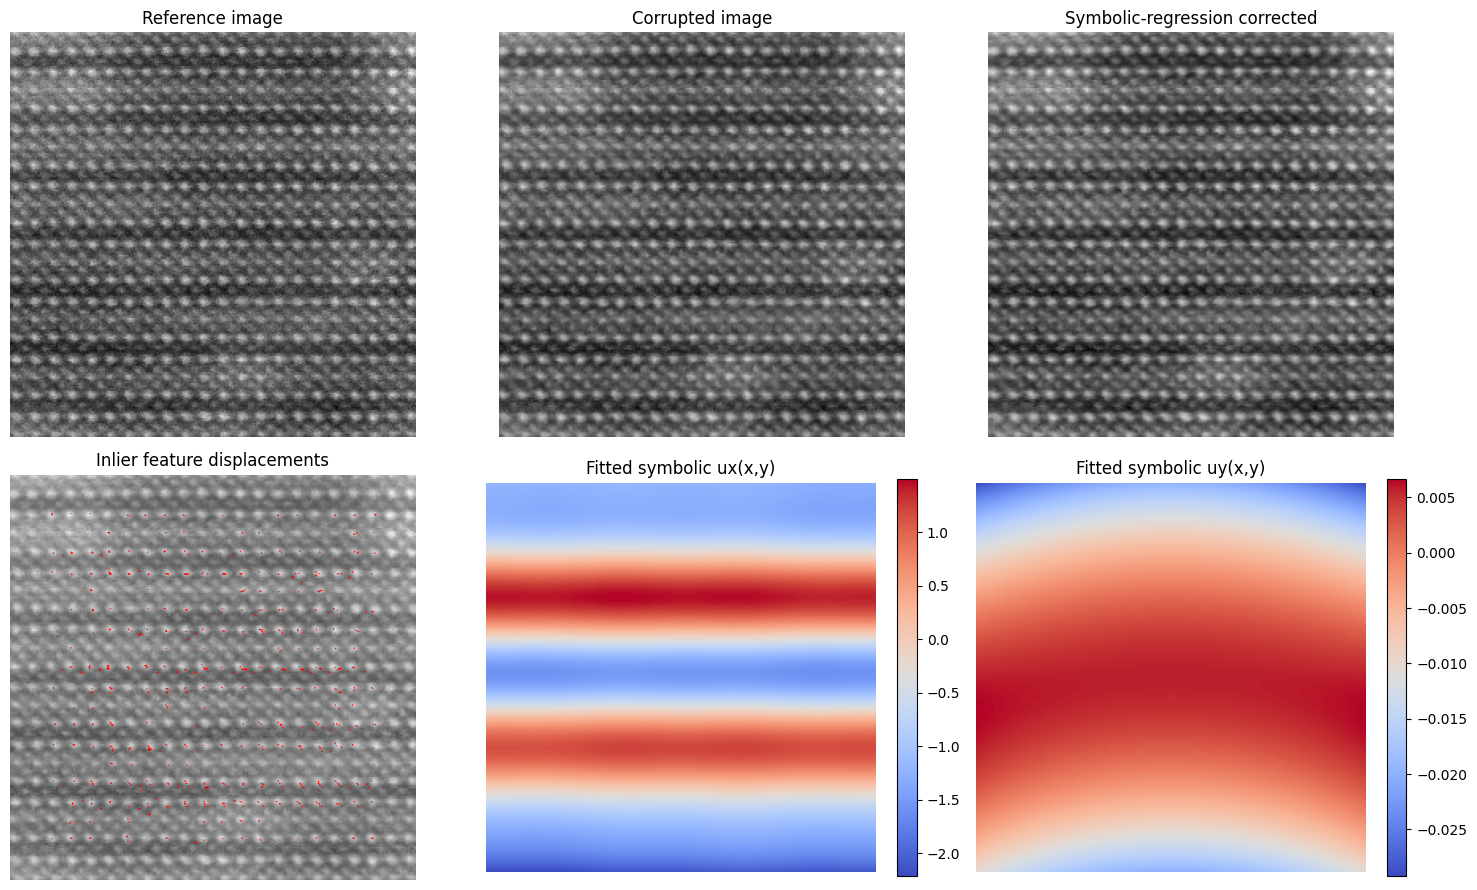

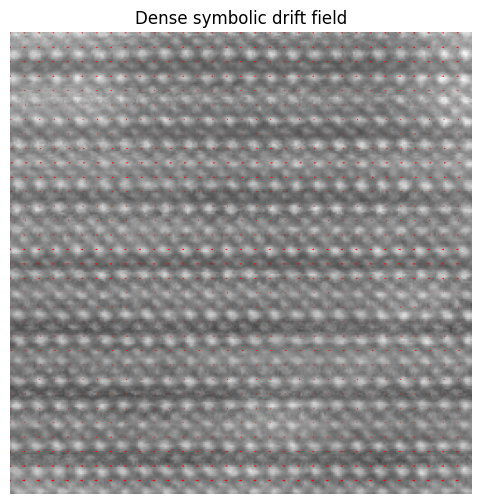

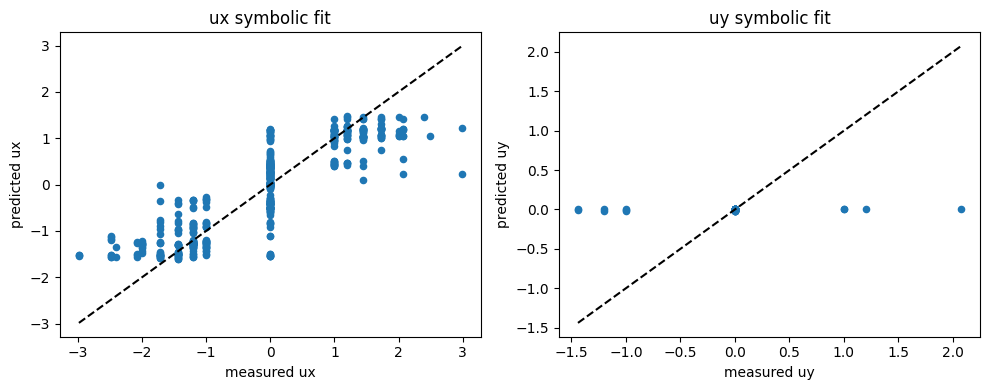

In [18]:
# ============================================================
# Feature-based drift correction with sparse symbolic regression
#
# Required:
#   img_ref : reference image
#   img_cor : corrupted / distorted image
#
# The method:
#   1. Detect features in img_ref and img_cor
#   2. Match features
#   3. Estimate sparse displacement vectors
#   4. Reject outliers using RANSAC
#   5. Fit symbolic drift models:
#
#          ux(x,y) = symbolic expression
#          uy(x,y) = symbolic expression
#
#   6. Evaluate dense drift field
#   7. Correct image by coordinate remapping
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, map_coordinates
from skimage.feature import ORB, match_descriptors
from skimage.measure import ransac
from skimage.transform import AffineTransform
from sklearn.linear_model import LassoCV, Lasso, Ridge
from sklearn.preprocessing import RobustScaler


# ============================================================
# 1. Utility functions
# ============================================================

def normalize_image_for_features(img, sigma=1.0):
    """
    Normalize image to [0, 1] for feature detection.
    Optionally apply mild Gaussian smoothing.
    """
    img = np.asarray(img, dtype=float)
    img = np.nan_to_num(img, nan=np.nanmedian(img))

    if sigma is not None and sigma > 0:
        img = gaussian_filter(img, sigma=sigma)

    p1, p99 = np.percentile(img, [1, 99])
    img_n = (img - p1) / (p99 - p1 + 1e-12)
    img_n = np.clip(img_n, 0, 1)

    return img_n


def coordinate_normalization(x, y, shape):
    """
    Normalize pixel coordinates to approximately [-1, 1].
    This improves symbolic regression conditioning.
    """
    H, W = shape

    xn = 2.0 * x / (W - 1) - 1.0
    yn = 2.0 * y / (H - 1) - 1.0

    return xn, yn


def coordinate_denormalization(xn, yn, shape):
    """
    Convert normalized coordinates back to pixel coordinates.
    """
    H, W = shape

    x = 0.5 * (xn + 1.0) * (W - 1)
    y = 0.5 * (yn + 1.0) * (H - 1)

    return x, y


# ============================================================
# 2. Feature detection and matching
# ============================================================

def detect_orb_features(
    img,
    n_keypoints=1000,
    fast_threshold=0.05,
    sigma=1.0,
):
    """
    Detect ORB keypoints and descriptors.
    """
    img_n = normalize_image_for_features(img, sigma=sigma)

    detector = ORB(
        n_keypoints=n_keypoints,
        fast_threshold=fast_threshold,
    )

    detector.detect_and_extract(img_n)

    keypoints_yx = detector.keypoints
    descriptors = detector.descriptors

    # Convert y,x to x,y
    keypoints_xy = keypoints_yx[:, ::-1]

    return keypoints_xy, descriptors, img_n


def match_feature_displacements(
    img_ref,
    img_mov,
    n_keypoints=1000,
    fast_threshold=0.05,
    sigma=1.0,
    cross_check=True,
    max_ratio=0.85,
):
    """
    Detect and match features between reference and moving image.

    Returns sparse displacement vectors:

        ux = x_mov - x_ref
        uy = y_mov - y_ref
    """

    kp_ref, desc_ref, ref_n = detect_orb_features(
        img_ref,
        n_keypoints=n_keypoints,
        fast_threshold=fast_threshold,
        sigma=sigma,
    )

    kp_mov, desc_mov, mov_n = detect_orb_features(
        img_mov,
        n_keypoints=n_keypoints,
        fast_threshold=fast_threshold,
        sigma=sigma,
    )

    matches = match_descriptors(
        desc_ref,
        desc_mov,
        cross_check=cross_check,
        max_ratio=max_ratio,
    )

    if len(matches) == 0:
        raise RuntimeError("No feature matches found. Try lowering fast_threshold.")

    ref_pts = kp_ref[matches[:, 0]]
    mov_pts = kp_mov[matches[:, 1]]

    x_ref = ref_pts[:, 0]
    y_ref = ref_pts[:, 1]

    x_mov = mov_pts[:, 0]
    y_mov = mov_pts[:, 1]

    ux = x_mov - x_ref
    uy = y_mov - y_ref

    result = {
        "kp_ref": kp_ref,
        "kp_mov": kp_mov,
        "matches": matches,
        "ref_pts": ref_pts,
        "mov_pts": mov_pts,
        "x_ref": x_ref,
        "y_ref": y_ref,
        "x_mov": x_mov,
        "y_mov": y_mov,
        "ux": ux,
        "uy": uy,
        "ref_norm": ref_n,
        "mov_norm": mov_n,
    }

    return result


# ============================================================
# 3. RANSAC outlier rejection
# ============================================================

def ransac_filter_matches(
    match_result,
    residual_threshold=3.0,
    min_samples=6,
    max_trials=2000,
):
    """
    Use an affine transform as a coarse model to remove bad matches.

    This does NOT mean the final drift model is affine.
    It is only used for robust outlier rejection.
    """

    ref_pts = match_result["ref_pts"]
    mov_pts = match_result["mov_pts"]

    if len(ref_pts) < min_samples:
        raise RuntimeError("Not enough matches for RANSAC.")

    model_robust, inliers = ransac(
        (ref_pts, mov_pts),
        AffineTransform,
        min_samples=min_samples,
        residual_threshold=residual_threshold,
        max_trials=max_trials,
    )

    x_ref = match_result["x_ref"][inliers]
    y_ref = match_result["y_ref"][inliers]

    x_mov = match_result["x_mov"][inliers]
    y_mov = match_result["y_mov"][inliers]

    ux = x_mov - x_ref
    uy = y_mov - y_ref

    filtered = dict(match_result)
    filtered["inliers"] = inliers
    filtered["ransac_model"] = model_robust
    filtered["x_ref_in"] = x_ref
    filtered["y_ref_in"] = y_ref
    filtered["x_mov_in"] = x_mov
    filtered["y_mov_in"] = y_mov
    filtered["ux_in"] = ux
    filtered["uy_in"] = uy

    print(f"Total matches: {len(inliers)}")
    print(f"Inliers after RANSAC: {np.sum(inliers)}")

    return filtered


# ============================================================
# 4. Symbolic regression feature library
# ============================================================

def build_symbolic_library(xn, yn, include_trig=True):
    """
    Build symbolic basis functions of normalized coordinates xn, yn.

    This is sparse symbolic regression:
        u(x,y) = sum_j c_j phi_j(x,y)

    The selected nonzero terms form the symbolic expression.
    """

    xn = np.asarray(xn, dtype=float)
    yn = np.asarray(yn, dtype=float)

    terms = []
    names = []

    def add(name, value):
        names.append(name)
        terms.append(value)

    # Polynomial terms
    add("1", np.ones_like(xn))
    add("x", xn)
    add("y", yn)

    add("x^2", xn**2)
    add("x*y", xn * yn)
    add("y^2", yn**2)

    add("x^3", xn**3)
    add("x^2*y", xn**2 * yn)
    add("x*y^2", xn * yn**2)
    add("y^3", yn**3)

    # Useful low-frequency nonlinear terms.
    # These help with oscillatory or creep-like distortions.
    if include_trig:
        for k in [1, 2, 3]:
            add(f"sin({k}πx)", np.sin(k * np.pi * xn))
            add(f"cos({k}πx)", np.cos(k * np.pi * xn))
            add(f"sin({k}πy)", np.sin(k * np.pi * yn))
            add(f"cos({k}πy)", np.cos(k * np.pi * yn))

        add("sin(πx)sin(πy)", np.sin(np.pi * xn) * np.sin(np.pi * yn))
        add("sin(πx)cos(πy)", np.sin(np.pi * xn) * np.cos(np.pi * yn))
        add("cos(πx)sin(πy)", np.cos(np.pi * xn) * np.sin(np.pi * yn))
        add("cos(πx)cos(πy)", np.cos(np.pi * xn) * np.cos(np.pi * yn))

    Phi = np.column_stack(terms)

    return Phi, names


def fit_sparse_symbolic_model(
    x,
    y,
    u,
    image_shape,
    include_trig=True,
    alpha=None,
    cv=5,
    threshold=1e-4,
    max_iter=100000,
):
    """
    Fit sparse symbolic regression model.

    Uses Lasso/LassoCV over an interpretable library.

    Parameters
    ----------
    x, y : arrays
        Pixel coordinates of sparse feature locations.

    u : array
        Displacement component to fit, either ux or uy.

    image_shape : tuple
        Shape of the image.

    include_trig : bool
        Whether to include sinusoidal basis functions.

    alpha : float or None
        If None, use cross-validated alpha.
        If given, use fixed Lasso alpha.

    Returns
    -------
    model : dict
        Contains coefficients, library names, scaling, and prediction function.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    u = np.asarray(u, dtype=float)

    xn, yn = coordinate_normalization(x, y, image_shape)

    Phi, names = build_symbolic_library(
        xn,
        yn,
        include_trig=include_trig,
    )

    # Scale non-constant columns for stable Lasso.
    # Keep constant term unscaled.
    scales = np.ones(Phi.shape[1])
    centers = np.zeros(Phi.shape[1])

    for j in range(1, Phi.shape[1]):
        centers[j] = np.mean(Phi[:, j])
        scales[j] = np.std(Phi[:, j]) + 1e-12

    Phi_scaled = Phi.copy()
    Phi_scaled[:, 1:] = (Phi[:, 1:] - centers[1:]) / scales[1:]

    n_samples = len(u)

    if alpha is None and n_samples >= max(8, cv):
        cv_eff = min(cv, n_samples)

        reg = LassoCV(
            cv=cv_eff,
            fit_intercept=False,
            max_iter=max_iter,
            n_alphas=100,
        )

    else:
        if alpha is None:
            alpha = 1e-4

        reg = Lasso(
            alpha=alpha,
            fit_intercept=False,
            max_iter=max_iter,
        )

    reg.fit(Phi_scaled, u)

    coef_scaled = reg.coef_.copy()

    # Convert coefficients back to unscaled library.
    coef = coef_scaled.copy()
    coef[1:] = coef_scaled[1:] / scales[1:]

    # Correct constant term for centering of columns.
    constant_correction = np.sum(coef_scaled[1:] * centers[1:] / scales[1:])
    coef[0] = coef_scaled[0] - constant_correction

    coef[np.abs(coef) < threshold] = 0.0

    pred = Phi @ coef
    residual = u - pred

    model = {
        "coef": coef,
        "names": names,
        "include_trig": include_trig,
        "image_shape": image_shape,
        "residual": residual,
        "rmse": float(np.sqrt(np.mean(residual**2))),
        "mae": float(np.mean(np.abs(residual))),
        "regressor": reg,
    }

    return model


def predict_symbolic_model(model, x, y):
    """
    Evaluate fitted symbolic model at pixel coordinates x, y.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    xn, yn = coordinate_normalization(
        x,
        y,
        model["image_shape"],
    )

    Phi, _ = build_symbolic_library(
        xn,
        yn,
        include_trig=model["include_trig"],
    )

    return Phi @ model["coef"]


def format_symbolic_expression(model, variable_name="u", precision=4):
    """
    Convert sparse model coefficients into readable equation.
    """
    coef = model["coef"]
    names = model["names"]

    pieces = []

    for c, name in zip(coef, names):
        if abs(c) > 0:
            pieces.append(f"{c:+.{precision}g}*{name}")

    if len(pieces) == 0:
        expr = f"{variable_name}(x,y) = 0"
    else:
        expr = f"{variable_name}(x,y) = " + " ".join(pieces)

    return expr


# ============================================================
# 5. Dense drift field and image correction
# ============================================================

def evaluate_dense_symbolic_drift(
    model_ux,
    model_uy,
    image_shape,
):
    """
    Evaluate ux(x,y), uy(x,y) on every image pixel.
    """
    H, W = image_shape
    yy, xx = np.indices((H, W), dtype=float)

    ux_dense = predict_symbolic_model(
        model_ux,
        xx.ravel(),
        yy.ravel(),
    ).reshape(H, W)

    uy_dense = predict_symbolic_model(
        model_uy,
        xx.ravel(),
        yy.ravel(),
    ).reshape(H, W)

    return ux_dense, uy_dense


def correct_image_with_symbolic_drift(
    img_mov,
    ux_dense,
    uy_dense,
    order=1,
    mode="reflect",
):
    """
    Correct moving/corrupted image using dense drift field.

    If matched displacement was:

        ux = x_mov - x_ref
        uy = y_mov - y_ref

    then the moving image is corrected by sampling:

        I_corr(x,y) = I_mov(x + ux(x,y), y + uy(x,y))
    """
    img_mov = np.asarray(img_mov, dtype=float)
    H, W = img_mov.shape

    yy, xx = np.indices((H, W), dtype=float)

    source_x = xx + ux_dense
    source_y = yy + uy_dense

    corrected = map_coordinates(
        img_mov,
        [source_y, source_x],
        order=order,
        mode=mode,
    )

    return corrected


# ============================================================
# 6. Full pipeline
# ============================================================

def run_feature_symbolic_drift_correction(
    img_ref,
    img_cor,
    n_keypoints=1500,
    fast_threshold=0.04,
    feature_sigma=1.0,
    max_ratio=0.85,
    ransac_residual_threshold=3.0,
    include_trig=True,
    lasso_alpha=None,
    symbolic_threshold=1e-4,
    interpolation_order=1,
    plot=True,
):
    """
    Full feature-based symbolic drift correction pipeline.
    """

    img_ref = np.asarray(img_ref, dtype=float)
    img_cor = np.asarray(img_cor, dtype=float)

    if img_ref.shape != img_cor.shape:
        raise ValueError("img_ref and img_cor must have the same shape.")

    H, W = img_ref.shape

    # Feature matching
    match_result = match_feature_displacements(
        img_ref,
        img_cor,
        n_keypoints=n_keypoints,
        fast_threshold=fast_threshold,
        sigma=feature_sigma,
        cross_check=True,
        max_ratio=max_ratio,
    )

    # RANSAC outlier rejection
    filt = ransac_filter_matches(
        match_result,
        residual_threshold=ransac_residual_threshold,
        min_samples=6,
        max_trials=2000,
    )

    x = filt["x_ref_in"]
    y = filt["y_ref_in"]
    ux = filt["ux_in"]
    uy = filt["uy_in"]

    if len(x) < 10:
        raise RuntimeError(
            "Too few inlier matches for symbolic regression. "
            "Try increasing n_keypoints or loosening feature thresholds."
        )

    # Fit symbolic drift models
    model_ux = fit_sparse_symbolic_model(
        x,
        y,
        ux,
        image_shape=img_ref.shape,
        include_trig=include_trig,
        alpha=lasso_alpha,
        threshold=symbolic_threshold,
    )

    model_uy = fit_sparse_symbolic_model(
        x,
        y,
        uy,
        image_shape=img_ref.shape,
        include_trig=include_trig,
        alpha=lasso_alpha,
        threshold=symbolic_threshold,
    )

    print("\nSymbolic drift model:")
    print(format_symbolic_expression(model_ux, variable_name="ux"))
    print(format_symbolic_expression(model_uy, variable_name="uy"))
    print(f"\nux fit RMSE = {model_ux['rmse']:.3f} px")
    print(f"uy fit RMSE = {model_uy['rmse']:.3f} px")

    # Dense field
    ux_dense, uy_dense = evaluate_dense_symbolic_drift(
        model_ux,
        model_uy,
        image_shape=img_ref.shape,
    )

    # Correct image
    img_corrected = correct_image_with_symbolic_drift(
        img_cor,
        ux_dense,
        uy_dense,
        order=interpolation_order,
        mode="reflect",
    )

    result = {
        "match_result": match_result,
        "filtered": filt,
        "model_ux": model_ux,
        "model_uy": model_uy,
        "ux_dense": ux_dense,
        "uy_dense": uy_dense,
        "img_corrected": img_corrected,
    }

    if plot:
        plot_feature_symbolic_result(
            img_ref,
            img_cor,
            result,
        )

    return result


# ============================================================
# 7. Visualization
# ============================================================

def plot_feature_symbolic_result(
    img_ref,
    img_cor,
    result,
    quiver_step=None,
):
    """
    Plot matches, fitted drift field, and corrected image.
    """

    filt = result["filtered"]
    ux_dense = result["ux_dense"]
    uy_dense = result["uy_dense"]
    img_corrected = result["img_corrected"]

    H, W = img_ref.shape

    if quiver_step is None:
        quiver_step = max(1, min(H, W) // 32)

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    axes[0, 0].imshow(img_ref, cmap="gray")
    axes[0, 0].set_title("Reference image")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(img_cor, cmap="gray")
    axes[0, 1].set_title("Corrupted image")
    axes[0, 1].axis("off")

    axes[0, 2].imshow(img_corrected, cmap="gray")
    axes[0, 2].set_title("Symbolic-regression corrected")
    axes[0, 2].axis("off")

    # Sparse matched displacement vectors
    axes[1, 0].imshow(img_cor, cmap="gray", alpha=0.75)
    axes[1, 0].quiver(
        filt["x_ref_in"],
        filt["y_ref_in"],
        filt["ux_in"],
        filt["uy_in"],
        color="red",
        angles="xy",
        scale_units="xy",
        scale=1,
        width=0.004,
    )
    axes[1, 0].set_title("Inlier feature displacements")
    axes[1, 0].axis("off")

    im1 = axes[1, 1].imshow(ux_dense, cmap="coolwarm")
    axes[1, 1].set_title("Fitted symbolic ux(x,y)")
    axes[1, 1].axis("off")
    plt.colorbar(im1, ax=axes[1, 1], fraction=0.046)

    im2 = axes[1, 2].imshow(uy_dense, cmap="coolwarm")
    axes[1, 2].set_title("Fitted symbolic uy(x,y)")
    axes[1, 2].axis("off")
    plt.colorbar(im2, ax=axes[1, 2], fraction=0.046)

    plt.tight_layout()
    plt.show()

    # Dense vector field
    yy, xx = np.indices(img_ref.shape)

    plt.figure(figsize=(6, 6))
    plt.imshow(img_cor, cmap="gray", alpha=0.75)
    plt.quiver(
        xx[::quiver_step, ::quiver_step],
        yy[::quiver_step, ::quiver_step],
        ux_dense[::quiver_step, ::quiver_step],
        uy_dense[::quiver_step, ::quiver_step],
        color="red",
        angles="xy",
        scale_units="xy",
        scale=1,
    )
    plt.title("Dense symbolic drift field")
    plt.axis("off")
    plt.show()

    # Fit residuals at feature points
    x = filt["x_ref_in"]
    y = filt["y_ref_in"]

    ux_pred = predict_symbolic_model(result["model_ux"], x, y)
    uy_pred = predict_symbolic_model(result["model_uy"], x, y)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].scatter(filt["ux_in"], ux_pred, s=20)
    lo = min(np.min(filt["ux_in"]), np.min(ux_pred))
    hi = max(np.max(filt["ux_in"]), np.max(ux_pred))
    axes[0].plot([lo, hi], [lo, hi], "k--")
    axes[0].set_xlabel("measured ux")
    axes[0].set_ylabel("predicted ux")
    axes[0].set_title("ux symbolic fit")

    axes[1].scatter(filt["uy_in"], uy_pred, s=20)
    lo = min(np.min(filt["uy_in"]), np.min(uy_pred))
    hi = max(np.max(filt["uy_in"]), np.max(uy_pred))
    axes[1].plot([lo, hi], [lo, hi], "k--")
    axes[1].set_xlabel("measured uy")
    axes[1].set_ylabel("predicted uy")
    axes[1].set_title("uy symbolic fit")

    plt.tight_layout()
    plt.show()


# ============================================================
# 8. Run
# ============================================================

symbolic_result = run_feature_symbolic_drift_correction(
    img_ref=img_ref,
    img_cor=img_cor,
    n_keypoints=1500,
    fast_threshold=0.04,
    feature_sigma=1.0,
    max_ratio=0.85,
    ransac_residual_threshold=3.0,
    include_trig=True,
    lasso_alpha=None,          # None means use LassoCV
    symbolic_threshold=1e-4,
    interpolation_order=1,
    plot=True,
)

img_corrected_symbolic = symbolic_result["img_corrected"]
ux_symbolic = symbolic_result["ux_dense"]
uy_symbolic = symbolic_result["uy_dense"]

## Algorithm: Streaming Synthetic-Reference Drift Correction

This algorithm performs drift correction when the image is acquired **line by line** and no external ideal reference image is available. The key assumption is that the sample contains an expected periodic structure, such as an atomic lattice. Instead of using a known reference image, the algorithm builds a synthetic periodic reference dynamically from the streaming data itself.

The goal is to estimate the scan drift during acquisition and correct the measured lines as they arrive.

---

## Problem Setup

In a raster-scanned image, the microscope acquires one line at a time. At scan line \(y\), the measured intensity is

$$
I_{\mathrm{meas}}(x,y).
$$

If the sample drifts during acquisition, then the measured image is a distorted version of the underlying true image:

$$
I_{\mathrm{meas}}(x,y)
\approx
I_{\mathrm{true}}(x-u_x(x,y),\,y-u_y(x,y))+\epsilon(x,y),
$$

where

$$
u_x(x,y)
$$

and

$$
u_y(x,y)
$$

are the horizontal and vertical drift fields.

For online correction, we simplify the model and assume that drift is approximately constant over a short block of scan lines:

$$
u_x(x,y) \approx u_x^{(b)},
$$

$$
u_y(x,y) \approx u_y^{(b)},
$$

where \(b\) labels the current block.

Thus, for a block \(B\), the measurement model becomes

$$
I_{\mathrm{meas}}(x,y)
\approx
I_{\mathrm{syn}}(x-u_x^{(b)},\,y-u_y^{(b)})
+
\epsilon(x,y).
$$

Here \(I_{\mathrm{syn}}\) is not an externally supplied reference image. It is a synthetic periodic reference learned from the already acquired and corrected data.

---

## Why a Synthetic Reference Is Needed

If there is no reference image, we cannot directly compute displacements such as

$$
u_x = x_{\mathrm{meas}} - x_{\mathrm{ref}},
$$

or

$$
u_y = y_{\mathrm{meas}} - y_{\mathrm{ref}}.
$$

Therefore, the algorithm constructs an internal reference model.

For an atomically resolved or periodic image, the average lattice structure can be represented by a Fourier expansion:

$$
I_{\mathrm{syn}}(x,y)
=
c_0
+
\sum_{k=1}^{K}
\left[
a_k
\cos\left(2\pi(g_{kx}x+g_{ky}y)\right)
+
b_k
\sin\left(2\pi(g_{kx}x+g_{ky}y)\right)
\right].
$$

The vectors

$$
\mathbf{g}_k=(g_{kx},g_{ky})
$$

are reciprocal-lattice vectors estimated from the first acquired lines.

This synthetic image captures the average periodic component of the data. It is not meant to reproduce every defect, dopant, vacancy, or local structural irregularity. Those should remain in the residual.

---

## Step 1: Warmup Acquisition

The algorithm begins by acquiring an initial number of lines:

$$
N_{\mathrm{warmup}}.
$$

These lines form a warmup block:

$$
I_{\mathrm{warmup}}(x,y),
\qquad
y=0,\ldots,N_{\mathrm{warmup}}-1.
$$

This block is used to estimate:

1. intensity normalization parameters,
2. the dominant Fourier periodicities,
3. the initial synthetic reference.

Because no external reference exists, the warmup block defines the initial coordinate frame. By convention, the drift in the warmup block is set to zero:

$$
u_x = 0,
\qquad
u_y = 0.
$$

This does not mean the warmup block is physically drift-free. It only defines the gauge of the reconstruction.

---

## Step 2: Robust Intensity Normalization

The intensity scale is estimated from the warmup data only. Each line is normalized as

$$
I_{\mathrm{norm}}(x)
=
\frac{I(x)-m}{s},
$$

where \(m\) is the median intensity and \(s\) is a robust intensity scale.

A typical scale is

$$
s=P_{99}-P_1,
$$

where \(P_{99}\) and \(P_1\) are the 99th and 1st percentiles of the warmup intensities.

This normalization improves numerical stability and prevents bright outliers from dominating the fitting.

---

## Step 3: Estimate Fourier Periodicities

The warmup block is windowed and Fourier transformed:

$$
\mathcal{F}\{I_{\mathrm{warmup}}\}(g_x,g_y).
$$

Strong peaks in the Fourier amplitude correspond to dominant periodicities in the image. The algorithm selects a set of reciprocal vectors:

$$
\mathbf{g}_1,\mathbf{g}_2,\ldots,\mathbf{g}_K.
$$

Each reciprocal vector is expressed in cycles per pixel:

$$
\mathbf{g}_k=(g_{kx},g_{ky}).
$$

After the warmup phase, these vectors are kept fixed.

This is important. If the reciprocal vectors were re-estimated too often, the synthetic reference could absorb scan drift by changing its lattice geometry. Keeping the lattice vectors fixed makes the drift estimate meaningful relative to the initial learned lattice frame.

---

## Step 4: Build the Synthetic Periodic Reference

Using the selected Fourier vectors, the synthetic reference is modeled as

$$
I_{\mathrm{syn}}(x,y)
=
c_0
+
\sum_{k=1}^{K}
\left[
a_k
\cos\left(2\pi\mathbf{g}_k\cdot\mathbf{r}\right)
+
b_k
\sin\left(2\pi\mathbf{g}_k\cdot\mathbf{r}\right)
\right],
$$

where

$$
\mathbf{r}=(x,y).
$$

Equivalently,

$$
\mathbf{g}_k\cdot\mathbf{r}
=
g_{kx}x+g_{ky}y.
$$

The model can be written in linear-regression form:

$$
I_{\mathrm{syn}}(x,y)
=
\boldsymbol{\phi}(x,y)^T\boldsymbol{\theta},
$$

where \(\boldsymbol{\phi}(x,y)\) is the vector of Fourier features and \(\boldsymbol{\theta}\) is the vector of unknown coefficients.

The coefficients are fit using ridge regression:

$$
\boldsymbol{\theta}^{\ast}
=
\arg\min_{\boldsymbol{\theta}}
\left\|
\mathbf{I}_{\mathrm{corr}}
-
\Phi\boldsymbol{\theta}
\right\|^2
+
\lambda
\left\|
\boldsymbol{\theta}
\right\|^2.
$$

Here:

- \(\mathbf{I}_{\mathrm{corr}}\) contains the corrected lines acquired so far,
- \(\Phi\) is the Fourier-feature design matrix,
- \(\lambda\) is the ridge regularization strength.

During warmup, the corrected lines are just the acquired lines, because the warmup block defines zero drift.

---

## Step 5: Predict the Next Block

Once the synthetic reference has been initialized, the algorithm processes future scan lines in small blocks.

For a new block \(B\), containing rows

$$
y_b,\ldots,y_b+h-1,
$$

the algorithm generates a synthetic prediction for the same coordinates:

$$
I_{\mathrm{syn}}(x,y),
\qquad
(x,y)\in B.
$$

However, the incoming measured block may be shifted by drift. Therefore, for a candidate drift \((u_x,u_y)\), the predicted block is

$$
I_{\mathrm{pred}}(x,y;u_x,u_y)
=
I_{\mathrm{syn}}(x-u_x,\,y-u_y).
$$

This expresses the idea that the measured block is a shifted observation of the synthetic reference.

---

## Step 6: Estimate Block Drift

The algorithm searches for the drift \((u_x,u_y)\) that makes the measured block best match the synthetic prediction.

A simple least-squares objective would be

$$
(u_x^{\ast},u_y^{\ast})
=
\arg\min_{u_x,u_y}
\sum_{(x,y)\in B}
\left[
I_{\mathrm{meas}}(x,y)
-
I_{\mathrm{syn}}(x-u_x,y-u_y)
\right]^2.
$$

However, real microscope data may have contrast changes, offsets, defects, and local nonperiodic structure. Therefore, the code uses two improvements:

1. local affine intensity correction,
2. robust Huber loss.

The affine correction assumes

$$
I_{\mathrm{meas}}(x,y)
\approx
a\,I_{\mathrm{syn}}(x-u_x,y-u_y)+b,
$$

where \(a\) accounts for contrast and \(b\) accounts for offset.

The residual is

$$
r(x,y)
=
I_{\mathrm{meas}}(x,y)
-
a\,I_{\mathrm{syn}}(x-u_x,y-u_y)
-
b.
$$

The robust objective is

$$
(u_x^{\ast},u_y^{\ast},a^{\ast},b^{\ast})
=
\arg\min_{u_x,u_y,a,b}
\sum_{(x,y)\in B}
\rho(r(x,y)),
$$

where \(\rho\) is the Huber loss:

$$
\rho(r)
=
\begin{cases}
\frac{1}{2}r^2, & |r|\leq \delta, \\
\delta\left(|r|-\frac{1}{2}\delta\right), & |r|>\delta.
\end{cases}
$$

The Huber loss behaves like squared error for small residuals but is less sensitive to large outliers.

This is important because defects and real structural deviations should not dominate the drift estimate.

---

## Step 7: Correct the Measured Block

Once the best drift is found, the measured block is corrected by inverse coordinate remapping.

The drift model is

$$
I_{\mathrm{meas}}(x,y)
\approx
I_{\mathrm{syn}}(x-u_x,y-u_y).
$$

Therefore, the corrected block is obtained by sampling the measured block at shifted coordinates:

$$
I_{\mathrm{corr}}(x,y)
=
I_{\mathrm{meas}}(x+u_x,y+u_y).
$$

This is a subpixel interpolation operation.

In strict online operation, the algorithm often applies only \(x\)-correction immediately:

$$
I_{\mathrm{corr}}(x,y)
=
I_{\mathrm{meas}}(x+u_x,y).
$$

The reason is that vertical correction may require lines outside the current block, including future lines that have not yet been acquired.

Thus, the code estimates both \(u_x\) and \(u_y\), but it can choose to apply only \(u_x\) online and store \(u_y\) for later delayed correction or post-processing.

---

## Step 8: Update the Corrected History

After correction, the corrected block is appended to the corrected data history.

The algorithm maintains two streams internally:

1. the raw streamed image,
2. the corrected streamed image.

The corrected image is the one used to update the synthetic reference.

This is important because using uncorrected lines to update the reference would gradually build drift into the synthetic model.

---

## Step 9: Slowly Update the Synthetic Reference

After each corrected block is added, the Fourier coefficients of the synthetic reference are refit using the corrected lines acquired so far.

Let

$$
\boldsymbol{\theta}_{\mathrm{new}}
$$

be the newly fitted coefficient vector. Instead of replacing the previous coefficients immediately, the code performs a slow update:

$$
\boldsymbol{\theta}_{t+1}
=
(1-\alpha)\boldsymbol{\theta}_{t}
+
\alpha\boldsymbol{\theta}_{\mathrm{new}}.
$$

Here

$$
0<\alpha<1
$$

is the reference update rate.

A small \(\alpha\) prevents the synthetic reference from chasing drift. This is one of the most important stabilizing mechanisms in the algorithm.

---

## Step 10: Repeat for the Full Stream

The algorithm repeats the following loop until the stream ends:

$$
\text{receive block}
\rightarrow
\text{estimate drift}
\rightarrow
\text{correct block}
\rightarrow
\text{update corrected history}
\rightarrow
\text{update synthetic reference}.
$$

This produces:

- a raw streamed image,
- a corrected streamed image,
- a synthetic reference image,
- a drift trajectory,
- block-level fit diagnostics.

---

## Interpretation of the Drift

Because there is no external reference image, the estimated drift is not absolute. It is drift relative to the initial synthetic reference learned from the warmup block.

The warmup block defines the coordinate frame:

$$
u_x = 0,
\qquad
u_y = 0.
$$

All later drift values are measured relative to this convention.

This gauge ambiguity is unavoidable without an external reference. A slow global distortion could be interpreted either as scan drift or as a change in the average lattice. The algorithm resolves this ambiguity by:

1. fixing the Fourier vectors after warmup,
2. updating coefficients slowly,
3. centering drift search near the previous estimate,
4. assuming drift changes smoothly over time.

---

## Why Defects Are Preserved

The synthetic reference only models the average periodic component:

$$
I_{\mathrm{syn}}(x,y).
$$

The residual after correction is

$$
R(x,y)
=
I_{\mathrm{corr}}(x,y)
-
I_{\mathrm{syn}}(x,y).
$$

This residual should contain:

- defects,
- vacancies,
- dopants,
- local strain,
- contamination,
- nonperiodic features,
- noise,
- remaining drift errors.

The goal is not to make the residual zero. The goal is to use the periodic component as a stable ruler while preserving nonperiodic sample information in the residual.

---

## What Makes the Algorithm Streaming-Only

The main function receives a stream, not a full image:

```python
run_dynamic_synthetic_reference_from_stream(stream=stream)

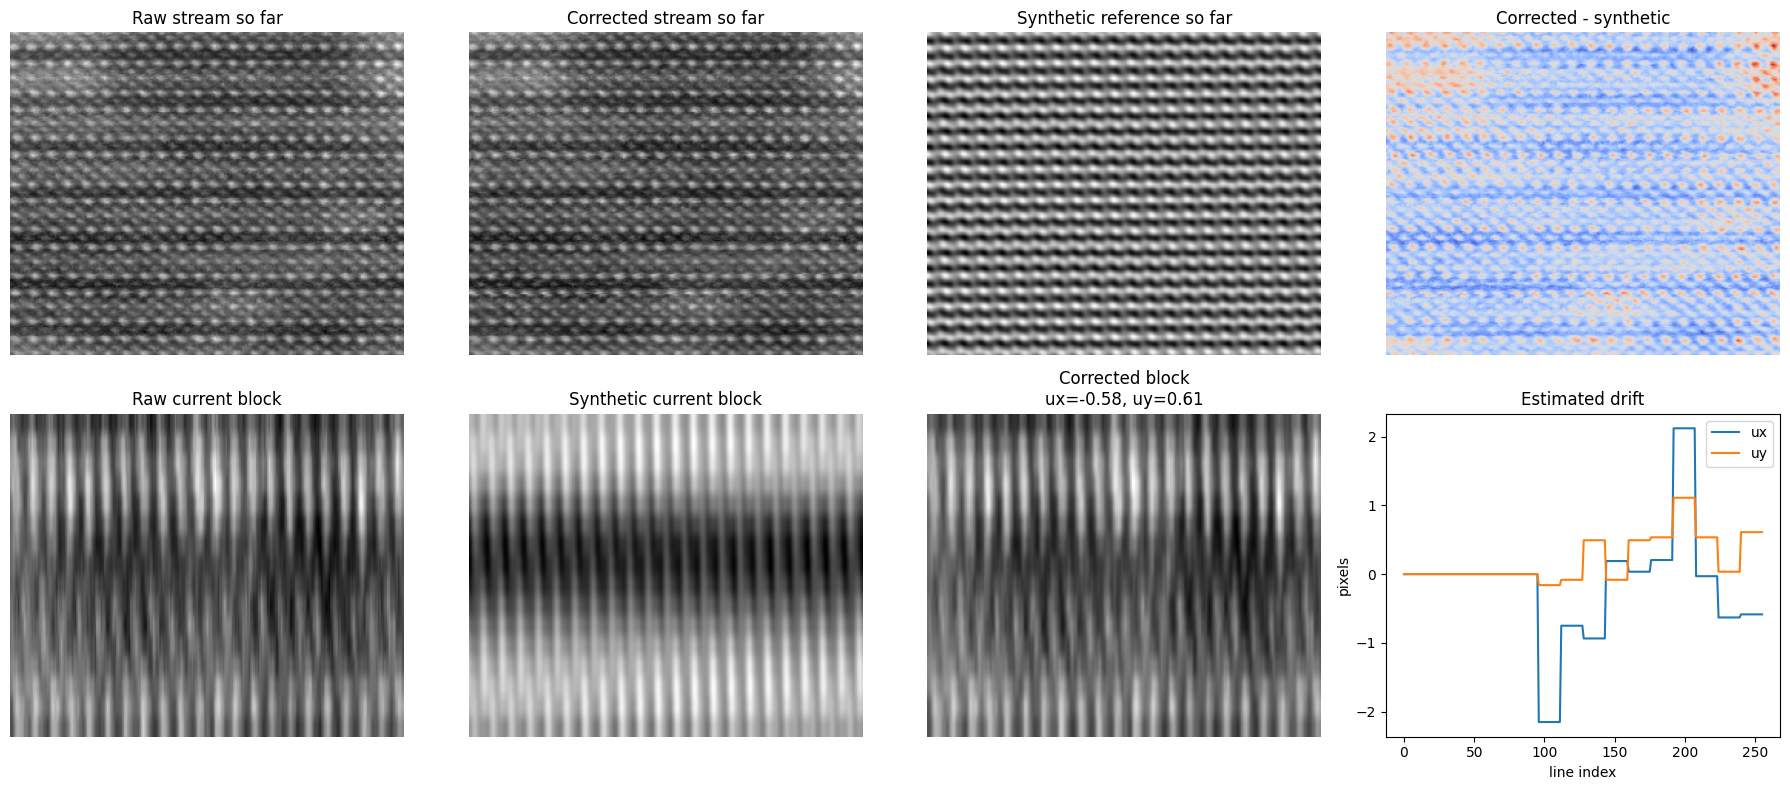

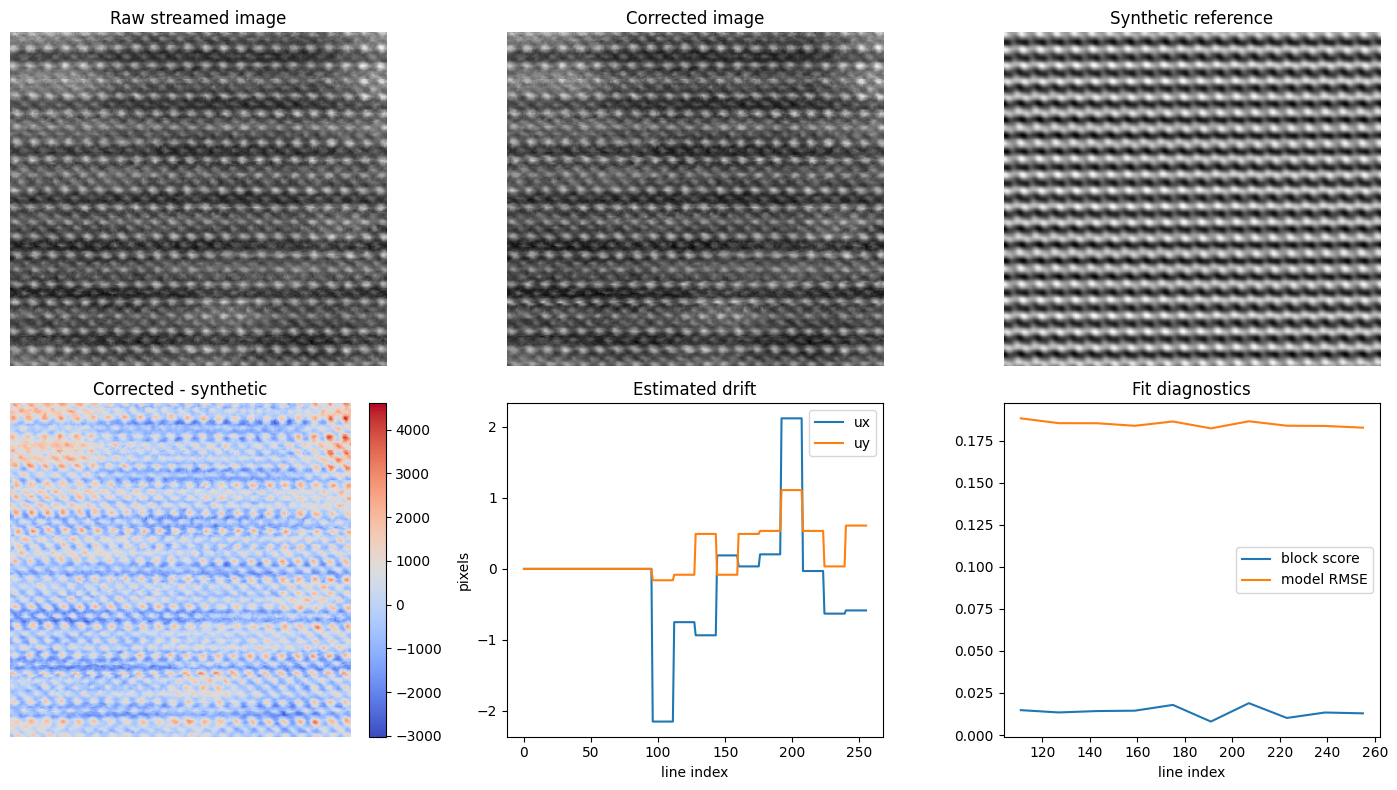

In [19]:
# ============================================================
# Strict streaming-only dynamic synthetic lattice reference
#
# The algorithm does NOT access the full img_cor internally.
# It only sees frames from:
#
#     stream = corrupted_image_scan_stream(img_cor)
#
# Each frame must contain:
#     frame["line_index"]
#     frame["line"]
#
# Optional:
#     frame["partial_image"] for display only
#
# Main idea:
#   1. Collect warmup lines.
#   2. Estimate average periodic lattice from warmup block.
#   3. Build synthetic Fourier reference from corrected acquired lines.
#   4. For each new block, estimate shift relative to synthetic reference.
#   5. Correct the block.
#   6. Update synthetic reference using only corrected acquired lines.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter, maximum_filter, map_coordinates
from IPython.display import clear_output


# ============================================================
# 1. Basic utilities
# ============================================================

def robust_normalizer_from_lines(lines):
    """
    Estimate robust normalization constants from warmup lines only.
    """
    data = np.vstack(lines).astype(float)
    med = np.nanmedian(data)
    p1, p99 = np.nanpercentile(data, [1, 99])
    scale = p99 - p1

    if not np.isfinite(scale) or scale <= 0:
        scale = np.nanstd(data)

    if not np.isfinite(scale) or scale <= 0:
        scale = 1.0

    return med, scale


def normalize_line(line, med, scale):
    line = np.asarray(line, dtype=float)
    line = np.nan_to_num(line, nan=np.nanmedian(line))
    return (line - med) / scale


def restore_image_units(img_n, med, scale):
    return img_n * scale + med


def hann2d(shape):
    H, W = shape
    return np.outer(np.hanning(H), np.hanning(W))


def huber_loss(r, delta=1.5):
    r = np.asarray(r, dtype=float)
    a = np.abs(r)

    return np.where(
        a <= delta,
        0.5 * r**2,
        delta * (a - 0.5 * delta),
    )


def affine_match_score(measured, predicted, huber_delta=1.5):
    """
    Robustly compare measured block with predicted block,
    allowing contrast/offset correction:

        measured ≈ a * predicted + b
    """

    measured = np.asarray(measured, dtype=float).ravel()
    predicted = np.asarray(predicted, dtype=float).ravel()

    valid = np.isfinite(measured) & np.isfinite(predicted)

    if np.sum(valid) < 10:
        return np.inf, 1.0, 0.0

    y = measured[valid]
    p = predicted[valid]

    A = np.column_stack([p, np.ones_like(p)])

    try:
        gain, offset = np.linalg.lstsq(A, y, rcond=None)[0]
    except np.linalg.LinAlgError:
        gain, offset = 1.0, 0.0

    residual = y - (gain * p + offset)
    score = np.mean(huber_loss(residual, delta=huber_delta))

    return float(score), float(gain), float(offset)


# ============================================================
# 2. Fourier features from warmup block
# ============================================================

def estimate_fourier_features_from_warmup(
    warmup_block,
    n_features=12,
    qmin=0.02,
    qmax=0.48,
    min_distance=4,
    smooth_sigma=1.0,
    duplicate_tol=0.01,
    plot=True,
):
    """
    Estimate Fourier vectors g=(gx,gy) from the warmup block.

    This is the only time we estimate lattice vectors.
    Later, we keep these vectors fixed to prevent the synthetic reference
    from chasing drift.
    """

    block = np.asarray(warmup_block, dtype=float)
    H, W = block.shape

    data = np.nan_to_num(block, nan=np.nanmedian(block))
    data = data - np.mean(data)
    data = data * hann2d(block.shape)

    F = np.fft.fftshift(np.fft.fft2(data))
    amp = np.log1p(np.abs(F))

    if smooth_sigma is not None and smooth_sigma > 0:
        amp_s = gaussian_filter(amp, sigma=smooth_sigma)
    else:
        amp_s = amp

    cy = H / 2
    cx = W / 2

    yy, xx = np.indices((H, W))

    gx_grid = (xx - cx) / W
    gy_grid = (yy - cy) / H
    q_grid = np.sqrt(gx_grid**2 + gy_grid**2)

    valid = (q_grid >= qmin) & (q_grid <= qmax)

    local_max = amp_s == maximum_filter(
        amp_s,
        size=2 * min_distance + 1,
    )

    peak_mask = valid & local_max

    py_all, px_all = np.where(peak_mask)

    if len(px_all) == 0:
        raise RuntimeError("No Fourier peaks found in warmup block.")

    scores = amp_s[py_all, px_all]
    order = np.argsort(scores)[::-1]

    g_list = []

    for idx in order:
        px = px_all[idx]
        py = py_all[idx]

        gx = (px - cx) / W
        gy = (py - cy) / H

        g = np.array([gx, gy], dtype=float)

        duplicate = False

        for old in g_list:
            old = np.array(old, dtype=float)

            if np.linalg.norm(g - old) < duplicate_tol:
                duplicate = True

            if np.linalg.norm(g + old) < duplicate_tol:
                duplicate = True

        if duplicate:
            continue

        # Consistent sign convention.
        if gx < 0:
            gx = -gx
            gy = -gy

        g_list.append((float(gx), float(gy)))

        if len(g_list) >= n_features:
            break

    if plot:
        plt.figure(figsize=(6, 6))
        plt.imshow(amp, cmap="gray")

        for j, (gx, gy) in enumerate(g_list):
            px = cx + gx * W
            py = cy + gy * H

            pxm = cx - gx * W
            pym = cy - gy * H

            plt.scatter(px, py, s=90, facecolors="none", edgecolors="red")
            plt.scatter(pxm, pym, s=90, facecolors="none", edgecolors="cyan")
            plt.text(px + 3, py + 3, str(j), color="yellow", fontsize=9)

        plt.title("Fourier features from warmup lines")
        plt.axis("off")
        plt.show()

    print("Selected Fourier features:")
    for j, (gx, gy) in enumerate(g_list):
        print(f"{j:2d}: gx={gx: .6f}, gy={gy: .6f}")

    return g_list, amp


# ============================================================
# 3. Synthetic Fourier reference
# ============================================================

def fourier_design_matrix_xy(x, y, g_list):
    """
    Synthetic periodic model:

        I_syn(x,y) =
            c0 + sum_k [a_k cos(2π(gkx*x + gky*y))
                      + b_k sin(2π(gkx*x + gky*y))]
    """

    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    cols = [np.ones_like(x)]

    for gx, gy in g_list:
        phase = 2 * np.pi * (gx * x + gy * y)
        cols.append(np.cos(phase))
        cols.append(np.sin(phase))

    return np.column_stack(cols)


def fit_synthetic_reference_from_acquired_lines(
    corrected_lines,
    corrected_indices,
    width,
    g_list,
    ridge=1e-3,
    max_rows=256,
):
    """
    Fit synthetic Fourier reference using only corrected acquired lines.

    Parameters
    ----------
    corrected_lines : list of 1D arrays
        Corrected acquired lines in normalized intensity units.

    corrected_indices : list of int
        Global line indices corresponding to corrected_lines.

    width : int
        Image width.

    g_list : list of tuples
        Fixed Fourier vectors.

    max_rows : int
        Use only the most recent max_rows lines to update the model.
    """

    if len(corrected_lines) == 0:
        raise RuntimeError("No corrected lines available.")

    if max_rows is not None and len(corrected_lines) > max_rows:
        lines = corrected_lines[-max_rows:]
        indices = corrected_indices[-max_rows:]
    else:
        lines = corrected_lines
        indices = corrected_indices

    block = np.vstack(lines)
    row_indices = np.asarray(indices, dtype=float)

    H_block = block.shape[0]

    yy_local, xx = np.indices((H_block, width))
    yy_global = row_indices[yy_local]

    values = block.ravel()
    x_flat = xx.ravel()
    y_flat = yy_global.ravel()

    finite = np.isfinite(values)

    values = values[finite]
    x_flat = x_flat[finite]
    y_flat = y_flat[finite]

    Phi = fourier_design_matrix_xy(x_flat, y_flat, g_list)

    D = Phi.shape[1]

    A = Phi.T @ Phi + ridge * np.eye(D)
    b = Phi.T @ values

    try:
        coef = np.linalg.solve(A, b)
    except np.linalg.LinAlgError:
        coef = np.linalg.pinv(A) @ b

    fitted = Phi @ coef
    residual = values - fitted

    model = {
        "g_list": g_list,
        "coef": coef,
        "ridge": ridge,
        "rmse": float(np.sqrt(np.mean(residual**2))),
        "mae": float(np.mean(np.abs(residual))),
        "n_rows_fit": len(lines),
    }

    return model


def evaluate_synthetic_reference(model, x, y):
    """
    Evaluate synthetic Fourier reference at arbitrary coordinates.
    """
    Phi = fourier_design_matrix_xy(x, y, model["g_list"])
    values = Phi @ model["coef"]
    return values.reshape(np.shape(x))


def synthetic_block_for_indices(model, row_indices, width):
    """
    Generate synthetic reference for specific global row indices.
    """
    row_indices = np.asarray(row_indices, dtype=float)
    H_block = len(row_indices)

    yy_local, xx = np.indices((H_block, width), dtype=float)
    yy_global = row_indices[yy_local.astype(int)]

    return evaluate_synthetic_reference(model, xx, yy_global)


# ============================================================
# 4. Estimate block shift against synthetic reference
# ============================================================

def estimate_block_shift_streaming(
    measured_block,
    row_indices,
    model,
    shift_center=(0.0, 0.0),
    search_half_width=(2.0, 0.5),
    n_grid=(41, 21),
    huber_delta=1.5,
    refine=True,
):
    """
    Estimate constant block drift relative to synthetic reference.

    Convention:
        measured(x,y) ≈ synthetic(x - ux, y - uy)

    Positive ux means measured features are shifted to the right.
    Positive uy means measured features are shifted downward.

    Note:
        uy estimation from a small streaming block is less stable than ux.
    """

    measured_block = np.asarray(measured_block, dtype=float)
    row_indices = np.asarray(row_indices, dtype=float)

    H_block, W = measured_block.shape

    yy_local, xx = np.indices((H_block, W), dtype=float)
    yy_global = row_indices[yy_local.astype(int)]

    ux0, uy0 = shift_center
    hx, hy = search_half_width
    nx, ny = n_grid

    ux_values = np.linspace(ux0 - hx, ux0 + hx, nx)
    uy_values = np.linspace(uy0 - hy, uy0 + hy, ny)

    score_grid = np.full((ny, nx), np.nan)

    best = {
        "ux": ux0,
        "uy": uy0,
        "score": np.inf,
        "gain": 1.0,
        "offset": 0.0,
    }

    for iy, uy in enumerate(uy_values):
        for ix, ux in enumerate(ux_values):

            pred = evaluate_synthetic_reference(
                model,
                xx - ux,
                yy_global - uy,
            )

            score, gain, offset = affine_match_score(
                measured_block,
                pred,
                huber_delta=huber_delta,
            )

            score_grid[iy, ix] = score

            if score < best["score"]:
                best = {
                    "ux": float(ux),
                    "uy": float(uy),
                    "score": float(score),
                    "gain": float(gain),
                    "offset": float(offset),
                }

    if refine:
        ux1 = best["ux"]
        uy1 = best["uy"]

        hx2 = hx / max(nx - 1, 2) * 3
        hy2 = hy / max(ny - 1, 2) * 3

        ux_values2 = np.linspace(ux1 - hx2, ux1 + hx2, 21)
        uy_values2 = np.linspace(uy1 - hy2, uy1 + hy2, 21)

        for uy in uy_values2:
            for ux in ux_values2:

                pred = evaluate_synthetic_reference(
                    model,
                    xx - ux,
                    yy_global - uy,
                )

                score, gain, offset = affine_match_score(
                    measured_block,
                    pred,
                    huber_delta=huber_delta,
                )

                if score < best["score"]:
                    best = {
                        "ux": float(ux),
                        "uy": float(uy),
                        "score": float(score),
                        "gain": float(gain),
                        "offset": float(offset),
                    }

    best["ux_grid"] = ux_values
    best["uy_grid"] = uy_values
    best["score_grid"] = score_grid

    return best


def correct_block_shift_streaming(
    measured_block,
    ux,
    uy,
    correct_y=False,
    order=1,
    mode="reflect",
):
    """
    Correct block using estimated shift.

    For strict online correction:
        correct_y=False is safer because y correction may require lines
        outside the current block.

    If correct_y=True, vertical correction is applied within the block only.
    """

    measured_block = np.asarray(measured_block, dtype=float)
    H_block, W = measured_block.shape

    yy, xx = np.indices((H_block, W), dtype=float)

    source_x = xx + ux

    if correct_y:
        source_y = yy + uy
    else:
        source_y = yy

    corrected = map_coordinates(
        measured_block,
        [source_y, source_x],
        order=order,
        mode=mode,
    )

    return corrected


# ============================================================
# 5. Strict streaming algorithm
# ============================================================

def run_dynamic_synthetic_reference_from_stream(
    stream,
    warmup_lines=96,
    block_height=16,
    n_features=12,
    qmin=0.02,
    qmax=0.48,
    search_half_width=(2.0, 0.5),
    n_grid=(41, 21),
    ridge=1e-3,
    max_reference_rows=256,
    reference_update_alpha=0.25,
    huber_delta=1.5,
    correct_y_online=False,
    animate=True,
    animation_delay=0.05,
):
    """
    Strict streaming-only dynamic synthetic reference drift correction.

    The function does not access the full image. It only consumes the stream.

    Parameters
    ----------
    stream : iterator
        Iterator yielding dictionaries with:
            "line_index"
            "line"

    correct_y_online : bool
        If False, only x correction is applied online.
        uy is still estimated and stored.
        If True, approximate block-local y correction is also applied.

    Returns
    -------
    result : dict
        Contains corrected image assembled from streamed lines,
        synthetic reference model, ux/uy estimates, and history.
    """

    # --------------------------------------------------------
    # Warmup: collect initial lines
    # --------------------------------------------------------

    warmup_raw_lines = []
    warmup_indices = []

    first_width = None

    for _ in range(warmup_lines):
        try:
            frame = next(stream)
        except StopIteration:
            break

        line = np.asarray(frame["line"], dtype=float)
        idx = int(frame["line_index"])

        if first_width is None:
            first_width = len(line)

        warmup_raw_lines.append(line.copy())
        warmup_indices.append(idx)

        if animate:
            clear_output(wait=True)
            plt.figure(figsize=(7, 3))
            plt.plot(line)
            plt.title(f"Warmup line {idx}")
            plt.xlabel("x pixel")
            plt.ylabel("raw intensity")
            plt.tight_layout()
            plt.show()
            time.sleep(animation_delay)

    if len(warmup_raw_lines) < 8:
        raise RuntimeError("Not enough warmup lines to estimate a synthetic reference.")

    W = first_width

    # Normalize using warmup only.
    med, scale = robust_normalizer_from_lines(warmup_raw_lines)

    warmup_lines_n = [
        normalize_line(line, med, scale)
        for line in warmup_raw_lines
    ]

    warmup_block_n = np.vstack(warmup_lines_n)

    # --------------------------------------------------------
    # Learn fixed Fourier lattice basis from warmup only
    # --------------------------------------------------------

    g_list, fft_amp = estimate_fourier_features_from_warmup(
        warmup_block_n,
        n_features=n_features,
        qmin=qmin,
        qmax=qmax,
        min_distance=4,
        smooth_sigma=1.0,
        plot=True,
    )

    # Corrected stream history.
    corrected_lines = []
    corrected_indices = []

    raw_lines_all = []
    raw_indices_all = []

    ux_all = []
    uy_all = []
    drift_indices = []

    # Warmup defines the zero-drift gauge.
    for idx, line_n in zip(warmup_indices, warmup_lines_n):
        corrected_lines.append(line_n.copy())
        corrected_indices.append(idx)

        raw_lines_all.append(line_n.copy())
        raw_indices_all.append(idx)

        ux_all.append(0.0)
        uy_all.append(0.0)
        drift_indices.append(idx)

    # Initial synthetic reference.
    model = fit_synthetic_reference_from_acquired_lines(
        corrected_lines=corrected_lines,
        corrected_indices=corrected_indices,
        width=W,
        g_list=g_list,
        ridge=ridge,
        max_rows=max_reference_rows,
    )

    print(f"Initial synthetic reference RMSE: {model['rmse']:.4f}")

    last_ux = 0.0
    last_uy = 0.0

    current_block_lines = []
    current_block_indices = []

    history = {
        "block_start": [],
        "block_end": [],
        "ux": [],
        "uy": [],
        "score": [],
        "gain": [],
        "offset": [],
        "model_rmse": [],
        "model_mae": [],
    }

    # --------------------------------------------------------
    # Main streaming loop
    # --------------------------------------------------------

    while True:
        try:
            frame = next(stream)
        except StopIteration:
            break

        idx = int(frame["line_index"])
        raw_line = np.asarray(frame["line"], dtype=float)

        line_n = normalize_line(raw_line, med, scale)

        raw_lines_all.append(line_n.copy())
        raw_indices_all.append(idx)

        current_block_lines.append(line_n.copy())
        current_block_indices.append(idx)

        if len(current_block_lines) < block_height:
            continue

        measured_block = np.vstack(current_block_lines)
        row_indices = np.asarray(current_block_indices, dtype=int)

        # Estimate drift for current block.
        shift = estimate_block_shift_streaming(
            measured_block=measured_block,
            row_indices=row_indices,
            model=model,
            shift_center=(last_ux, last_uy),
            search_half_width=search_half_width,
            n_grid=n_grid,
            huber_delta=huber_delta,
            refine=True,
        )

        ux = shift["ux"]
        uy = shift["uy"]

        last_ux = ux
        last_uy = uy

        # Apply correction.
        corrected_block = correct_block_shift_streaming(
            measured_block,
            ux=ux,
            uy=uy,
            correct_y=correct_y_online,
            order=1,
            mode="reflect",
        )

        # Store corrected block.
        for j, row_idx in enumerate(row_indices):
            corrected_lines.append(corrected_block[j, :].copy())
            corrected_indices.append(int(row_idx))

            ux_all.append(ux)
            uy_all.append(uy)
            drift_indices.append(int(row_idx))

        # Refit synthetic reference using only acquired corrected lines.
        new_model = fit_synthetic_reference_from_acquired_lines(
            corrected_lines=corrected_lines,
            corrected_indices=corrected_indices,
            width=W,
            g_list=g_list,
            ridge=ridge,
            max_rows=max_reference_rows,
        )

        # Slow coefficient update so the synthetic reference does not chase drift.
        model["coef"] = (
            (1.0 - reference_update_alpha) * model["coef"]
            + reference_update_alpha * new_model["coef"]
        )

        model["rmse"] = new_model["rmse"]
        model["mae"] = new_model["mae"]
        model["n_rows_fit"] = new_model["n_rows_fit"]

        history["block_start"].append(int(row_indices[0]))
        history["block_end"].append(int(row_indices[-1]))
        history["ux"].append(float(ux))
        history["uy"].append(float(uy))
        history["score"].append(float(shift["score"]))
        history["gain"].append(float(shift["gain"]))
        history["offset"].append(float(shift["offset"]))
        history["model_rmse"].append(float(model["rmse"]))
        history["model_mae"].append(float(model["mae"]))

        # Visualization.
        if animate:
            clear_output(wait=True)

            raw_img_so_far = np.vstack(raw_lines_all)
            corr_img_so_far = np.vstack(corrected_lines)

            row_indices_corr = np.asarray(corrected_indices, dtype=int)

            syn_so_far = synthetic_block_for_indices(
                model,
                row_indices=row_indices_corr,
                width=W,
            )

            fig, axes = plt.subplots(2, 4, figsize=(18, 8))

            axes[0, 0].imshow(raw_img_so_far, cmap="gray", aspect="auto")
            axes[0, 0].set_title("Raw stream so far")
            axes[0, 0].axis("off")

            axes[0, 1].imshow(corr_img_so_far, cmap="gray", aspect="auto")
            axes[0, 1].set_title("Corrected stream so far")
            axes[0, 1].axis("off")

            axes[0, 2].imshow(syn_so_far, cmap="gray", aspect="auto")
            axes[0, 2].set_title("Synthetic reference so far")
            axes[0, 2].axis("off")

            residual_so_far = corr_img_so_far - syn_so_far
            axes[0, 3].imshow(residual_so_far, cmap="coolwarm", aspect="auto")
            axes[0, 3].set_title("Corrected - synthetic")
            axes[0, 3].axis("off")

            axes[1, 0].imshow(measured_block, cmap="gray", aspect="auto")
            axes[1, 0].set_title("Raw current block")
            axes[1, 0].axis("off")

            syn_block = synthetic_block_for_indices(
                model,
                row_indices=row_indices,
                width=W,
            )

            axes[1, 1].imshow(syn_block, cmap="gray", aspect="auto")
            axes[1, 1].set_title("Synthetic current block")
            axes[1, 1].axis("off")

            axes[1, 2].imshow(corrected_block, cmap="gray", aspect="auto")
            axes[1, 2].set_title(f"Corrected block\nux={ux:.2f}, uy={uy:.2f}")
            axes[1, 2].axis("off")

            axes[1, 3].plot(drift_indices, ux_all, label="ux")
            axes[1, 3].plot(drift_indices, uy_all, label="uy")
            axes[1, 3].set_title("Estimated drift")
            axes[1, 3].set_xlabel("line index")
            axes[1, 3].set_ylabel("pixels")
            axes[1, 3].legend()

            plt.tight_layout()
            plt.show()

            time.sleep(animation_delay)

        # Reset current block.
        current_block_lines = []
        current_block_indices = []

    # --------------------------------------------------------
    # Handle leftover lines smaller than block_height
    # --------------------------------------------------------

    if len(current_block_lines) > 0:
        measured_block = np.vstack(current_block_lines)
        row_indices = np.asarray(current_block_indices, dtype=int)

        shift = estimate_block_shift_streaming(
            measured_block=measured_block,
            row_indices=row_indices,
            model=model,
            shift_center=(last_ux, last_uy),
            search_half_width=search_half_width,
            n_grid=n_grid,
            huber_delta=huber_delta,
            refine=True,
        )

        ux = shift["ux"]
        uy = shift["uy"]

        corrected_block = correct_block_shift_streaming(
            measured_block,
            ux=ux,
            uy=uy,
            correct_y=correct_y_online,
            order=1,
            mode="reflect",
        )

        for j, row_idx in enumerate(row_indices):
            corrected_lines.append(corrected_block[j, :].copy())
            corrected_indices.append(int(row_idx))

            ux_all.append(ux)
            uy_all.append(uy)
            drift_indices.append(int(row_idx))

    # --------------------------------------------------------
    # Assemble outputs
    # --------------------------------------------------------

    raw_image_n = np.vstack(raw_lines_all)
    corrected_image_n = np.vstack(corrected_lines)

    raw_image = restore_image_units(raw_image_n, med, scale)
    corrected_image = restore_image_units(corrected_image_n, med, scale)

    corrected_indices_arr = np.asarray(corrected_indices, dtype=int)

    synthetic_n = synthetic_block_for_indices(
        model,
        row_indices=corrected_indices_arr,
        width=W,
    )

    synthetic_image = restore_image_units(synthetic_n, med, scale)

    ux_arr = np.asarray(ux_all, dtype=float)
    uy_arr = np.asarray(uy_all, dtype=float)
    drift_indices_arr = np.asarray(drift_indices, dtype=int)

    result = {
        "raw_image": raw_image,
        "corrected_image": corrected_image,
        "synthetic_image": synthetic_image,

        "raw_image_normalized": raw_image_n,
        "corrected_image_normalized": corrected_image_n,
        "synthetic_image_normalized": synthetic_n,

        "corrected_indices": corrected_indices_arr,

        "ux": ux_arr,
        "uy": uy_arr,
        "drift_indices": drift_indices_arr,

        "model": model,
        "g_list": g_list,
        "fft_amp_warmup": fft_amp,

        "history": history,

        "normalization_median": med,
        "normalization_scale": scale,
    }

    return result


# ============================================================
# Example usage
# ============================================================

# Create stream outside the algorithm.
# This is the only place img_cor is used.
stream = corrupted_image_scan_stream(img_cor)

stream_result = run_dynamic_synthetic_reference_from_stream(
    stream=stream,
    warmup_lines=96,
    block_height=16,
    n_features=12,
    qmin=0.02,
    qmax=0.48,
    search_half_width=(2.0, 0.5),
    n_grid=(41, 21),
    ridge=1e-3,
    max_reference_rows=256,
    reference_update_alpha=0.25,
    huber_delta=1.5,
    correct_y_online=False,   # safer for strict streaming
    animate=True,
    animation_delay=0.05,
)


# ============================================================
# Final diagnostics
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(stream_result["raw_image"], cmap="gray", aspect="auto")
axes[0, 0].set_title("Raw streamed image")
axes[0, 0].axis("off")

axes[0, 1].imshow(stream_result["corrected_image"], cmap="gray", aspect="auto")
axes[0, 1].set_title("Corrected image")
axes[0, 1].axis("off")

axes[0, 2].imshow(stream_result["synthetic_image"], cmap="gray", aspect="auto")
axes[0, 2].set_title("Synthetic reference")
axes[0, 2].axis("off")

resid = stream_result["corrected_image"] - stream_result["synthetic_image"]
im = axes[1, 0].imshow(resid, cmap="coolwarm", aspect="auto")
axes[1, 0].set_title("Corrected - synthetic")
axes[1, 0].axis("off")
plt.colorbar(im, ax=axes[1, 0], fraction=0.046)

axes[1, 1].plot(stream_result["drift_indices"], stream_result["ux"], label="ux")
axes[1, 1].plot(stream_result["drift_indices"], stream_result["uy"], label="uy")
axes[1, 1].set_title("Estimated drift")
axes[1, 1].set_xlabel("line index")
axes[1, 1].set_ylabel("pixels")
axes[1, 1].legend()

history = stream_result["history"]
axes[1, 2].plot(history["block_end"], history["score"], label="block score")
axes[1, 2].plot(history["block_end"], history["model_rmse"], label="model RMSE")
axes[1, 2].set_title("Fit diagnostics")
axes[1, 2].set_xlabel("line index")
axes[1, 2].legend()

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.ndimage import gaussian_filter1d, map_coordinates
from IPython.display import clear_output


# ============================================================
# Helper: interpolate sparse drift estimates to all acquired rows
# ============================================================

def interpolate_smooth_drift_from_samples(
    sample_rows,
    ux_samples,
    uy_samples,
    target_rows,
    sigma=6,
):
    """
    Convert sparse drift estimates at window centers into smooth
    line-wise drift trajectories.

    Parameters
    ----------
    sample_rows : array
        Row coordinates where drift was estimated, usually block centers.

    ux_samples, uy_samples : array
        Drift estimates at sample_rows.

    target_rows : array
        Rows where we want drift values.

    sigma : float
        Gaussian smoothing width in number of acquired lines.

    Returns
    -------
    ux_line, uy_line : arrays
        Smooth drift estimates for all target_rows.
    """

    sample_rows = np.asarray(sample_rows, dtype=float)
    ux_samples = np.asarray(ux_samples, dtype=float)
    uy_samples = np.asarray(uy_samples, dtype=float)
    target_rows = np.asarray(target_rows, dtype=float)

    valid = (
        np.isfinite(sample_rows)
        & np.isfinite(ux_samples)
        & np.isfinite(uy_samples)
    )

    sample_rows = sample_rows[valid]
    ux_samples = ux_samples[valid]
    uy_samples = uy_samples[valid]

    if len(sample_rows) == 0:
        return np.zeros_like(target_rows), np.zeros_like(target_rows)

    order = np.argsort(sample_rows)
    sample_rows = sample_rows[order]
    ux_samples = ux_samples[order]
    uy_samples = uy_samples[order]

    # Remove duplicated sample rows if present.
    unique_rows, unique_idx = np.unique(sample_rows, return_index=True)
    sample_rows = unique_rows
    ux_samples = ux_samples[unique_idx]
    uy_samples = uy_samples[unique_idx]

    ux_interp = np.interp(target_rows, sample_rows, ux_samples)
    uy_interp = np.interp(target_rows, sample_rows, uy_samples)

    # Smooth in acquisition order.
    if sigma is not None and sigma > 0 and len(target_rows) > 3:
        ux_smooth = gaussian_filter1d(ux_interp, sigma=sigma, mode="nearest")
        uy_smooth = gaussian_filter1d(uy_interp, sigma=sigma, mode="nearest")
    else:
        ux_smooth = ux_interp
        uy_smooth = uy_interp

    return ux_smooth, uy_smooth


# ============================================================
# Helper: correct all acquired lines using line-wise drift
# ============================================================

def correct_acquired_lines_linewise(
    raw_lines,
    ux_line,
    uy_line=None,
    correct_y=False,
    interpolation_order=1,
    mode="reflect",
):
    """
    Correct the acquired stream using smooth line-wise drift.

    Parameters
    ----------
    raw_lines : list of 1D arrays
        Raw acquired lines in normalized units.

    ux_line, uy_line : arrays
        Drift values for each acquired line.

    correct_y : bool
        If False, only x correction is applied.
        If True, y correction is applied by warping the acquired image so far.

    Returns
    -------
    corrected_img : 2D array
        Corrected image assembled from all acquired lines.
    """

    raw_img = np.vstack(raw_lines).astype(float)
    H, W = raw_img.shape

    ux_line = np.asarray(ux_line, dtype=float)

    if uy_line is None:
        uy_line = np.zeros(H, dtype=float)
    else:
        uy_line = np.asarray(uy_line, dtype=float)

    if len(ux_line) != H or len(uy_line) != H:
        raise ValueError("ux_line and uy_line must match number of acquired lines.")

    yy, xx = np.indices((H, W), dtype=float)

    source_x = xx + ux_line[:, None]

    if correct_y:
        source_y = yy + uy_line[:, None]
    else:
        source_y = yy

    corrected = map_coordinates(
        raw_img,
        [source_y, source_x],
        order=interpolation_order,
        mode=mode,
    )

    return corrected


# ============================================================
# Streaming algorithm with overlapping windows and step
# ============================================================

def run_dynamic_synthetic_reference_from_stream_step(
    stream,
    warmup_lines=96,
    block_height=32,
    step=4,
    n_features=12,
    qmin=0.02,
    qmax=0.48,
    search_half_width=(2.0, 0.5),
    n_grid=(41, 21),
    ridge=1e-3,
    max_reference_rows=256,
    reference_update_alpha=0.25,
    drift_smooth_sigma=6,
    huber_delta=1.5,
    correct_y_online=False,
    animate=True,
    animation_delay=0.05,
):
    """
    Strict streaming-only synthetic-reference drift correction using
    overlapping windows.

    Main difference from the blocky version:
        - Estimate drift every `step` lines.
        - Each estimate is assigned to the center of the sliding window.
        - Interpolate/smooth the drift trajectory.
        - Correct acquired data line-by-line.

    Parameters
    ----------
    stream : iterator
        Stream yielding dictionaries with "line_index" and "line".

    warmup_lines : int
        Number of lines used to initialize the Fourier reference.

    block_height : int
        Height of the sliding window used for drift estimation.

    step : int
        Estimate drift every `step` new lines.
        Example: block_height=32, step=4 gives strongly overlapping windows.

    correct_y_online : bool
        If False, only x correction is applied.
        uy is still estimated and stored.
    """

    if step < 1:
        raise ValueError("step must be >= 1")

    if block_height < 4:
        raise ValueError("block_height should be at least a few lines")

    # --------------------------------------------------------
    # 1. Warmup acquisition
    # --------------------------------------------------------

    warmup_raw_lines = []
    warmup_indices = []

    first_width = None

    for _ in range(warmup_lines):
        try:
            frame = next(stream)
        except StopIteration:
            break

        line = np.asarray(frame["line"], dtype=float)
        idx = int(frame["line_index"])

        if first_width is None:
            first_width = len(line)

        warmup_raw_lines.append(line.copy())
        warmup_indices.append(idx)

        if animate:
            clear_output(wait=True)
            plt.figure(figsize=(7, 3))
            plt.plot(line)
            plt.title(f"Warmup line {idx}")
            plt.xlabel("x pixel")
            plt.ylabel("raw intensity")
            plt.tight_layout()
            plt.show()
            time.sleep(animation_delay)

    if len(warmup_raw_lines) < max(8, block_height // 2):
        raise RuntimeError("Not enough warmup lines to initialize synthetic reference.")

    W = first_width

    # Normalize using warmup only.
    med, scale = robust_normalizer_from_lines(warmup_raw_lines)

    warmup_lines_n = [
        normalize_line(line, med, scale)
        for line in warmup_raw_lines
    ]

    warmup_block_n = np.vstack(warmup_lines_n)

    # --------------------------------------------------------
    # 2. Estimate fixed Fourier basis from warmup
    # --------------------------------------------------------

    g_list, fft_amp = estimate_fourier_features_from_warmup(
        warmup_block_n,
        n_features=n_features,
        qmin=qmin,
        qmax=qmax,
        min_distance=4,
        smooth_sigma=1.0,
        plot=True,
    )

    # --------------------------------------------------------
    # 3. Initialize storage
    # --------------------------------------------------------

    raw_lines_all = []
    raw_indices_all = []

    corrected_lines = []
    corrected_indices = []

    # Sparse drift samples at sliding-window centers.
    drift_sample_rows = []
    ux_samples = []
    uy_samples = []

    # Warmup defines zero-drift gauge.
    for idx, line_n in zip(warmup_indices, warmup_lines_n):
        raw_lines_all.append(line_n.copy())
        raw_indices_all.append(idx)

    # Add two zero-drift anchors to stabilize interpolation.
    drift_sample_rows.append(float(warmup_indices[0]))
    ux_samples.append(0.0)
    uy_samples.append(0.0)

    drift_sample_rows.append(float(warmup_indices[-1]))
    ux_samples.append(0.0)
    uy_samples.append(0.0)

    target_rows = np.asarray(raw_indices_all, dtype=float)

    ux_line, uy_line = interpolate_smooth_drift_from_samples(
        drift_sample_rows,
        ux_samples,
        uy_samples,
        target_rows,
        sigma=drift_smooth_sigma,
    )

    corrected_img_n = correct_acquired_lines_linewise(
        raw_lines_all,
        ux_line=ux_line,
        uy_line=uy_line,
        correct_y=correct_y_online,
        interpolation_order=1,
    )

    corrected_lines = [corrected_img_n[i, :].copy() for i in range(corrected_img_n.shape[0])]
    corrected_indices = raw_indices_all.copy()

    # Initial synthetic reference.
    model = fit_synthetic_reference_from_acquired_lines(
        corrected_lines=corrected_lines,
        corrected_indices=corrected_indices,
        width=W,
        g_list=g_list,
        ridge=ridge,
        max_rows=max_reference_rows,
    )

    print(f"Initial synthetic reference RMSE: {model['rmse']:.4f}")

    last_ux = 0.0
    last_uy = 0.0

    history = {
        "window_start": [],
        "window_end": [],
        "window_center": [],
        "ux_sample": [],
        "uy_sample": [],
        "score": [],
        "gain": [],
        "offset": [],
        "model_rmse": [],
        "model_mae": [],
    }

    lines_since_last_estimate = 0

    # --------------------------------------------------------
    # 4. Main streaming loop
    # --------------------------------------------------------

    while True:
        try:
            frame = next(stream)
        except StopIteration:
            break

        idx = int(frame["line_index"])
        raw_line = np.asarray(frame["line"], dtype=float)
        line_n = normalize_line(raw_line, med, scale)

        raw_lines_all.append(line_n.copy())
        raw_indices_all.append(idx)

        lines_since_last_estimate += 1

        enough_lines = len(raw_lines_all) >= block_height
        time_to_estimate = lines_since_last_estimate >= step

        if not (enough_lines and time_to_estimate):
            continue

        lines_since_last_estimate = 0

        # ----------------------------------------------------
        # 4a. Use the most recent block_height lines as window
        # ----------------------------------------------------

        window_lines = raw_lines_all[-block_height:]
        window_indices = raw_indices_all[-block_height:]

        measured_block = np.vstack(window_lines)
        row_indices = np.asarray(window_indices, dtype=int)

        # Drift estimate assigned to center of window.
        window_center = 0.5 * (row_indices[0] + row_indices[-1])

        # ----------------------------------------------------
        # 4b. Estimate drift relative to current synthetic reference
        # ----------------------------------------------------

        shift = estimate_block_shift_streaming(
            measured_block=measured_block,
            row_indices=row_indices,
            model=model,
            shift_center=(last_ux, last_uy),
            search_half_width=search_half_width,
            n_grid=n_grid,
            huber_delta=huber_delta,
            refine=True,
        )

        ux = shift["ux"]
        uy = shift["uy"]

        last_ux = ux
        last_uy = uy

        drift_sample_rows.append(float(window_center))
        ux_samples.append(float(ux))
        uy_samples.append(float(uy))

        # ----------------------------------------------------
        # 4c. Interpolate/smooth drift for all acquired rows
        # ----------------------------------------------------

        target_rows = np.asarray(raw_indices_all, dtype=float)

        ux_line, uy_line = interpolate_smooth_drift_from_samples(
            drift_sample_rows,
            ux_samples,
            uy_samples,
            target_rows,
            sigma=drift_smooth_sigma,
        )

        # ----------------------------------------------------
        # 4d. Re-correct all acquired lines line-by-line
        # ----------------------------------------------------

        corrected_img_n = correct_acquired_lines_linewise(
            raw_lines_all,
            ux_line=ux_line,
            uy_line=uy_line,
            correct_y=correct_y_online,
            interpolation_order=1,
        )

        corrected_lines = [
            corrected_img_n[i, :].copy()
            for i in range(corrected_img_n.shape[0])
        ]

        corrected_indices = raw_indices_all.copy()

        # ----------------------------------------------------
        # 4e. Refit and slowly update synthetic reference
        # ----------------------------------------------------

        new_model = fit_synthetic_reference_from_acquired_lines(
            corrected_lines=corrected_lines,
            corrected_indices=corrected_indices,
            width=W,
            g_list=g_list,
            ridge=ridge,
            max_rows=max_reference_rows,
        )

        model["coef"] = (
            (1.0 - reference_update_alpha) * model["coef"]
            + reference_update_alpha * new_model["coef"]
        )

        model["rmse"] = new_model["rmse"]
        model["mae"] = new_model["mae"]
        model["n_rows_fit"] = new_model["n_rows_fit"]

        history["window_start"].append(int(row_indices[0]))
        history["window_end"].append(int(row_indices[-1]))
        history["window_center"].append(float(window_center))
        history["ux_sample"].append(float(ux))
        history["uy_sample"].append(float(uy))
        history["score"].append(float(shift["score"]))
        history["gain"].append(float(shift["gain"]))
        history["offset"].append(float(shift["offset"]))
        history["model_rmse"].append(float(model["rmse"]))
        history["model_mae"].append(float(model["mae"]))

        # ----------------------------------------------------
        # 4f. Visualization
        # ----------------------------------------------------

        if animate:
            clear_output(wait=True)

            raw_img_so_far_n = np.vstack(raw_lines_all)

            row_indices_corr = np.asarray(corrected_indices, dtype=int)

            syn_so_far_n = synthetic_block_for_indices(
                model,
                row_indices=row_indices_corr,
                width=W,
            )

            fig, axes = plt.subplots(2, 4, figsize=(18, 8))

            axes[0, 0].imshow(raw_img_so_far_n, cmap="gray", aspect="auto")
            axes[0, 0].set_title("Raw stream so far")
            axes[0, 0].axis("off")

            axes[0, 1].imshow(corrected_img_n, cmap="gray", aspect="auto")
            axes[0, 1].set_title("Line-wise corrected so far")
            axes[0, 1].axis("off")

            axes[0, 2].imshow(syn_so_far_n, cmap="gray", aspect="auto")
            axes[0, 2].set_title("Synthetic reference so far")
            axes[0, 2].axis("off")

            residual = corrected_img_n - syn_so_far_n
            axes[0, 3].imshow(residual, cmap="coolwarm", aspect="auto")
            axes[0, 3].set_title("Corrected - synthetic")
            axes[0, 3].axis("off")

            axes[1, 0].imshow(measured_block, cmap="gray", aspect="auto")
            axes[1, 0].set_title(
                f"Current sliding window\nrows {row_indices[0]}–{row_indices[-1]}"
            )
            axes[1, 0].axis("off")

            syn_window = synthetic_block_for_indices(
                model,
                row_indices=row_indices,
                width=W,
            )

            axes[1, 1].imshow(syn_window, cmap="gray", aspect="auto")
            axes[1, 1].set_title("Synthetic window")
            axes[1, 1].axis("off")

            axes[1, 2].plot(drift_sample_rows, ux_samples, ".", alpha=0.5, label="ux samples")
            axes[1, 2].plot(drift_sample_rows, uy_samples, ".", alpha=0.5, label="uy samples")
            axes[1, 2].plot(target_rows, ux_line, "-", label="ux smooth")
            axes[1, 2].plot(target_rows, uy_line, "-", label="uy smooth")
            axes[1, 2].set_title("Overlapping-window drift")
            axes[1, 2].set_xlabel("line index")
            axes[1, 2].set_ylabel("pixels")
            axes[1, 2].legend()

            axes[1, 3].plot(history["window_center"], history["score"], label="match score")
            axes[1, 3].plot(history["window_center"], history["model_rmse"], label="model RMSE")
            axes[1, 3].set_title("Diagnostics")
            axes[1, 3].set_xlabel("line index")
            axes[1, 3].legend()

            plt.tight_layout()
            plt.show()

            time.sleep(animation_delay)

    # --------------------------------------------------------
    # 5. Final correction after stream ends
    # --------------------------------------------------------

    target_rows = np.asarray(raw_indices_all, dtype=float)

    ux_line, uy_line = interpolate_smooth_drift_from_samples(
        drift_sample_rows,
        ux_samples,
        uy_samples,
        target_rows,
        sigma=drift_smooth_sigma,
    )

    corrected_img_n = correct_acquired_lines_linewise(
        raw_lines_all,
        ux_line=ux_line,
        uy_line=uy_line,
        correct_y=correct_y_online,
        interpolation_order=1,
    )

    raw_img_n = np.vstack(raw_lines_all)

    corrected_indices_arr = np.asarray(raw_indices_all, dtype=int)

    synthetic_n = synthetic_block_for_indices(
        model,
        row_indices=corrected_indices_arr,
        width=W,
    )

    result = {
        "raw_image_normalized": raw_img_n,
        "corrected_image_normalized": corrected_img_n,
        "synthetic_image_normalized": synthetic_n,

        "raw_image": restore_image_units(raw_img_n, med, scale),
        "corrected_image": restore_image_units(corrected_img_n, med, scale),
        "synthetic_image": restore_image_units(synthetic_n, med, scale),

        "line_indices": corrected_indices_arr,

        "drift_sample_rows": np.asarray(drift_sample_rows, dtype=float),
        "ux_samples": np.asarray(ux_samples, dtype=float),
        "uy_samples": np.asarray(uy_samples, dtype=float),

        "ux_line": ux_line,
        "uy_line": uy_line,

        "model": model,
        "g_list": g_list,
        "fft_amp_warmup": fft_amp,
        "history": history,

        "normalization_median": med,
        "normalization_scale": scale,
    }

    return result

In [21]:
#your code

## 9. Optional Demo

This cell visualizes how the corrupted image is revealed during acquisition.

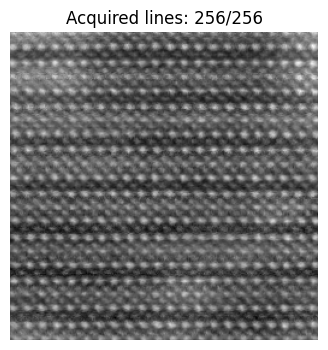

In [22]:
stream = corrupted_image_scan_stream(img_cor)

for _ in range(len(img_cor)):
    frame = next(stream)
    clear_output(wait=True)
    plt.figure(figsize=(4, 4))
    plt.imshow(frame["partial_image"], cmap="gray")
    plt.title(f"Acquired lines: {frame['line_index'] + 1}/{len(img_cor)}")
    plt.axis("off")
    plt.show()
    time.sleep(0.05)
